# Milestone 4 - Module Integration
## Python-Based Cloud Risk Assessment System

| Member | Enrolment no. |
|---|---|
| Ayush Kumar Yadav | E23CSEU0598 |
| Manvendra Negi | E23CSEU1239 |
| Artham Parashar | E23CSEU1695 |
| Mitali Bhatt | E23CSEU2191 |

**Goal of this milestone:** combine the modules built in Milestone 3 into **one working system** and *show* how data flows and how the components affect each other.

**What is new compared with Milestone 3**

| New in Milestone 4 | Where |
|---|---|
| `run_traced()` - runs all layers in order and records, for every hand-off, what went in, what came out, how many items and how long | `pipeline.py` |
| `assess()` - the **single entry point** of the whole system: scan, score, save history, compare with the previous scan, write reports | `pipeline.py` |
| Command line wired to the entry point (`--db`, `--label`) | `cli.py` |
| **Exposure measured on the real resource** (S3: is Block Public Access really off? security group: does it protect something with a public IP?) instead of a fixed yes/no per rule | `rules.py`, `collector.py` |
| **Counted blast radius** (how many users, groups, roles, functions or network interfaces depend on the risky resource) instead of a fixed multiplier | `collector.py`, `scoring.py`, `scoring.yaml` |
| **Exposure and blast-radius graph** - one picture of who can reach what, and what depends on it (in this notebook and in the HTML report) | `exposure_graph.py`, `reporting.py` |
| Hand-written answer key extended with the expected exposure and dependents | `simulation.py`, `evaluation.py` |
| Integration tests, including 11 for exposure and blast radius | `tests/test_integration.py`, `tests/test_exposure_blast.py` |

The other modules are unchanged from Milestone 3 and are only loaded here so the notebook runs by itself in a fresh Colab session.

**How this notebook is organised (the order of the demo):**
* **Part A - each module, then its demo** (Section 3): Configuration -> Authentication -> Collector -> Rule engine -> Risk scoring -> Compliance -> Storage -> Reporting. Every module is shown working **on its own**.
* **Part B - the final integrated working demo** (Sections 4-8): the same modules working **together** through one call, `assess()`, with the data flow, one resource through every layer, the exposure / blast-radius graph, the saved report and four interaction scenarios.

**Contents:** 1 Setup - 2 Architecture and data contracts - **3 Part A: each module and its demo** - **4 Data flow - 5 One resource through every layer - 6 Exposure and blast radius - 7 One call (assess) and the report - 8 How components interact - 9 Integration tests - 10 Summary, limits, viva**

## 1. Setup and loading the modules
Installs libraries, then saves every module as a real `.py` file (`%%writefile`). Most files are the Milestone 3 modules. In this milestone `pipeline.py` and `cli.py` (integration) and the files that carry the exposure / blast-radius context (`models.py`, `config.py`, `collector.py`, `rules.py`, `scoring.py`, `scoring.yaml`, `simulation.py`, `evaluation.py`, `reporting.py`, plus the new `exposure_graph.py`) differ from Milestone 3.

In [1]:
!pip install -q boto3 "moto[s3,iam,ec2,rds,kms,awslambda,cloudtrail,sts]" pydantic PyYAML pandas SQLAlchemy Jinja2 matplotlib rich click pytest freezegun
import os, sys
os.makedirs("project/src/cra", exist_ok=True); os.makedirs("project/config", exist_ok=True); os.makedirs("project/tests", exist_ok=True)
os.chdir("project"); sys.path.insert(0, os.path.abspath("src"))
import platform; print("Python", platform.python_version(), "| folder:", os.getcwd())

Python 3.13.18 | folder: /tmp/nbrun/project


### 1.1 Configuration files

In [2]:
%%writefile config/thresholds.yaml
# Tunable limits used by the rule engine. Change a number here, not in code.
access_key_max_age_days: 90        # IAM-003: active keys older than this are flagged
backup_retention_min_days: 7       # DB-003: databases with fewer backup days are flagged
sensitive_ports: [22, 3389, 3306, 5432]   # NET-001: SSH, RDP, MySQL, PostgreSQL

Writing config/thresholds.yaml


In [3]:
%%writefile config/scoring.yaml
# Risk scoring model (see notebook, Module 5, for the justification of each value).
#   base score  = likelihood (1-5) x impact (1-5) x scale_factor      -> 0..10
#   finding     = base x blast_radius + bonuses, capped at max_score
#   blast       = min(blast_cap, 1 + blast_per_dependent x dependents)   (counted from the account;
#                 rules that cannot count fall back to their fixed default)
#   exposure    = exposure_bonus x exposure_level   (level 1.0 reachable, 0.5 partly, 0 not reachable)
scale_factor: 0.4          # chosen so the worst case 5 x 5 gives exactly 10
exposure_bonus: 1.0        # full bonus when the resource is really reachable from the internet (scaled by exposure_level)
no_logging_bonus: 0.5      # abuse would go unnoticed (logging/monitoring missing)
sensitivity_bonus: 1.0     # resource tagged as holding sensitive data
sensitivity_tag: data-classification
sensitive_labels: [confidential, restricted]
max_score: 10.0
blast_per_dependent: 0.1   # each extra dependent (user, role, function, interface ...) adds this to the blast multiplier
blast_cap: 1.5             # the multiplier never exceeds this
# Severity bands, CVSS-style: Critical >= 9.0, High 7.0-8.9, Medium 4.0-6.9, Low < 4.0
band_critical: 9.0
band_high: 7.0
band_medium: 4.0
# Account posture: 100 - 100 * sum(score^exponent) / (checks_run * 10^exponent * worst_case_factor)
posture_exponent: 1.5      # >1 so a few critical findings cannot hide behind many passes
posture_worst_case_factor: 0.25

Writing config/scoring.yaml


In [4]:
%%writefile config/suppressions.yaml
# Documented exceptions. Every entry MUST have a reason, an approver and an expiry date.
# After the expiry date the exception stops applying and the finding becomes active again.
suppressions:
  - rule_ids: [S3-001, S3-004]
    resource: public-website-assets
    reason: Intentional public static website bucket; contains only non-sensitive public files
    approved_by: Team lead
    expires: 2030-12-31
  - rule_ids: [S3-001, S3-004]
    resource: legacy-public-site
    reason: Old marketing site exception (this one has EXPIRED, so the finding is active again)
    approved_by: Team lead
    expires: 2025-12-31

Writing config/suppressions.yaml


In [5]:
%%writefile config/standards_map.yaml
# standards_map.yaml - maps each rule to external standards (Objective 3 of the project).
#
# SOURCES AND HOW THIS WAS PRODUCED
#   * CIS AWS Foundations Benchmark v3.0.0 : control IDs and titles matched one by one against the
#     benchmark's own control titles, as transcribed in the open-source Prowler file cis_3.0_aws.json.
#     Rules with an empty cis list have NO direct control in v3.0 (for example S3 encryption and versioning).
#   * NIST CSF 1.1 subcategories and ISO/IEC 27001:2022 Annex A controls : chosen by the team from the
#     published frameworks (names/titles taken from Prowler's nist_csf_1.1_aws.json and
#     iso27001_2022_aws.json). These are reasonable mappings, NOT official crosswalks - review before citing.
#   * OWASP Cloud Top 10 : not mapped yet.
#   * Every ID below was checked programmatically to exist in the source files.
#   Control numbers change between benchmark versions, so always cite the version.
frameworks:
  cis_aws_foundations:
    name: CIS Amazon Web Services Foundations Benchmark
    version: 3.0.0
  nist_csf:
    name: NIST Cybersecurity Framework
    version: '1.1'
  iso_27001:
    name: ISO/IEC 27001 Annex A
    version: '2022'
rules:
  S3-001:
    cis_aws_foundations: []
    nist_csf:
    - id: PR.DS-5
      title: Protections against data leaks are implemented.
    - id: PR.AC-3
      title: Remote access is managed.
    iso_27001:
    - id: A.8.3
      title: Access to information and other associated assets should be restricted in accordance with the established t...
  S3-002:
    cis_aws_foundations: []
    nist_csf:
    - id: PR.DS-1
      title: Data-at-rest is protected.
    iso_27001:
    - id: A.8.24
      title: Rules for the effective use of cryptography, including cryptographic key management, should be defined and ...
  S3-003:
    cis_aws_foundations: []
    nist_csf:
    - id: PR.IP-4
      title: Backups of information are conducted, maintained, and tested periodically.
    iso_27001:
    - id: A.8.13
      title: Backup copies of information, software and systems should be maintained and regularly tested in accordance ...
  S3-004:
    cis_aws_foundations:
    - id: 2.1.4
      title: Ensure that S3 Buckets are configured with 'Block public access (bucket settings)'
    nist_csf:
    - id: PR.DS-5
      title: Protections against data leaks are implemented.
    iso_27001:
    - id: A.8.3
      title: Access to information and other associated assets should be restricted in accordance with the established t...
  NET-001:
    cis_aws_foundations:
    - id: '5.2'
      title: Ensure no security groups allow ingress from 0.0.0.0/0 to remote server administration ports
    - id: '5.3'
      title: Ensure no security groups allow ingress from ::/0 to remote server administration ports
    nist_csf:
    - id: PR.AC-5
      title: Network integrity is protected (e.g., network segregation, network segmentation).
    - id: PR.PT-4
      title: Communications and control networks are protected.
    iso_27001:
    - id: A.8.20
      title: Networks and network devices should be secured, managed and controlled to protect information in systems an...
  NET-002:
    cis_aws_foundations:
    - id: '3.7'
      title: Ensure VPC flow logging is enabled in all VPCs
    nist_csf:
    - id: DE.AE-3
      title: Event data are collected and correlated from multiple sources and sensors.
    - id: DE.CM-1
      title: The network is monitored to detect potential cybersecurity events.
    iso_27001:
    - id: A.8.15
      title: Logs that record activities, exceptions, faults and other relevant events should be produced, stored, prote...
  CMP-001:
    cis_aws_foundations:
    - id: '5.6'
      title: Ensure that EC2 Metadata Service only allows IMDSv2
    nist_csf:
    - id: PR.IP-1
      title: A baseline configuration of information technology/industrial control systems is created and maintained inc...
    iso_27001:
    - id: A.8.9
      title: Configurations, including security configurations, of hardware, software, services and networks should be e...
  CMP-002:
    cis_aws_foundations: []
    nist_csf:
    - id: PR.AC-1
      title: Identities and credentials are issued, managed, verified, revoked, and audited for authorized devices, user...
    iso_27001:
    - id: A.5.17
      title: Allocation and management of authentication information should be controlled by a management process, inclu...
  CMP-003:
    cis_aws_foundations:
    - id: 2.2.1
      title: Ensure EBS Volume Encryption is Enabled in all Regions
    nist_csf:
    - id: PR.DS-1
      title: Data-at-rest is protected.
    iso_27001:
    - id: A.8.24
      title: Rules for the effective use of cryptography, including cryptographic key management, should be defined and ...
  DB-001:
    cis_aws_foundations:
    - id: 2.3.3
      title: Ensure that public access is not given to RDS Instance
    nist_csf:
    - id: PR.AC-3
      title: Remote access is managed.
    - id: PR.DS-5
      title: Protections against data leaks are implemented.
    iso_27001:
    - id: A.8.3
      title: Access to information and other associated assets should be restricted in accordance with the established t...
  DB-002:
    cis_aws_foundations:
    - id: 2.3.1
      title: Ensure that encryption is enabled for RDS Instances
    nist_csf:
    - id: PR.DS-1
      title: Data-at-rest is protected.
    iso_27001:
    - id: A.8.24
      title: Rules for the effective use of cryptography, including cryptographic key management, should be defined and ...
  DB-003:
    cis_aws_foundations: []
    nist_csf:
    - id: PR.IP-4
      title: Backups of information are conducted, maintained, and tested periodically.
    iso_27001:
    - id: A.8.13
      title: Backup copies of information, software and systems should be maintained and regularly tested in accordance ...
  IAM-001:
    cis_aws_foundations:
    - id: '1.16'
      title: Ensure IAM policies that allow full "*:*" administrative privileges are not attached
    nist_csf:
    - id: PR.AC-4
      title: Access permissions and authorizations are managed, incorporating the principles of least privilege and sepa...
    iso_27001:
    - id: A.8.2
      title: The allocation and use of privileged access rights should be restricted and managed.
  IAM-002:
    cis_aws_foundations:
    - id: '1.10'
      title: Ensure multi-factor authentication (MFA) is enabled for all IAM users that have a console password
    nist_csf:
    - id: PR.AC-7
      title: Users, devices, and other assets are authenticated (e.g., single-factor, multi-factor) commensurate with th...
    iso_27001:
    - id: A.8.5
      title: Secure authentication technologies and procedures should be implemented based on information access restric...
  IAM-003:
    cis_aws_foundations:
    - id: '1.14'
      title: Ensure access keys are rotated every 90 days or less
    nist_csf:
    - id: PR.AC-1
      title: Identities and credentials are issued, managed, verified, revoked, and audited for authorized devices, user...
    iso_27001:
    - id: A.5.18
      title: Access rights to information and other associated assets should be provisioned, reviewed, modified and remo...
  LOG-001:
    cis_aws_foundations:
    - id: '3.1'
      title: Ensure CloudTrail is enabled in all regions
    nist_csf:
    - id: DE.AE-3
      title: Event data are collected and correlated from multiple sources and sensors.
    - id: DE.CM-1
      title: The network is monitored to detect potential cybersecurity events.
    iso_27001:
    - id: A.8.15
      title: Logs that record activities, exceptions, faults and other relevant events should be produced, stored, prote...
  LOG-002:
    cis_aws_foundations:
    - id: '3.1'
      title: Ensure CloudTrail is enabled in all regions
    - id: '3.2'
      title: Ensure CloudTrail log file validation is enabled
    nist_csf:
    - id: DE.AE-3
      title: Event data are collected and correlated from multiple sources and sensors.
    iso_27001:
    - id: A.8.15
      title: Logs that record activities, exceptions, faults and other relevant events should be produced, stored, prote...
  KMS-001:
    cis_aws_foundations:
    - id: '3.6'
      title: Ensure rotation for customer created symmetric CMKs is enabled
    nist_csf:
    - id: PR.DS-1
      title: Data-at-rest is protected.
    iso_27001:
    - id: A.8.24
      title: Rules for the effective use of cryptography, including cryptographic key management, should be defined and ...
  FN-001:
    cis_aws_foundations: []
    nist_csf:
    - id: PR.AC-4
      title: Access permissions and authorizations are managed, incorporating the principles of least privilege and sepa...
    iso_27001:
    - id: A.8.2
      title: The allocation and use of privileged access rights should be restricted and managed.
  FN-002:
    cis_aws_foundations: []
    nist_csf:
    - id: PR.AC-1
      title: Identities and credentials are issued, managed, verified, revoked, and audited for authorized devices, user...
    iso_27001:
    - id: A.5.17
      title: Allocation and management of authentication information should be controlled by a management process, inclu...

Writing config/standards_map.yaml


### 1.2 Foundation modules (models, config, authentication, simulated cloud) - `models.py`, `config.py` and `simulation.py` gain the exposure / blast-radius fields; `auth.py` is unchanged

In [6]:
%%writefile src/cra/__init__.py
"""Cloud Risk Assessor: a read-only AWS configuration scanner (course project)."""
__version__ = "0.3.0"

Writing src/cra/__init__.py


In [7]:
%%writefile src/cra/models.py
"""Shared data models (pydantic). Every layer exchanges these typed objects, so malformed
API data fails loudly at the boundary instead of silently corrupting results."""
from __future__ import annotations

from typing import Any, Optional

from pydantic import BaseModel, Field


class Resource(BaseModel):
    """One cloud resource in the common, provider-independent inventory format."""
    id: str                      # stable natural identifier (bucket name, sg-id, user name ...)
    type: str                    # s3_bucket, security_group, vpc, ec2_instance, ebs_volume, ...
    region: str = "global"
    name: str = ""
    data: dict[str, Any] = Field(default_factory=dict)   # normalised settings the rules read


class Finding(BaseModel):
    """One failed check on one resource, with evidence, fix, score and standards references."""
    rule_id: str
    title: str
    domain: str
    resource_id: str
    resource_name: str = ""       # human-friendly name (for example a security group's name)
    resource_type: str
    region: str
    evidence: str
    remediation: str
    likelihood: int              # 1-5, from the rule definition
    impact: int                  # 1-5, from the rule definition
    blast: float = 1.0           # blast-radius multiplier (rule default; replaced by the counted value when known)
    exposure: bool = False       # reachable from the public internet at all? (True when exposure_level > 0)
    exposure_level: float = 0.0  # 0 = not reachable, 0.5 = partly, 1.0 = reachable; scales the exposure bonus
    exposure_reason: str = ""    # plain-words explanation of the level (shown in the report)
    dependents: Optional[int] = None    # how many other things depend on / are reached through this resource
    dependent_names: list[str] = Field(default_factory=list)   # who they are (used by the graph)
    no_logging: bool = False     # would abuse go unnoticed?
    sensitivity: Optional[str] = None   # data-classification tag of the resource, if any
    base: float = 0.0            # filled in by scoring
    score: float = 0.0           # 0-10, filled in by scoring
    severity: str = ""           # CRITICAL / HIGH / MEDIUM / LOW
    score_breakdown: dict[str, float] = Field(default_factory=dict)
    suppressed: bool = False
    suppression_reason: str = ""
    standards: dict[str, list[str]] = Field(default_factory=dict)

    @property
    def fingerprint(self) -> str:
        """Stable key used to compare scans over time (rule + resource)."""
        return f"{self.rule_id}|{self.resource_id}"

Writing src/cra/models.py


In [8]:
%%writefile src/cra/config.py
"""Configuration: PyYAML reads the files, pydantic validates them.
Thresholds, scoring weights, suppressions and the standards map all live in config/ so they
can be tuned without touching code."""
from __future__ import annotations

import datetime as dt
from pathlib import Path
from typing import Any

import yaml
from pydantic import BaseModel, Field, field_validator


class Thresholds(BaseModel):
    """Tunable limits used by rules (key age, backup retention, sensitive ports)."""
    access_key_max_age_days: int = Field(90, gt=0)
    backup_retention_min_days: int = Field(7, ge=0)
    sensitive_ports: list[int] = Field(default_factory=lambda: [22, 3389, 3306, 5432])


class ScoringConfig(BaseModel):
    """All weights and bands of the scoring model; defaults match config/scoring.yaml."""
    scale_factor: float = 0.4
    exposure_bonus: float = 1.0
    no_logging_bonus: float = 0.5
    sensitivity_bonus: float = 1.0
    sensitivity_tag: str = "data-classification"
    sensitive_labels: list[str] = Field(default_factory=lambda: ["confidential", "restricted"])
    max_score: float = 10.0
    band_critical: float = 9.0
    band_high: float = 7.0
    band_medium: float = 4.0
    posture_exponent: float = 1.5
    posture_worst_case_factor: float = 0.25
    blast_per_dependent: float = Field(0.1, ge=0)   # blast multiplier grows by this per dependent
    blast_cap: float = Field(1.5, ge=1)             # ... but never above this


class Suppression(BaseModel):
    """A documented exception. Reason, approver and expiry are mandatory."""
    rule_ids: list[str]
    resource: str                       # resource id or name; shell-style wildcards allowed
    reason: str
    approved_by: str
    expires: dt.date

    @field_validator("resource")
    @classmethod
    def resource_must_be_specific(cls, v: str) -> str:
        """Block blanket exceptions such as '*' that would silence every resource with one line."""
        if len(v.strip().replace("*", "").replace("?", "")) < 3:
            raise ValueError("a suppression must name a specific resource (wildcards alone are not allowed)")
        return v.strip()

    @field_validator("rule_ids")
    @classmethod
    def rules_must_exist(cls, v: list[str]) -> list[str]:
        """A typo in a rule id would make the exception silently do nothing - fail loudly instead."""
        from .rules import RULES            # imported here to avoid a circular import
        unknown = [r for r in v if r not in RULES]
        if unknown or not v:
            raise ValueError(f"unknown rule id(s) in suppression: {unknown or 'empty list'}")
        return v

    @field_validator("reason")
    @classmethod
    def reason_must_be_meaningful(cls, v: str) -> str:
        """Reject one-word reasons: an exception must be explained."""
        if len(v.strip()) < 10:
            raise ValueError("a suppression needs a real reason (at least 10 characters)")
        return v

    @field_validator("approved_by")
    @classmethod
    def approver_required(cls, v: str) -> str:
        """Reject exceptions with no named approver."""
        if not v.strip():
            raise ValueError("a suppression needs an approver")
        return v


class Config(BaseModel):
    """Everything the scanner needs, loaded and validated once at start-up."""
    thresholds: Thresholds = Field(default_factory=Thresholds)
    scoring: ScoringConfig = Field(default_factory=ScoringConfig)
    suppressions: list[Suppression] = Field(default_factory=list)
    standards: dict[str, Any] = Field(default_factory=dict)
    source_dir: str = ""


def _read(path: Path) -> dict:
    """Read one YAML file with yaml.safe_load (cannot execute code); a missing file gives {}."""
    if not path.exists():
        return {}
    with path.open(encoding="utf-8") as fh:
        return yaml.safe_load(fh) or {}


def load_config(config_dir: str | Path = "config") -> Config:
    """Load and validate every config file. Missing files fall back to safe defaults;
    invalid values raise a pydantic ValidationError immediately."""
    d = Path(config_dir)
    sup = []
    for item in _read(d / "suppressions.yaml").get("suppressions", []):
        item = dict(item)
        if "rule_id" in item:                      # accept a single id or a list
            item["rule_ids"] = [item.pop("rule_id")]
        sup.append(Suppression(**item))
    return Config(
        thresholds=Thresholds(**_read(d / "thresholds.yaml")),
        scoring=ScoringConfig(**_read(d / "scoring.yaml")),
        suppressions=sup,
        standards=_read(d / "standards_map.yaml"),
        source_dir=str(d),
    )

Writing src/cra/config.py


In [9]:
%%writefile src/cra/auth.py
"""Layer 1 - Authentication & Session.

Goals (Phase 1, objectives 1 and 8): authenticate with least-privilege credentials, never put
secrets in code, and guarantee the scanner can only READ.

Two independent defences:
  1. Permission audit  - static analysis of the identity's IAM policies: does it allow any write?
  2. Read-only guard   - every API call made through ScanSession is checked client-side, and any
                         operation that is not Get*/List*/Describe* is blocked before it is sent.
"""
from __future__ import annotations

import threading
from dataclasses import dataclass, field
from typing import Any, Optional

import boto3
from botocore.config import Config as BotoConfig
from botocore.exceptions import BotoCoreError, ClientError

READ_ONLY_PREFIXES = ("Get", "List", "Describe")
# Retry with adaptive exponential backoff so large accounts that throttle us still work.
RETRY_CONFIG = BotoConfig(retries={"max_attempts": 8, "mode": "adaptive"})


class WriteBlockedError(RuntimeError):
    """Raised when code tries to make a call that could modify the account."""


def mask_account(account_id: str) -> str:
    """Never print a full account id: keep only the last four digits."""
    return "****" + account_id[-4:] if account_id else "unknown"


class ScanSession:
    """A boto3 session wrapper that audits every call and refuses writes.

    Credentials are never passed in code: they come from environment variables, a named
    profile or the provider credential chain (boto3 handles that)."""

    def __init__(self, boto_session: Optional[boto3.Session] = None,
                 regions: Optional[list[str]] = None, guard: bool = True):
        """Create the guarded session; credentials come from boto3's normal chain, never from our code."""
        self.session = boto_session or boto3.Session()
        self.regions = list(regions or ["us-east-1"])
        self.guard = guard
        self.calls: list[str] = []          # audit log: "service:Operation" for every call made
        self.blocked: list[str] = []        # operations the guard refused
        self.notes: list[str] = []          # "could not check ..." messages from collectors
        self._deny: set[str] = set()
        self._lock = threading.Lock()
        # 'before-call' fires for every API operation of every client made from this session
        self.session.events.register("before-call", self._before_call)

    # ---- the guard -------------------------------------------------------------------------
    def _before_call(self, model, **kwargs):
        """boto3 'before-call' hook: log every API call and refuse anything that is not Get/List/Describe."""
        service = model.service_model.service_name
        op = model.name
        with self._lock:
            self.calls.append(f"{service}:{op}")
        if service in self._deny:
            raise ClientError({"Error": {"Code": "AccessDenied",
                                         "Message": "simulated denied service"}}, op)
        if self.guard and not op.startswith(READ_ONLY_PREFIXES):
            with self._lock:
                self.blocked.append(f"{service}:{op}")
            raise WriteBlockedError(f"Blocked non read-only call {service}:{op}")

    def simulate_denied(self, *services: str) -> None:
        """Testing aid: make every call to these services fail with AccessDenied."""
        self._deny.update(services)

    def note(self, message: str) -> None:
        """Record a 'could not check ...' message (thread-safe) for the report."""
        with self._lock:
            self.notes.append(message)

    def client(self, service: str, region: Optional[str] = None):
        """Return a boto3 client from the guarded session, with adaptive retries for rate limiting."""
        return self.session.client(service, region_name=region or self.regions[0],
                                   config=RETRY_CONFIG)

    # ---- identity --------------------------------------------------------------------------
    def identity(self) -> dict[str, str]:
        """Who are we? (sts:GetCallerIdentity is a read-only call). Account id is masked."""
        try:
            who = self.client("sts").get_caller_identity()
        except (ClientError, BotoCoreError) as exc:
            raise SystemExit(f"Could not authenticate: {exc}")
        return {"account": mask_account(who["Account"]), "arn_type": who["Arn"].split(":")[-1].split("/")[0]}

    @property
    def read_only_proof(self) -> dict[str, Any]:
        """Evidence for the report: how many calls were made and that none were writes."""
        ops = sorted({c.split(":")[1] for c in self.calls})
        return {"total_calls": len(self.calls), "distinct_operations": len(ops),
                "blocked_writes": len(self.blocked),
                "all_read_only": all(o.startswith(READ_ONLY_PREFIXES) for o in ops)}


# ---- permission audit ------------------------------------------------------------------------
def _is_read_action(action: str) -> bool:
    """True if an IAM action name (e.g. 's3:GetObject') is a pure read; '*' is never read-only."""
    if action == "*":
        return False
    name = action.partition(":")[2]
    return name.startswith(READ_ONLY_PREFIXES)


def find_write_actions(policy_document: dict) -> list[str]:
    """Return every action a policy ALLOWS that is not a pure read (Get/List/Describe).
    Wildcards such as '*' or 's3:*' count as write-capable. NotAction cannot be proven safe."""
    statements = policy_document.get("Statement", [])
    if isinstance(statements, dict):
        statements = [statements]
    found: set[str] = set()
    for st in statements:
        if st.get("Effect") != "Allow":
            continue
        if "NotAction" in st:
            found.add("NotAction (cannot prove read-only)")
            continue
        actions = st.get("Action", [])
        for a in ([actions] if isinstance(actions, str) else actions):
            if not _is_read_action(a):
                found.add(a)
    return sorted(found)


@dataclass
class PermissionReport:
    """Result of the static permission audit of one role."""
    role: str
    verdict: str                                  # READ_ONLY | WRITE_CAPABLE | UNKNOWN
    write_actions: list[str] = field(default_factory=list)
    policies: list[str] = field(default_factory=list)


def audit_role_permissions(iam_client, role_name: str) -> PermissionReport:
    """Static analysis of a role's attached and inline policies (read-only IAM calls)."""
    try:
        docs, names = [], []
        for pol in iam_client.list_attached_role_policies(RoleName=role_name)["AttachedPolicies"]:
            version = iam_client.get_policy(PolicyArn=pol["PolicyArn"])["Policy"]["DefaultVersionId"]
            docs.append(iam_client.get_policy_version(PolicyArn=pol["PolicyArn"],
                                                      VersionId=version)["PolicyVersion"]["Document"])
            names.append(pol["PolicyName"])
        for name in iam_client.list_role_policies(RoleName=role_name)["PolicyNames"]:
            docs.append(iam_client.get_role_policy(RoleName=role_name, PolicyName=name)["PolicyDocument"])
            names.append(f"{name} (inline)")
    except ClientError as exc:
        return PermissionReport(role_name, "UNKNOWN", [f"could not read policies: {exc.response['Error']['Code']}"])
    writes = sorted({a for d in docs for a in find_write_actions(d)})
    return PermissionReport(role_name, "WRITE_CAPABLE" if writes else "READ_ONLY", writes, names)

Writing src/cra/auth.py


In [10]:
%%writefile src/cra/simulation.py
"""A fake AWS account (moto) with deliberately planted flaws AND planted good resources.

The expected results are written down here by hand, from the design of the account - they are NOT
produced by running the scanner. evaluation.py then compares scanner output to this ground truth.
No real AWS account, credentials or money are involved: moto answers the same boto3 calls locally."""
from __future__ import annotations

import io
import json
import os
import zipfile
from contextlib import contextmanager
from dataclasses import dataclass, field
from datetime import datetime, timedelta, timezone

SIM_NOW = datetime(2026, 10, 13, 12, 0, tzinfo=timezone.utc)   # fixed "today" so results are repeatable
SIM_TODAY = SIM_NOW.date()
REGIONS = ["us-east-1", "eu-west-1"]

ADMIN_DOC = {"Version": "2012-10-17", "Statement": [{"Effect": "Allow", "Action": "*", "Resource": "*"}]}
S3_DOC = {"Version": "2012-10-17", "Statement": [{"Effect": "Allow", "Action": ["s3:GetObject"], "Resource": "*"}]}
TRUST = {"Version": "2012-10-17", "Statement": [{"Effect": "Allow",
         "Principal": {"Service": "lambda.amazonaws.com"}, "Action": "sts:AssumeRole"}]}


@dataclass
class GroundTruth:
    """The hand-written answer key for the planted account."""
    active: set[str] = field(default_factory=set)        # "RULE|resource" that MUST be reported
    suppressed: set[str] = field(default_factory=set)    # planted but covered by a valid exception
    healthy: list[str] = field(default_factory=list)     # human-readable list of planted GOOD resources
    # hand-written expectation for exposure and blast radius: "RULE|resource" -> (exposure_level, dependents)
    context: dict[str, tuple[float, int | None]] = field(default_factory=dict)

    def expect(self, rule: str, resource: str, exposure: float | None = None, dependents: int | None = None) -> None:
        """Record that rule 'rule' must report resource 'resource' (optionally with the expected exposure
        level and number of dependents, so the measured context can be checked too)."""
        self.active.add(f"{rule}|{resource}")
        if exposure is not None:
            self.context[f"{rule}|{resource}"] = (exposure, dependents)


def _zip() -> bytes:
    """Build a tiny in-memory Lambda deployment package."""
    buf = io.BytesIO()
    with zipfile.ZipFile(buf, "w") as z:
        z.writestr("lambda_function.py", "def handler(e, c):\n    return 1\n")
    return buf.getvalue()


@contextmanager
def fake_aws():
    """Context manager: everything boto3 does inside this block hits moto, not the internet."""
    os.environ.update(AWS_ACCESS_KEY_ID="testing", AWS_SECRET_ACCESS_KEY="testing",
                      AWS_SECURITY_TOKEN="testing", AWS_SESSION_TOKEN="testing", AWS_DEFAULT_REGION="us-east-1")
    from moto import mock_aws
    with mock_aws():
        yield


def build_account(boto3, truth: GroundTruth | None = None) -> GroundTruth:
    """Create the planted account inside an active fake_aws() block and return the ground truth."""
    from freezegun import freeze_time
    t = truth or GroundTruth()
    e1, e2 = REGIONS
    s3 = boto3.client("s3", region_name=e1)
    iam = boto3.client("iam", region_name=e1)

    # ---------------- S3 ----------------
    def bucket(name, acl="private", enc=False, ver=False, bpa=False, tag=None):
        """Create one S3 bucket with the requested (mis)configuration."""
        s3.create_bucket(Bucket=name)
        if acl != "private": s3.put_bucket_acl(Bucket=name, ACL=acl)
        if enc: s3.put_bucket_encryption(Bucket=name, ServerSideEncryptionConfiguration={
            "Rules": [{"ApplyServerSideEncryptionByDefault": {"SSEAlgorithm": "AES256"}}]})
        if ver: s3.put_bucket_versioning(Bucket=name, VersioningConfiguration={"Status": "Enabled"})
        if bpa: s3.put_public_access_block(Bucket=name, PublicAccessBlockConfiguration=dict(
            BlockPublicAcls=True, IgnorePublicAcls=True, BlockPublicPolicy=True, RestrictPublicBuckets=True))
        if tag: s3.put_bucket_tagging(Bucket=name, Tagging={"TagSet": [{"Key": "data-classification", "Value": tag}]})

    bucket("prod-customer-data", acl="public-read", tag="confidential")      # everything wrong + sensitive
    for r in ("S3-001", "S3-002", "S3-003", "S3-004"):                      # public ACL, Block Public Access off
        t.expect(r, "prod-customer-data", 1.0 if r in ("S3-001", "S3-004") else None)
    bucket("secure-logs-bucket", enc=True, ver=True, bpa=True); t.healthy.append("bucket secure-logs-bucket")
    bucket("team-notes", enc=True, bpa=True); t.expect("S3-003", "team-notes")
    bucket("public-website-assets", acl="public-read", enc=True, ver=True)   # valid, unexpired exception
    t.suppressed |= {"S3-001|public-website-assets", "S3-004|public-website-assets"}
    bucket("legacy-public-site", acl="public-read", enc=True, ver=True)      # exception EXPIRED -> active
    t.expect("S3-001", "legacy-public-site", 1.0); t.expect("S3-004", "legacy-public-site", 1.0)

    # ---------------- network / compute / db per region ----------------
    for region in REGIONS:
        ec2 = boto3.client("ec2", region_name=region)
        for v in ec2.describe_vpcs()["Vpcs"]:                      # every default VPC lacks flow logs
            if v["IsDefault"]: t.expect("NET-002", v["VpcId"])

    ec2 = boto3.client("ec2", region_name=e1)
    vpc_ok = ec2.create_vpc(CidrBlock="10.10.0.0/16")["Vpc"]["VpcId"]
    ec2.create_flow_logs(ResourceIds=[vpc_ok], ResourceType="VPC", TrafficType="ALL",
                         LogDestinationType="s3", LogDestination="arn:aws:s3:::secure-logs-bucket")
    t.healthy.append(f"vpc {vpc_ok} with flow logs")
    vpc_bad = ec2.create_vpc(CidrBlock="10.20.0.0/16")["Vpc"]["VpcId"]; t.expect("NET-002", vpc_bad)
    subnet_ok = ec2.create_subnet(VpcId=vpc_ok, CidrBlock="10.10.1.0/24")["Subnet"]["SubnetId"]

    def sg(client, name, vpc, perms):
        """Create a security group (optionally with ingress rules) and return its id."""
        gid = client.create_security_group(GroupName=name, Description=name, VpcId=vpc)["GroupId"]
        if perms: client.authorize_security_group_ingress(GroupId=gid, IpPermissions=perms)
        return gid

    world = [{"CidrIp": "0.0.0.0/0"}]
    # Exposure context planted on purpose (the expected levels are written down here, by hand):
    #   open-ssh     -> protects an instance WITH a public IP          -> reachable        (1.0), 1 dependent
    #   open-all     -> protects a network interface with NO public IP -> partly           (0.5), 1 dependent
    #   open-rdp-v6  -> attached to nothing                            -> not reachable    (0.0), 0 dependents
    sg_ssh = sg(ec2, "open-ssh", vpc_ok, [dict(IpProtocol="tcp", FromPort=22, ToPort=22, IpRanges=world)])
    sg_all = sg(ec2, "open-all", vpc_ok, [dict(IpProtocol="-1", IpRanges=world)])
    sg_rdp = sg(ec2, "open-rdp-v6", vpc_ok, [dict(IpProtocol="tcp", FromPort=3389, ToPort=3389,
                                                 Ipv6Ranges=[{"CidrIpv6": "::/0"}])])
    t.expect("NET-001", sg_ssh, 1.0, 1); t.expect("NET-001", sg_all, 0.5, 1); t.expect("NET-001", sg_rdp, 0.0, 0)
    private_nic = ec2.create_network_interface(SubnetId=subnet_ok, Groups=[sg_all])["NetworkInterface"]["NetworkInterfaceId"]
    sg(ec2, "web-https", vpc_ok, [dict(IpProtocol="tcp", FromPort=443, ToPort=443, IpRanges=world)])
    t.healthy.append("security group web-https (443 open is allowed)")
    sg(ec2, "office-ssh", vpc_ok, [dict(IpProtocol="tcp", FromPort=22, ToPort=22, IpRanges=[{"CidrIp": "203.0.113.0/24"}])])
    t.healthy.append("security group office-ssh (22 from one trusted range)")

    ami = ec2.describe_images()["Images"][0]["ImageId"]
    bad = ec2.run_instances(ImageId=ami, MinCount=1, MaxCount=1, MetadataOptions={"HttpTokens": "optional"},
                            NetworkInterfaces=[dict(DeviceIndex=0, SubnetId=subnet_ok, Groups=[sg_ssh],
                                                    AssociatePublicIpAddress=True)],
                            UserData="#!/bin/bash\nDB_PASSWORD=hunter2\n")["Instances"][0]["InstanceId"]
    good = ec2.run_instances(ImageId=ami, MinCount=1, MaxCount=1, MetadataOptions={"HttpTokens": "required"},
                             BlockDeviceMappings=[{"DeviceName": "/dev/sda1", "Ebs": {"VolumeSize": 8, "Encrypted": True}}]
                             )["Instances"][0]["InstanceId"]
    t.expect("CMP-001", bad); t.expect("CMP-002", bad); t.healthy.append(f"instance {good}")
    vols = {v["Attachments"][0]["InstanceId"]: v for v in ec2.describe_volumes()["Volumes"] if v["Attachments"]}
    t.expect("CMP-003", vols[bad]["VolumeId"])
    assert vols[good]["Encrypted"], "moto did not honour the encrypted root volume"

    ec2b = boto3.client("ec2", region_name=e2)
    vpc_eu = ec2b.describe_vpcs()["Vpcs"][0]["VpcId"]
    t.expect("NET-001", sg(ec2b, "eu-open-mysql", vpc_eu, [dict(IpProtocol="tcp", FromPort=3306, ToPort=3306, IpRanges=world)]),
             0.0, 0)                                                # attached to nothing -> not reachable
    t.expect("CMP-003", ec2b.create_volume(AvailabilityZone=e2 + "a", Size=8, Encrypted=False)["VolumeId"])

    rds = boto3.client("rds", region_name=e1)
    rds.create_db_instance(DBInstanceIdentifier="db-bad", DBInstanceClass="db.t3.micro", Engine="mysql",
                           MasterUsername="admin", MasterUserPassword="Passw0rd12345", AllocatedStorage=20,
                           PubliclyAccessible=True, StorageEncrypted=False, BackupRetentionPeriod=0)
    for r in ("DB-001", "DB-002", "DB-003"): t.expect(r, "db-bad", 1.0 if r == "DB-001" else None)
    rds.create_db_instance(DBInstanceIdentifier="db-good", DBInstanceClass="db.t3.micro", Engine="mysql",
                           MasterUserPassword="Passw0rd12345", MasterUsername="admin", AllocatedStorage=20,
                           PubliclyAccessible=False, StorageEncrypted=True, BackupRetentionPeriod=14)
    t.healthy.append("rds db-good")

    # ---------------- IAM ----------------
    iam.create_policy(PolicyName="AllowEverything", PolicyDocument=json.dumps(ADMIN_DOC))
    t.expect("IAM-001", "AllowEverything", 0.0, 4)       # blast radius: used by role-admin, user carol, groups ops-team and dev-team
    iam.create_policy(PolicyName="ReadS3Only", PolicyDocument=json.dumps(S3_DOC)); t.healthy.append("policy ReadS3Only")
    for u in ("alice", "bob", "carol"): iam.create_user(UserName=u)
    iam.create_login_profile(UserName="alice", Password="Passw0rd!x23")
    iam.create_login_profile(UserName="bob", Password="Passw0rd!x23")
    t.expect("IAM-002", "alice")
    mfa = iam.create_virtual_mfa_device(VirtualMFADeviceName="bob-mfa")["VirtualMFADevice"]["SerialNumber"]
    iam.enable_mfa_device(UserName="bob", SerialNumber=mfa, AuthenticationCode1="123456", AuthenticationCode2="654321")
    with freeze_time(SIM_NOW - timedelta(days=200)):
        iam.create_access_key(UserName="alice")
    t.expect("IAM-003", "alice")
    with freeze_time(SIM_NOW - timedelta(days=10)):
        iam.create_access_key(UserName="carol")
    t.healthy += ["user bob (console + MFA)", "user carol (new key, no console)"]

    # ---------------- KMS ----------------
    kms = boto3.client("kms", region_name=e1)
    k_off = kms.create_key(Description="rotation-off")["KeyMetadata"]["KeyId"]; t.expect("KMS-001", k_off)
    k_on = kms.create_key(Description="rotation-on")["KeyMetadata"]["KeyId"]
    kms.enable_key_rotation(KeyId=k_on); t.healthy.append("kms key with rotation")
    # Simulator quirk: moto reports its built-in EBS default key as CUSTOMER-managed (real AWS says AWS-managed),
    # so a correct scanner must flag it here. Listed explicitly so the ground truth stays honest.
    for k in kms.list_keys()["Keys"]:
        if k["KeyId"] not in (k_off, k_on):
            meta = kms.describe_key(KeyId=k["KeyId"])["KeyMetadata"]
            if meta["KeyManager"] == "CUSTOMER": t.expect("KMS-001", k["KeyId"])

    # ---------------- Lambda ----------------
    iam.create_role(RoleName="role-admin", AssumeRolePolicyDocument=json.dumps(TRUST))
    admin_arn = [p["Arn"] for p in iam.list_policies(Scope="Local")["Policies"] if p["PolicyName"] == "AllowEverything"][0]
    s3_arn = [p["Arn"] for p in iam.list_policies(Scope="Local")["Policies"] if p["PolicyName"] == "ReadS3Only"][0]
    iam.attach_role_policy(RoleName="role-admin", PolicyArn=admin_arn)
    iam.attach_user_policy(UserName="carol", PolicyArn=admin_arn)           # three more dependents of the admin policy
    for grp in ("ops-team", "dev-team"):
        iam.create_group(GroupName=grp); iam.attach_group_policy(GroupName=grp, PolicyArn=admin_arn)
    iam.create_role(RoleName="role-small", AssumeRolePolicyDocument=json.dumps(TRUST))
    iam.attach_role_policy(RoleName="role-small", PolicyArn=s3_arn)
    lam = boto3.client("lambda", region_name=e1)
    mk = lambda name, role, env: lam.create_function(
        FunctionName=name, Runtime="python3.12", Role=f"arn:aws:iam::123456789012:role/{role}",
        Handler="lambda_function.handler", Code={"ZipFile": _zip()}, Environment={"Variables": env})
    mk("fn-admin", "role-admin", {"DB_PASSWORD": "x", "LOG_LEVEL": "info"})
    t.expect("FN-001", "fn-admin", 0.0, 1); t.expect("FN-002", "fn-admin")   # the admin role runs only this one function
    mk("fn-ok", "role-small", {"LOG_LEVEL": "info"}); t.healthy.append("lambda fn-ok")

    # ---------------- CloudTrail ----------------
    ct = boto3.client("cloudtrail", region_name=e1)
    ct.create_trail(Name="trail-weak", S3BucketName="secure-logs-bucket", IsMultiRegionTrail=False)
    t.expect("LOG-002", "trail-weak")
    ct.create_trail(Name="trail-strong", S3BucketName="secure-logs-bucket", IsMultiRegionTrail=True,
                    EnableLogFileValidation=True)
    t.healthy.append("trail-strong")
    return t

Writing src/cra/simulation.py


### 1.3 Processing layers (collector, rules, scoring, compliance) - collector, rules and scoring now measure exposure and blast radius; compliance is unchanged

In [11]:
%%writefile src/cra/collector.py
"""Layer 2 - Collector.

Calls the provider's read-only APIs (through the guarded ScanSession) and converts every answer
into the common Resource format. Design rules:
  * only list/get/describe calls; the session guard enforces it
  * paginate everything (real accounts return results in pages)
  * scan regions in parallel (thread pool): scan time is network I/O, not CPU
  * a denied or failing call is recorded as a note and the scan continues ("could not check");
    unknown values are stored as None so rules never turn "unknown" into a false finding
  * never store secrets: user-data and environment-variable VALUES are inspected in memory only,
    and just a true/false result (or variable NAMES) is kept
"""
from __future__ import annotations

import re
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from typing import Any, Callable, Optional

from botocore.exceptions import BotoCoreError, ClientError

from .auth import ScanSession
from .models import Resource

# Built-in patterns used to spot secrets in startup scripts (values are never stored).
SECRET_ASSIGNMENT = re.compile(
    r"(password|passwd|secret|token|api[_-]?key|access[_-]?key|private[_-]?key)\s*[=:]", re.I)
SECRET_NAME = re.compile(r"(password|passwd|secret|token|api[_-]?key|access[_-]?key|private[_-]?key|_key$)", re.I)


def safe(ss: ScanSession, label: str, fn: Callable[[], Any], default: Any = None) -> Any:
    """Run one read-only call; on failure note it and return a default instead of crashing."""
    try:
        return fn()
    except ClientError as exc:
        ss.note(f"Could not check {label}: {exc.response['Error']['Code']}")
    except BotoCoreError as exc:
        ss.note(f"Could not check {label}: {type(exc).__name__}")
    return default


def _pages(client, operation: str, key: str, **kwargs) -> list:
    """Collect ALL results of a paginated AWS list call (real accounts return results in pages)."""
    out: list = []
    for page in client.get_paginator(operation).paginate(**kwargs):
        out += page.get(key, [])
    return out


def _is_admin_document(doc: dict) -> bool:
    """True if a policy Allows Action '*' on Resource '*' (full administrator)."""
    statements = doc.get("Statement", [])
    statements = [statements] if isinstance(statements, dict) else statements
    as_list = lambda v: v if isinstance(v, list) else [v]
    return any(s.get("Effect") == "Allow" and "*" in as_list(s.get("Action", []))
               and "*" in as_list(s.get("Resource", [])) for s in statements)


# ------------------------------------------------------------------------------ S3 (global)
def collect_s3(ss: ScanSession, sensitivity_tag: str = "data-classification") -> list[Resource]:
    """S3 buckets: public ACL, default encryption, versioning, Block Public Access and data-classification tag."""
    out: list[Resource] = []
    s3 = ss.client("s3")
    for b in safe(ss, "S3 list buckets", lambda: s3.list_buckets()["Buckets"], []):
        name = b["Name"]
        loc = safe(ss, f"S3 location {name}",
                   lambda: s3.get_bucket_location(Bucket=name)["LocationConstraint"], "unknown")
        region = "us-east-1" if loc in (None, "unknown") else ("eu-west-1" if loc == "EU" else loc)
        c = ss.client("s3", region)                      # talk to the bucket in its own region

        def public_acl():
            """True if the bucket ACL grants access to AllUsers (anyone) or AuthenticatedUsers (any AWS account)."""
            uris = [g["Grantee"].get("URI", "") for g in c.get_bucket_acl(Bucket=name)["Grants"]]
            return any(u.endswith(("/global/AllUsers", "/global/AuthenticatedUsers")) for u in uris)

        def encrypted():
            """True if default encryption is configured; False if AWS says none is set."""
            try:
                c.get_bucket_encryption(Bucket=name)
                return True
            except ClientError as e:
                if e.response["Error"]["Code"] == "ServerSideEncryptionConfigurationNotFoundError":
                    return False
                raise

        def versioning():
            """True if bucket versioning is Enabled."""
            return c.get_bucket_versioning(Bucket=name).get("Status") == "Enabled"

        def block_public():
            """True only if all four Block Public Access settings are on."""
            try:
                cfg = c.get_public_access_block(Bucket=name)["PublicAccessBlockConfiguration"]
                return all(cfg.values())
            except ClientError as e:
                if e.response["Error"]["Code"] == "NoSuchPublicAccessBlockConfiguration":
                    return False
                raise

        def tag():
            """Return the data-classification tag value, or None if the bucket has no such tag."""
            try:
                tags = {t["Key"]: t["Value"] for t in c.get_bucket_tagging(Bucket=name)["TagSet"]}
                return tags.get(sensitivity_tag)
            except ClientError as e:
                if e.response["Error"]["Code"] == "NoSuchTagSet":
                    return None
                raise

        out.append(Resource(id=name, type="s3_bucket", region=region, name=name, data=dict(
            public_acl=safe(ss, f"bucket ACL {name}", public_acl),
            encrypted=safe(ss, f"bucket encryption {name}", encrypted),
            versioning=safe(ss, f"bucket versioning {name}", versioning),
            block_public=safe(ss, f"bucket public access block {name}", block_public),
            sensitivity=safe(ss, f"bucket tags {name}", tag))))
    return out


# ------------------------------------------------------------------------------ IAM (global)
def collect_iam(ss: ScanSession, now: Optional[datetime] = None) -> list[Resource]:
    """IAM: customer-managed policies (admin?) and users (console access, MFA, access-key ages)."""
    now = now or datetime.now(timezone.utc)
    out: list[Resource] = []
    iam = ss.client("iam")

    for pol in safe(ss, "IAM policies", lambda: _pages(iam, "list_policies", "Policies", Scope="Local"), []):
        def admin():
            """True if the policy's default version allows Action '*' on Resource '*'."""
            doc = iam.get_policy_version(PolicyArn=pol["Arn"],
                                         VersionId=pol["DefaultVersionId"])["PolicyVersion"]["Document"]
            return _is_admin_document(doc)
        def dependents():
            """Who uses this policy: attached users, groups and roles (names only). Used for the blast radius."""
            names: list[str] = []
            for page in iam.get_paginator("list_entities_for_policy").paginate(PolicyArn=pol["Arn"]):
                names += [f"user:{x['UserName']}" for x in page.get("PolicyUsers", [])]
                names += [f"group:{x['GroupName']}" for x in page.get("PolicyGroups", [])]
                names += [f"role:{x['RoleName']}" for x in page.get("PolicyRoles", [])]
            return sorted(names)

        is_admin = safe(ss, f"policy {pol['PolicyName']}", admin)
        data = dict(admin=is_admin)
        if is_admin is not False:               # only an admin (or unknown) policy needs its blast radius counted
            data["dependents"] = safe(ss, f"who uses policy {pol['PolicyName']}", dependents)
        out.append(Resource(id=pol["PolicyName"], type="iam_policy", name=pol["PolicyName"], data=data))

    for u in safe(ss, "IAM users", lambda: _pages(iam, "list_users", "Users"), []):
        name = u["UserName"]

        def console():
            """True if the user has a console password (login profile)."""
            try:
                iam.get_login_profile(UserName=name)
                return True
            except ClientError as e:
                if e.response["Error"]["Code"] == "NoSuchEntity":
                    return False
                raise

        def keys():
            """Access keys as masked id + active flag + age in days (the key secret is never read)."""
            res = []
            for k in iam.list_access_keys(UserName=name)["AccessKeyMetadata"]:
                res.append({"id": k["AccessKeyId"][:4] + "****", "active": k["Status"] == "Active",
                            "age_days": (now - k["CreateDate"]).days})
            return res

        mfa = safe(ss, f"MFA for {name}", lambda: bool(iam.list_mfa_devices(UserName=name)["MFADevices"]))
        out.append(Resource(id=name, type="iam_user", name=name, data=dict(
            console_access=safe(ss, f"login profile {name}", console), mfa=mfa,
            access_keys=safe(ss, f"access keys {name}", keys))))
    return out


# ------------------------------------------------------------------------------ EC2 / VPC
def collect_ec2(ss: ScanSession, region: str) -> list[Resource]:
    """EC2/VPC/EBS in one region: security groups, VPC flow logs, instances (IMDS, user-data secrets), volumes."""
    out: list[Resource] = []
    ec2 = ss.client("ec2", region)

    # Which security groups protect something, and does any of it have a public IP? (read-only describe call)
    enis = safe(ss, f"network interfaces in {region}",
                lambda: _pages(ec2, "describe_network_interfaces", "NetworkInterfaces"))
    sg_users: dict[str, set[str]] = {}
    sg_public: dict[str, bool] = {}
    for ni in enis or []:
        label = (ni.get("Attachment") or {}).get("InstanceId") or ni["NetworkInterfaceId"]
        has_public_ip = bool((ni.get("Association") or {}).get("PublicIp"))
        for g in ni.get("Groups", []):
            sg_users.setdefault(g["GroupId"], set()).add(label)
            sg_public[g["GroupId"]] = sg_public.get(g["GroupId"], False) or has_public_ip

    for sg in safe(ss, f"security groups in {region}",
                   lambda: _pages(ec2, "describe_security_groups", "SecurityGroups"), []):
        ranges = []                                      # (from_port, to_port) open to the world
        for perm in sg.get("IpPermissions", []):
            world = any(r.get("CidrIp") == "0.0.0.0/0" for r in perm.get("IpRanges", [])) or \
                any(r.get("CidrIpv6") == "::/0" for r in perm.get("Ipv6Ranges", []))
            if world:
                if perm.get("IpProtocol") == "-1" or "FromPort" not in perm:
                    ranges.append((0, 65535))            # all traffic
                else:
                    ranges.append((perm["FromPort"], perm["ToPort"]))
        out.append(Resource(id=sg["GroupId"], type="security_group", region=region, name=sg["GroupName"],
                            data=dict(open_ranges=ranges,
                                      dependents=None if enis is None else sorted(sg_users.get(sg["GroupId"], ())),
                                      public_reach=None if enis is None else sg_public.get(sg["GroupId"], False))))

    flow_vpcs = safe(ss, f"flow logs in {region}",
                     lambda: {f["ResourceId"] for f in _pages(ec2, "describe_flow_logs", "FlowLogs")})
    for vpc in safe(ss, f"VPCs in {region}", lambda: _pages(ec2, "describe_vpcs", "Vpcs"), []):
        out.append(Resource(id=vpc["VpcId"], type="vpc", region=region,
                            name="default VPC" if vpc.get("IsDefault") else vpc["VpcId"],
                            data=dict(is_default=bool(vpc.get("IsDefault")),
                                      flow_logs=None if flow_vpcs is None else vpc["VpcId"] in flow_vpcs)))

    reservations = safe(ss, f"instances in {region}",
                        lambda: _pages(ec2, "describe_instances", "Reservations"), [])
    for res in reservations:
        for inst in res["Instances"]:
            if inst["State"]["Name"] == "terminated":
                continue
            iid = inst["InstanceId"]

            def secret_in_user_data():
                """Inspect user-data in memory for password/token-style text; only a True/False is kept."""
                val = ec2.describe_instance_attribute(InstanceId=iid, Attribute="userData")\
                    .get("UserData", {}).get("Value")
                if not val:
                    return False
                import base64
                return bool(SECRET_ASSIGNMENT.search(base64.b64decode(val).decode("utf-8", "ignore")))

            out.append(Resource(id=iid, type="ec2_instance", region=region, name=iid, data=dict(
                imds_v2_required=inst.get("MetadataOptions", {}).get("HttpTokens") == "required",
                secret_in_user_data=safe(ss, f"user data of {iid}", secret_in_user_data))))

    for vol in safe(ss, f"volumes in {region}", lambda: _pages(ec2, "describe_volumes", "Volumes"), []):
        out.append(Resource(id=vol["VolumeId"], type="ebs_volume", region=region, name=vol["VolumeId"],
                            data=dict(encrypted=bool(vol.get("Encrypted")))))
    return out


# ------------------------------------------------------------------------------ RDS
def collect_rds(ss: ScanSession, region: str) -> list[Resource]:
    """RDS instances in one region: public access, storage encryption, backup retention."""
    rds = ss.client("rds", region)
    dbs = safe(ss, f"RDS instances in {region}", lambda: _pages(rds, "describe_db_instances", "DBInstances"), [])
    return [Resource(id=d["DBInstanceIdentifier"], type="rds_instance", region=region,
                     name=d["DBInstanceIdentifier"],
                     data=dict(public=bool(d.get("PubliclyAccessible")),
                               encrypted=bool(d.get("StorageEncrypted")),
                               backup_days=int(d.get("BackupRetentionPeriod", 0)))) for d in dbs]


# ------------------------------------------------------------------------------ KMS
def collect_kms(ss: ScanSession, region: str) -> list[Resource]:
    """Customer-managed, enabled, symmetric KMS keys and whether automatic rotation is on."""
    kms = ss.client("kms", region)
    out: list[Resource] = []
    for k in safe(ss, f"KMS keys in {region}", lambda: _pages(kms, "list_keys", "Keys"), []):
        meta = safe(ss, f"KMS key {k['KeyId'][:8]}", lambda: kms.describe_key(KeyId=k["KeyId"])["KeyMetadata"])
        # Rotation applies only to enabled, customer-managed, symmetric keys.
        if not meta or meta.get("KeyManager") != "CUSTOMER" or meta.get("KeyState") != "Enabled" \
                or meta.get("KeySpec", "SYMMETRIC_DEFAULT") != "SYMMETRIC_DEFAULT":
            continue
        rot = safe(ss, f"KMS rotation {k['KeyId'][:8]}",
                   lambda: kms.get_key_rotation_status(KeyId=k["KeyId"])["KeyRotationEnabled"])
        out.append(Resource(id=k["KeyId"], type="kms_key", region=region, name=meta.get("Description") or k["KeyId"],
                            data=dict(manager="CUSTOMER", rotation=rot)))
    return out


# ------------------------------------------------------------------------------ Lambda
def collect_lambda(ss: ScanSession, region: str) -> list[Resource]:
    """Lambda functions: is the execution role an administrator, and which env-var NAMES look like secrets."""
    lam, iam = ss.client("lambda", region), ss.client("iam")
    admin_cache: dict[str, Optional[bool]] = {}

    def role_is_admin(role_name: str) -> Optional[bool]:
        """Is this role an administrator? Cached per role; None if it could not be checked."""
        if role_name not in admin_cache:
            def check():
                """Read the role's attached and inline policies and test them for full admin."""
                docs = []
                for p in iam.list_attached_role_policies(RoleName=role_name)["AttachedPolicies"]:
                    v = iam.get_policy(PolicyArn=p["PolicyArn"])["Policy"]["DefaultVersionId"]
                    docs.append(iam.get_policy_version(PolicyArn=p["PolicyArn"], VersionId=v)["PolicyVersion"]["Document"])
                for n in iam.list_role_policies(RoleName=role_name)["PolicyNames"]:
                    docs.append(iam.get_role_policy(RoleName=role_name, PolicyName=n)["PolicyDocument"])
                return any(_is_admin_document(d) for d in docs)
            admin_cache[role_name] = safe(ss, f"role {role_name}", check)
        return admin_cache[role_name]

    out: list[Resource] = []
    functions = safe(ss, f"Lambda functions in {region}", lambda: _pages(lam, "list_functions", "Functions"), [])
    by_role: dict[str, list[str]] = {}            # role name -> functions that run with it (blast radius)
    for fn in functions:
        by_role.setdefault(fn["Role"].split("/")[-1], []).append(fn["FunctionName"])
    for fn in functions:
        role_name = fn["Role"].split("/")[-1]
        env_names = list((fn.get("Environment") or {}).get("Variables", {}).keys())
        out.append(Resource(id=fn["FunctionName"], type="lambda_function", region=region, name=fn["FunctionName"],
                            data=dict(role_admin=role_is_admin(role_name), dependents=sorted(by_role[role_name]),
                                      secret_env_vars=[n for n in env_names if SECRET_NAME.search(n)])))
    return out


# ------------------------------------------------------------------------------ CloudTrail
def collect_cloudtrail(ss: ScanSession) -> list[Resource]:
    """CloudTrail: one resource per trail plus an 'account' resource holding the trail count (None = unknown)."""
    trails: dict[str, Resource] = {}
    checked = 0
    for region in ss.regions:
        ct = ss.client("cloudtrail", region)
        found = safe(ss, f"CloudTrail in {region}",
                     lambda: ct.describe_trails(includeShadowTrails=False)["trailList"])
        if found is None:
            continue
        checked += 1
        for t in found:
            trails.setdefault(t["TrailARN"], Resource(
                id=t["Name"], type="cloudtrail", region=t.get("HomeRegion", region), name=t["Name"],
                data=dict(multi_region=bool(t.get("IsMultiRegionTrail")),
                          log_validation=bool(t.get("LogFileValidationEnabled")))))
    account = Resource(id="account", type="account", name="account",
                       data=dict(trail_count=len(trails) if checked else None))   # None = unknown
    return list(trails.values()) + [account]


# ------------------------------------------------------------------------------ orchestration
def collect(ss: ScanSession, sensitivity_tag: str = "data-classification",
            now: Optional[datetime] = None, max_workers: int = 8) -> list[Resource]:
    """Run every collector, regional ones in parallel, and return one sorted inventory."""
    tasks: list[Callable[[], list[Resource]]] = [
        lambda: collect_s3(ss, sensitivity_tag), lambda: collect_iam(ss, now), lambda: collect_cloudtrail(ss)]
    for region in ss.regions:
        for fn in (collect_ec2, collect_rds, collect_kms, collect_lambda):
            tasks.append(lambda fn=fn, region=region: fn(ss, region))
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        results = list(pool.map(lambda t: t(), tasks))
    inventory = [r for chunk in results for r in chunk]
    return sorted(inventory, key=lambda r: (r.type, r.region, r.id))

Writing src/cra/collector.py


In [12]:
%%writefile src/cra/rules.py
"""Layer 3 - Rule engine.

A rule is a small declarative object: metadata (title, domain, likelihood, impact, blast radius,
flags) plus a check function that looks at ONE normalised Resource and returns
    True  -> compliant            False -> misconfiguration (a finding)
    None  -> unknown ("could not check"): never turned into a finding, counted separately.
Rules never call the cloud: they only read the inventory, so they are deterministic and unit-testable.
"""
from __future__ import annotations

import fnmatch
from dataclasses import dataclass, field
from datetime import date
from typing import Callable, Optional

from .config import Config, Thresholds
from .models import Finding, Resource

Check = Callable[[Resource, Thresholds], Optional[bool]]
Evidence = Callable[[Resource, Thresholds], str]


@dataclass(frozen=True)
class Rule:
    id: str
    title: str
    domain: str
    resource_type: str
    likelihood: int
    impact: int
    check: Check
    evidence: Evidence
    remediation: str
    blast: float = 1.0
    no_logging: bool = False
    exposure: Callable[[Resource], float] = lambda r: 0.0          # 0 not reachable .. 1.0 reachable from the internet
    exposure_why: Callable[[Resource], str] = lambda r: ""         # plain-words reason for that level
    dependents: Callable[[Resource], Optional[list]] = lambda r: None   # who depends on this resource (None = unknown / not counted)


RULES: dict[str, Rule] = {}


def rule(**kw):
    """Decorator-style registration: @rule(id=..., ...) on the check function."""
    def deco(fn):
        evidence = kw.pop("evidence")
        r = Rule(check=fn, evidence=evidence, **kw)
        assert r.id not in RULES, f"duplicate rule {r.id}"
        assert 1 <= r.likelihood <= 5 and 1 <= r.impact <= 5
        RULES[r.id] = r
        return fn
    return deco


def _not(value: Optional[bool]) -> Optional[bool]:
    return None if value is None else not value


# ---- exposure and blast radius are worked out from the resource itself, not fixed per rule ---------------
def _deps(r: Resource) -> Optional[list]:
    """Names of the things that depend on this resource (collector fills it; None = could not be counted)."""
    return r.data.get("dependents")


def _s3_acl_exposure(r: Resource) -> float:
    """A public ACL is only reachable if Block Public Access is not fully on (fully on neutralises it)."""
    return 0.0 if r.data.get("block_public") is True else 1.0


def _s3_acl_why(r: Resource) -> str:
    if r.data.get("block_public") is True:
        return "ACL is public, but Block Public Access is fully on, so the public grant has no effect"
    return "ACL is public and Block Public Access is not fully on: anyone on the internet can read the bucket"


def _s3_bpa_exposure(r: Resource) -> float:
    """Missing Block Public Access only matters if something public exists: a public ACL (unknown = half)."""
    acl = r.data.get("public_acl")
    return 0.5 if acl is None else (1.0 if acl else 0.0)


def _s3_bpa_why(r: Resource) -> str:
    acl = r.data.get("public_acl")
    if acl is None:
        return "Could not read the ACL, so exposure is only assumed (half)"
    return ("Block Public Access is off and the bucket ACL is public: the bucket is open to the internet" if acl
            else "Block Public Access is off, but no public grant exists right now: nothing is reachable yet")


def _sg_exposure(r: Resource) -> float:
    """An open security group is reachable only if it protects something that has a public IP."""
    reach = r.data.get("public_reach")
    if reach is None:                       # could not check: be careful, assume reachable
        return 1.0
    if reach:
        return 1.0
    return 0.5 if r.data.get("dependents") else 0.0


def _sg_why(r: Resource) -> str:
    reach, deps = r.data.get("public_reach"), r.data.get("dependents")
    if reach is None:
        return "Could not check what the group protects, so it is assumed reachable"
    if reach:
        return f"Attached to {', '.join(deps)}, which has a public IP address: reachable from the internet"
    if deps:
        return f"Attached to {', '.join(deps)}, but none has a public IP: not reachable from the internet directly"
    return "Not attached to anything right now: the rule is wide open but nothing is reachable through it"


# ----------------------------------------------------------------------------- storage (S3)
@rule(id="S3-001", title="S3 bucket ACL grants access to everyone", domain="Storage",
      resource_type="s3_bucket", likelihood=5, impact=4,
      exposure=_s3_acl_exposure, exposure_why=_s3_acl_why,
      evidence=lambda r, t: "ACL grants permissions to the AllUsers/AuthenticatedUsers group",
      remediation="Remove public grants from the ACL and enable S3 Block Public Access.")
def s3_public_acl(r, t): return _not(r.data.get("public_acl"))


@rule(id="S3-002", title="S3 bucket has no default encryption", domain="Storage",
      resource_type="s3_bucket", likelihood=2, impact=4,
      evidence=lambda r, t: "No default server-side encryption configuration",
      remediation="Enable default encryption (SSE-S3 or SSE-KMS) on the bucket.")
def s3_encryption(r, t): return r.data.get("encrypted")


@rule(id="S3-003", title="S3 bucket versioning is disabled", domain="Storage",
      resource_type="s3_bucket", likelihood=2, impact=3,
      evidence=lambda r, t: "Versioning is not enabled, so overwritten/deleted objects cannot be recovered",
      remediation="Enable bucket versioning (and a lifecycle rule to control cost).")
def s3_versioning(r, t): return r.data.get("versioning")


@rule(id="S3-004", title="S3 Block Public Access is not fully enabled", domain="Storage",
      resource_type="s3_bucket", likelihood=3, impact=4,
      exposure=_s3_bpa_exposure, exposure_why=_s3_bpa_why,
      evidence=lambda r, t: "One or more of the four Block Public Access settings is off",
      remediation="Turn on all four Block Public Access settings for the bucket.")
def s3_block_public(r, t): return r.data.get("block_public")


# ----------------------------------------------------------------------------- network
def _exposed_ports(r: Resource, t: Thresholds) -> list[int]:
    hit = []
    for lo, hi in r.data.get("open_ranges") or []:
        hit += [p for p in t.sensitive_ports if lo <= p <= hi]
    return sorted(set(hit))


@rule(id="NET-001", title="Security group opens admin/database ports to the internet", domain="Network",
      resource_type="security_group", likelihood=5, impact=4,
      exposure=_sg_exposure, exposure_why=_sg_why, dependents=_deps,
      evidence=lambda r, t: f"0.0.0.0/0 (or ::/0) allowed on port(s) {_exposed_ports(r, t)}",
      remediation="Restrict the source to specific trusted CIDR ranges or use SSM Session Manager.")
def net_open_ports(r, t):
    if r.data.get("open_ranges") is None:
        return None
    return not _exposed_ports(r, t)


@rule(id="NET-002", title="VPC flow logs are not enabled", domain="Network", resource_type="vpc",
      likelihood=3, impact=2, no_logging=True,
      evidence=lambda r, t: "No flow log is attached to this VPC",
      remediation="Create a VPC flow log delivering to CloudWatch Logs or S3.")
def net_flow_logs(r, t): return r.data.get("flow_logs")


# ----------------------------------------------------------------------------- compute
@rule(id="CMP-001", title="EC2 instance allows IMDSv1", domain="Compute", resource_type="ec2_instance",
      likelihood=3, impact=4,
      evidence=lambda r, t: "Instance metadata does not require session tokens (HttpTokens != required)",
      remediation="Set HttpTokens=required (IMDSv2) on the instance.")
def cmp_imds(r, t): return r.data.get("imds_v2_required")


@rule(id="CMP-002", title="Credential-like text found in EC2 user data", domain="Compute",
      resource_type="ec2_instance", likelihood=4, impact=5,
      evidence=lambda r, t: "User data contains a password/secret/token-style assignment (value not stored)",
      remediation="Move secrets to AWS Secrets Manager or SSM Parameter Store and rotate the exposed value.")
def cmp_secret(r, t): return _not(r.data.get("secret_in_user_data"))


@rule(id="CMP-003", title="EBS volume is not encrypted", domain="Compute", resource_type="ebs_volume",
      likelihood=2, impact=4,
      evidence=lambda r, t: "Volume encryption is off",
      remediation="Snapshot, copy with encryption, replace the volume; enable EBS encryption by default.")
def cmp_ebs(r, t): return r.data.get("encrypted")


# ----------------------------------------------------------------------------- database
@rule(id="DB-001", title="RDS instance is publicly accessible", domain="Database", resource_type="rds_instance",
      likelihood=4, impact=5,
      exposure=lambda r: 1.0, exposure_why=lambda r: "The database is publicly accessible: reachable from the internet",
      evidence=lambda r, t: "PubliclyAccessible = true",
      remediation="Disable public accessibility and place the DB in private subnets.")
def db_public(r, t): return _not(r.data.get("public"))


@rule(id="DB-002", title="RDS storage is not encrypted", domain="Database", resource_type="rds_instance",
      likelihood=2, impact=5,
      evidence=lambda r, t: "StorageEncrypted = false",
      remediation="Restore from an encrypted snapshot copy; enable encryption for new instances.")
def db_encrypted(r, t): return r.data.get("encrypted")


@rule(id="DB-003", title="RDS backup retention is too short", domain="Database", resource_type="rds_instance",
      likelihood=2, impact=3,
      evidence=lambda r, t: f"Backup retention is {r.data.get('backup_days')} day(s); policy minimum is {t.backup_retention_min_days}",
      remediation="Raise BackupRetentionPeriod to at least the configured minimum.")
def db_backup(r, t):
    d = r.data.get("backup_days")
    return None if d is None else d >= t.backup_retention_min_days


# ----------------------------------------------------------------------------- identity
@rule(id="IAM-001", title="Customer-managed policy grants full administrator access", domain="Identity",
      resource_type="iam_policy", likelihood=3, impact=5, blast=1.3, dependents=_deps,
      evidence=lambda r, t: "Policy allows Action '*' on Resource '*'",
      remediation="Replace with least-privilege permissions scoped to the needed actions/resources.")
def iam_admin(r, t): return _not(r.data.get("admin"))


@rule(id="IAM-002", title="Console user has no MFA", domain="Identity", resource_type="iam_user",
      likelihood=4, impact=4,
      evidence=lambda r, t: "User can sign in to the console but has no MFA device",
      remediation="Register an MFA device for the user or remove console access.")
def iam_mfa(r, t):
    if r.data.get("console_access") is None or r.data.get("mfa") is None:
        return None
    return (not r.data["console_access"]) or r.data["mfa"]


@rule(id="IAM-003", title="Active access key is older than the allowed age", domain="Identity",
      resource_type="iam_user", likelihood=3, impact=4,
      evidence=lambda r, t: "Active key(s) older than %d days: %s" % (t.access_key_max_age_days, ", ".join(
          f"{k['id']} ({k['age_days']}d)" for k in r.data.get("access_keys", [])
          if k["active"] and k["age_days"] > t.access_key_max_age_days)),
      remediation="Create a new key, switch applications over, then deactivate and delete the old key.")
def iam_key_age(r, t):
    keys = r.data.get("access_keys")
    if keys is None:
        return None
    return not any(k["active"] and k["age_days"] > t.access_key_max_age_days for k in keys)


# ----------------------------------------------------------------------------- logging
@rule(id="LOG-001", title="No CloudTrail trail exists in the account", domain="Logging", resource_type="account",
      likelihood=3, impact=5, blast=1.2, no_logging=True,
      evidence=lambda r, t: "describe_trails returned zero trails - API activity is not recorded",
      remediation="Create a multi-region trail with log file validation, delivered to a protected S3 bucket.")
def log_trail_exists(r, t):
    c = r.data.get("trail_count")
    return None if c is None else c > 0


@rule(id="LOG-002", title="CloudTrail is single-region or lacks log file validation", domain="Logging",
      resource_type="cloudtrail", likelihood=2, impact=3, no_logging=True,
      evidence=lambda r, t: "multi_region=%s, log_validation=%s" % (r.data.get("multi_region"), r.data.get("log_validation")),
      remediation="Enable IsMultiRegionTrail and EnableLogFileValidation on the trail.")
def log_trail_quality(r, t): return bool(r.data.get("multi_region")) and bool(r.data.get("log_validation"))


# ----------------------------------------------------------------------------- encryption keys / functions
@rule(id="KMS-001", title="Customer-managed KMS key rotation is disabled", domain="Encryption",
      resource_type="kms_key", likelihood=2, impact=3,
      evidence=lambda r, t: "Automatic annual key rotation is off",
      remediation="Enable automatic key rotation on the key.")
def kms_rotation(r, t): return r.data.get("rotation")


@rule(id="FN-001", title="Lambda function runs with an administrator role", domain="Serverless",
      resource_type="lambda_function", likelihood=3, impact=5, blast=1.3, dependents=_deps,
      evidence=lambda r, t: "The execution role allows Action '*' on Resource '*'",
      remediation="Give the function a role with only the permissions it needs.")
def fn_admin(r, t): return _not(r.data.get("role_admin"))


@rule(id="FN-002", title="Lambda environment variable names suggest embedded secrets", domain="Serverless",
      resource_type="lambda_function", likelihood=3, impact=4,
      evidence=lambda r, t: f"Variable name(s) look like secrets: {r.data.get('secret_env_vars')} (values not read into the report)",
      remediation="Store secrets in Secrets Manager/SSM and read them at run time.")
def fn_secrets(r, t):
    v = r.data.get("secret_env_vars")
    return None if v is None else not v


# ============================================================================= evaluation
@dataclass
class Evaluation:
    findings: list[Finding] = field(default_factory=list)
    stats: dict[str, dict[str, int]] = field(default_factory=dict)   # rule -> checked/failed/unknown/passed
    unknown: list[str] = field(default_factory=list)                 # "RULE|resource" that could not be judged
    notes: list[str] = field(default_factory=list)

    @property
    def checks_run(self) -> int:
        return sum(s["checked"] for s in self.stats.values())


def _matches(pattern: str, resource: Resource) -> bool:
    return fnmatch.fnmatch(resource.id, pattern) or fnmatch.fnmatch(resource.name, pattern)


def evaluate(inventory: list[Resource], cfg: Config, today: Optional[date] = None) -> Evaluation:
    """Apply every rule to every matching resource. Suppressions are applied here and expired ones
    are ignored (the finding is active again and a note records why)."""
    today = today or date.today()
    ev = Evaluation(stats={rid: dict(checked=0, passed=0, failed=0, unknown=0) for rid in RULES})
    for res in inventory:
        for rid, rl in RULES.items():
            if res.type != rl.resource_type:
                continue
            ev.stats[rid]["checked"] += 1
            verdict = rl.check(res, cfg.thresholds)
            if verdict is None:
                ev.stats[rid]["unknown"] += 1
                ev.unknown.append(f"{rid}|{res.id}")
                continue
            if verdict:
                ev.stats[rid]["passed"] += 1
                continue
            ev.stats[rid]["failed"] += 1
            sens = res.data.get("sensitivity")
            level = float(rl.exposure(res))
            deps = rl.dependents(res)
            f = Finding(rule_id=rid, title=rl.title, domain=rl.domain, resource_id=res.id, resource_name=res.name,
                        resource_type=res.type, region=res.region, evidence=rl.evidence(res, cfg.thresholds),
                        remediation=rl.remediation, likelihood=rl.likelihood, impact=rl.impact, blast=rl.blast,
                        exposure=level > 0, exposure_level=level,
                        exposure_reason=rl.exposure_why(res),
                        dependents=None if deps is None else len(deps), dependent_names=list(deps or []),
                        no_logging=rl.no_logging,
                        sensitivity=sens if sens in cfg.scoring.sensitive_labels else None)
            for sp in cfg.suppressions:
                if rid in sp.rule_ids and _matches(sp.resource, res):
                    if sp.expires >= today:
                        f.suppressed, f.suppression_reason = True, f"{sp.reason} (approved by {sp.approved_by}, expires {sp.expires})"
                    else:
                        ev.notes.append(f"Suppression for {rid} on {res.id} expired on {sp.expires}; finding is active again")
                    break
            ev.findings.append(f)
    return ev

Writing src/cra/rules.py


In [13]:
%%writefile src/cra/scoring.py
"""Layer 4 - Risk scoring (separate from detection: rules say WHAT is wrong, this says HOW BAD).

  base      = likelihood x impact x scale_factor                    (0..10)
  blast     = min(blast_cap, 1 + blast_per_dependent x dependents)   when dependents were counted,
              otherwise the rule's fixed default (an unreadable count is never treated as zero)
  exposure  = exposure_bonus x exposure_level          (1.0 reachable, 0.5 partly, 0 not reachable)
  score     = base x blast + exposure + no_logging + sensitivity, capped at max_score
  severity  = band of the score (Critical >= 9, High >= 7, Medium >= 4, Low < 4)
  posture   = 100 - 100 * sum(score^p) / (checks_run * 10^p * worst_case_factor)    (clamped 0..100)
The exponent p > 1 makes one critical finding hurt more than several low ones, and dividing by
checks_run means a bigger, mostly-healthy account is not punished for its size.
Every number used is stored in finding.score_breakdown, so a score can be explained line by line."""
from __future__ import annotations

from .config import ScoringConfig
from .models import Finding


def severity_for(score: float, sc: ScoringConfig) -> str:
    """Map a 0-10 score to CRITICAL/HIGH/MEDIUM/LOW using the configured bands."""
    if score >= sc.band_critical: return "CRITICAL"
    if score >= sc.band_high: return "HIGH"
    if score >= sc.band_medium: return "MEDIUM"
    return "LOW"


def blast_multiplier(f: Finding, sc: ScoringConfig) -> float:
    """Counted blast radius: grows with the number of dependents, capped. Falls back to the rule default."""
    if f.dependents is None:
        return f.blast
    return round(min(sc.blast_cap, 1.0 + sc.blast_per_dependent * f.dependents), 2)


def score_finding(f: Finding, sc: ScoringConfig) -> Finding:
    """Apply the scoring formula to one finding and store the full breakdown on it."""
    base = f.likelihood * f.impact * sc.scale_factor
    f.blast = blast_multiplier(f, sc)
    scaled = base * f.blast
    level = f.exposure_level if f.exposure_level else (1.0 if f.exposure else 0.0)   # old-style flag = full
    exposure = round(sc.exposure_bonus * level, 2)
    nolog = sc.no_logging_bonus if f.no_logging else 0.0
    sens = sc.sensitivity_bonus if f.sensitivity else 0.0
    raw = scaled + exposure + nolog + sens
    f.base = round(base, 2)
    f.score = round(min(raw, sc.max_score), 1)
    f.severity = severity_for(f.score, sc)
    f.score_breakdown = {"base": round(base, 2), "dependents": f.dependents if f.dependents is not None else -1,
                         "blast_multiplier": f.blast, "after_blast": round(scaled, 2),
                         "exposure_level": level, "exposure_bonus": exposure, "no_logging_bonus": nolog, "sensitivity_bonus": sens,
                         "raw_total": round(raw, 2), "capped_score": f.score}
    return f


def score_all(findings: list[Finding], sc: ScoringConfig) -> list[Finding]:
    """Score every finding and return them highest risk first."""
    for f in findings:
        score_finding(f, sc)
    return sorted(findings, key=lambda f: (-f.score, f.rule_id, f.resource_id))


def posture_score(findings: list[Finding], checks_run: int, sc: ScoringConfig) -> float:
    """0-100, higher is healthier. Suppressed findings are excluded (they are approved exceptions)."""
    if checks_run <= 0:
        return 100.0
    p = sc.posture_exponent
    penalty = sum(f.score ** p for f in findings if not f.suppressed)
    worst = checks_run * (sc.max_score ** p) * sc.posture_worst_case_factor
    return round(max(0.0, 100.0 - 100.0 * penalty / worst), 1)


def severity_counts(findings: list[Finding]) -> dict[str, int]:
    """Count active (non-suppressed) findings per severity."""
    out = {"CRITICAL": 0, "HIGH": 0, "MEDIUM": 0, "LOW": 0}
    for f in findings:
        if not f.suppressed:
            out[f.severity] += 1
    return out

Writing src/cra/scoring.py


In [14]:
%%writefile src/cra/compliance.py
"""Compliance mapping: attach CIS / NIST CSF / ISO 27001 references to findings and report coverage.
The mapping lives in config/standards_map.yaml (its header says which entries are source-verified)."""
from __future__ import annotations

from .config import Config
from .models import Finding
from .rules import RULES

FRAMEWORKS = {"cis_aws_foundations": "CIS AWS Foundations v3.0.0", "nist_csf": "NIST CSF 1.1",
              "iso_27001": "ISO/IEC 27001:2022 Annex A"}


def attach_standards(findings: list[Finding], cfg: Config) -> list[Finding]:
    """Fill finding.standards with the CIS/NIST/ISO references listed for its rule."""
    rules = cfg.standards.get("rules", {})
    for f in findings:
        entry = rules.get(f.rule_id, {})
        f.standards = {fw: [f"{c['id']} {c['title']}" for c in entry.get(fw, [])] for fw in FRAMEWORKS}
    return findings


def validate_mapping(cfg: Config) -> list[str]:
    """Return problems: rules without a mapping entry, or mapping entries for unknown rules."""
    mapped = set(cfg.standards.get("rules", {}))
    problems = [f"rule {r} has no entry in standards_map.yaml" for r in sorted(set(RULES) - mapped)]
    problems += [f"standards_map.yaml mentions unknown rule {r}" for r in sorted(mapped - set(RULES))]
    return problems


def coverage(findings: list[Finding], cfg: Config) -> dict[str, dict]:
    """Per framework: how many of our rules map to it, and which controls currently FAIL."""
    rules = cfg.standards.get("rules", {})
    out = {}
    for fw, label in FRAMEWORKS.items():
        mapped_rules = [r for r in RULES if rules.get(r, {}).get(fw)]
        failing: dict[str, set[str]] = {}
        for f in findings:
            if f.suppressed:
                continue
            for ref in f.standards.get(fw, []):
                failing.setdefault(ref, set()).add(f.rule_id)
        out[fw] = {"label": label, "rules_mapped": len(mapped_rules), "rules_total": len(RULES),
                   "failing_controls": {k: sorted(v) for k, v in sorted(failing.items())}}
    return out

Writing src/cra/compliance.py


### 1.4 Output layers (storage, reporting, evaluation, graph) - `storage.py` unchanged; `reporting.py` and `evaluation.py` extended; `exposure_graph.py` is new; then the two integration files

In [15]:
%%writefile src/cra/storage.py
"""Layer 5a - Storage: scan history in SQLite via SQLAlchemy, plus drift comparison between scans.
Only derived findings and counts are stored - never credentials, secret values or full account ids."""
from __future__ import annotations

import json
from datetime import datetime, timezone
from typing import Optional

from sqlalchemy import Boolean, Float, ForeignKey, Integer, String, Text, create_engine, select
from sqlalchemy.orm import DeclarativeBase, Mapped, Session, mapped_column, relationship

from .models import Finding


class Base(DeclarativeBase):
    """SQLAlchemy declarative base."""
    pass


class ScanRow(Base):
    """One row per scan: time, masked account, posture score."""
    __tablename__ = "scans"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    started: Mapped[str] = mapped_column(String(40))
    account: Mapped[str] = mapped_column(String(40))
    label: Mapped[str] = mapped_column(String(80), default="")
    posture: Mapped[float] = mapped_column(Float)
    checks_run: Mapped[int] = mapped_column(Integer)
    findings: Mapped[list["FindingRow"]] = relationship(back_populates="scan", cascade="all, delete-orphan")


class FindingRow(Base):
    """One row per finding in a scan, with the full finding as JSON."""
    __tablename__ = "findings"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    scan_id: Mapped[int] = mapped_column(ForeignKey("scans.id"))
    fingerprint: Mapped[str] = mapped_column(String(200), index=True)
    rule_id: Mapped[str] = mapped_column(String(20))
    resource_id: Mapped[str] = mapped_column(String(200))
    severity: Mapped[str] = mapped_column(String(10))
    score: Mapped[float] = mapped_column(Float)
    suppressed: Mapped[bool] = mapped_column(Boolean, default=False)
    payload: Mapped[str] = mapped_column(Text)
    scan: Mapped[ScanRow] = relationship(back_populates="findings")


class Store:
    """SQLite scan history."""
    def __init__(self, url: str = "sqlite:///:memory:"):
        """Open (or create) the database; ':memory:' keeps it in RAM."""
        self.engine = create_engine(url)
        Base.metadata.create_all(self.engine)

    def save_scan(self, account: str, findings: list[Finding], posture: float, checks_run: int,
                  label: str = "", started: Optional[str] = None) -> int:
        """Store a scan and its findings; returns the scan id."""
        with Session(self.engine) as s:
            row = ScanRow(started=started or datetime.now(timezone.utc).isoformat(timespec="seconds"),
                          account=account, label=label, posture=posture, checks_run=checks_run)
            for f in findings:
                row.findings.append(FindingRow(fingerprint=f.fingerprint, rule_id=f.rule_id,
                                               resource_id=f.resource_id, severity=f.severity, score=f.score,
                                               suppressed=f.suppressed, payload=f.model_dump_json()))
            s.add(row)
            s.commit()
            return row.id

    def history(self) -> list[dict]:
        """List all scans, oldest first."""
        with Session(self.engine) as s:
            return [dict(scan=r.id, started=r.started, label=r.label, posture=r.posture,
                         active=sum(1 for f in r.findings if not f.suppressed))
                    for r in s.scalars(select(ScanRow).order_by(ScanRow.id))]

    def load_findings(self, scan_id: int) -> list[Finding]:
        """Load the findings of one stored scan."""
        with Session(self.engine) as s:
            rows = s.scalars(select(FindingRow).where(FindingRow.scan_id == scan_id)).all()
            return [Finding(**json.loads(r.payload)) for r in rows]


def compare_scans(old: list[Finding], new: list[Finding]) -> dict[str, list[Finding]]:
    """Drift detection on ACTIVE findings: what is new, what was fixed, what is still open."""
    o = {f.fingerprint: f for f in old if not f.suppressed}
    n = {f.fingerprint: f for f in new if not f.suppressed}
    return {"new": [n[k] for k in sorted(n.keys() - o.keys())],
            "resolved": [o[k] for k in sorted(o.keys() - n.keys())],
            "persisting": [n[k] for k in sorted(n.keys() & o.keys())]}

Writing src/cra/storage.py


In [16]:
%%writefile src/cra/exposure_graph.py
"""Exposure and blast-radius graph.

Shows, in one picture, WHICH risky resources the internet can reach (left -> middle) and WHAT depends on each of
them (middle -> right). The picture is drawn from the Findings only (no cloud access), so it is deterministic.

  Internet  --(solid red = reachable, dashed orange = partly, dotted grey = not reachable)-->  resource
  resource  --(grey line)-->  the users / roles / functions / network interfaces that depend on it  (blast radius)
"""
from __future__ import annotations

import math
from dataclasses import dataclass, field

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from .models import Finding

SEV_COLORS = {"CRITICAL": "#b71c1c", "HIGH": "#e65100", "MEDIUM": "#f9a825", "LOW": "#2e7d32"}
_RANK = {"CRITICAL": 4, "HIGH": 3, "MEDIUM": 2, "LOW": 1, "": 0}


@dataclass
class GraphNode:
    """One risky resource: its worst score, how reachable it is, and who depends on it."""
    resource_id: str
    resource_type: str
    name: str = ""
    rules: list[str] = field(default_factory=list)
    score: float = 0.0
    severity: str = ""
    exposure_level: float = 0.0
    exposure_reason: str = ""
    blast: float = 1.0
    dependents: list[str] = field(default_factory=list)
    dependents_known: bool = False           # True when the number of dependents was actually counted


def graph_nodes(findings: list[Finding], top: int = 10) -> list[GraphNode]:
    """Group active findings by resource and keep those that have something to say about exposure or blast
    radius (an exposure explanation, or at least one dependent). Highest score first, at most `top`."""
    nodes: dict[str, GraphNode] = {}
    for f in findings:
        if f.suppressed or not (f.exposure_reason or f.dependents):
            continue
        n = nodes.setdefault(f.resource_id, GraphNode(f.resource_id, f.resource_type, f.resource_name))
        n.rules.append(f.rule_id)
        if f.score > n.score:
            n.score, n.severity = f.score, f.severity
        if f.exposure_level >= n.exposure_level:
            n.exposure_level = f.exposure_level
            n.exposure_reason = f.exposure_reason or n.exposure_reason
        if f.dependents is not None:
            n.dependents_known = True
            n.blast = max(n.blast, f.blast)
            n.dependents = sorted(set(n.dependents) | set(f.dependent_names))
    return sorted(nodes.values(), key=lambda n: (-n.score, n.resource_id))[:top]


def _short(text: str, n: int = 26) -> str:
    return text if len(text) <= n else text[: n - 1] + "…"


def draw_exposure_graph(findings: list[Finding], top: int = 10):
    """Return a matplotlib figure of the exposure / blast-radius graph (or a short message if nothing qualifies)."""
    nodes = graph_nodes(findings, top)
    if not nodes:
        fig, ax = plt.subplots(figsize=(6, 1.2)); ax.axis("off")
        ax.text(0.5, 0.5, "No exposure or blast-radius context to show", ha="center", va="center")
        return fig

    row = 0.46                                           # vertical space per dependent
    bands = [max(1, len(n.dependents)) * row + (0.62 if n.dependents else 0.36) for n in nodes]
    total = sum(bands)
    fig, ax = plt.subplots(figsize=(11.5, max(3.2, total + 1.4)))
    ax.set_xlim(0, 1); ax.set_ylim(-0.9, total); ax.axis("off")
    X_NET, X_RES, X_DEP = 0.07, 0.46, 0.86

    ax.text(X_NET, total - 0.1, "INTERNET", ha="center", va="top", fontsize=11, fontweight="bold", color="#263238",
            bbox=dict(boxstyle="round,pad=0.5", fc="#eceff1", ec="#37474f"))
    y_net = total - 0.1 - 0.35
    top_y = total
    exposed_mids, acc = [], total                      # y positions of rows that have an internet edge
    for n, band in zip(nodes, bands):
        if n.exposure_reason:
            exposed_mids.append(acc - band / 2)
        acc -= band
    if exposed_mids:                                   # the trunk: one line down from the INTERNET box
        ax.plot([X_NET, X_NET], [y_net, min(exposed_mids)], color="#b0bec5", lw=1.4, solid_capstyle="round", zorder=0)
    for n, band in zip(nodes, bands):
        y_top = top_y; top_y -= band
        y_mid = y_top - band / 2
        color = SEV_COLORS.get(n.severity, "#546e7a")
        # --- resource node
        title = n.name if n.name and n.name != n.resource_id else n.resource_id
        label = f"{_short(title, 24)}\n{n.resource_type}  ·  {', '.join(sorted(set(n.rules)))}\nscore {n.score}  {n.severity}"
        ax.text(X_RES, y_mid, label, ha="center", va="center", fontsize=8, color="white", fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.45", fc=color, ec="none"))
        # --- internet -> resource edge, styled by exposure level
        if n.exposure_reason:
            if n.exposure_level >= 1.0:
                style, col, lw, txt = "-", "#c62828", 2.6, "reachable  +1.0"
            elif n.exposure_level > 0:
                style, col, lw, txt = (0, (5, 3)), "#ef6c00", 2.0, f"partly  +{n.exposure_level:.1f}"
            else:
                style, col, lw, txt = (0, (1, 3)), "#90a4ae", 1.6, "not reachable  +0"
            ax.annotate("", xy=(X_RES - 0.115, y_mid), xytext=(X_NET, y_mid),          # branch from the trunk
                        arrowprops=dict(arrowstyle="-|>", color=col, lw=lw, linestyle=style, shrinkA=0, shrinkB=0))
            ax.text((X_NET + X_RES - 0.115) / 2 + 0.02, y_mid + 0.04, txt, fontsize=7.5, color=col, ha="center",
                    va="bottom", fontweight="bold")
        # --- resource -> dependents (blast radius)
        if n.dependents:
            ys = [y_mid + (len(n.dependents) - 1) * row / 2 - i * row for i in range(len(n.dependents))]
            for d, yd in zip(n.dependents, ys):
                ax.annotate("", xy=(X_DEP - 0.085, yd), xytext=(X_RES + 0.115, y_mid),
                            arrowprops=dict(arrowstyle="-", color="#78909c", lw=1.2, shrinkA=0, shrinkB=0))
                ax.text(X_DEP, yd, _short(d, 22), ha="center", va="center", fontsize=7.5, color="#263238",
                        bbox=dict(boxstyle="round,pad=0.3", fc="#cfd8dc", ec="#78909c"))
            ax.text(X_RES, y_mid - 0.40, f"blast ×{n.blast:g}  ({len(n.dependents)} dependent"
                    f"{'s' if len(n.dependents) != 1 else ''})", ha="center", va="top", fontsize=7.5, color="#455a64")
        elif n.dependents_known:
            ax.text(X_DEP, y_mid, "nothing depends on it", ha="center", va="center", fontsize=7.5,
                    color="#90a4ae", style="italic")
    ax.text(X_RES, total + 0.15, "RISKY RESOURCE (colour = severity)", ha="center", fontsize=8.5, color="#37474f")
    ax.text(X_DEP, total + 0.15, "WHAT DEPENDS ON IT (blast radius)", ha="center", fontsize=8.5, color="#37474f")
    ax.text(X_NET, total + 0.15, "can reach?", ha="center", fontsize=8.5, color="#37474f")
    ax.text(0.5, -0.62, "Blast radius is counted for IAM policies (who uses them), Lambda roles (functions sharing them) and "
            "security groups (what they protect); other rules keep their fixed default.", ha="center", fontsize=7.5,
            color="#78909c")
    handles = [Line2D([0], [0], color="#c62828", lw=2.6, label="reachable from the internet (+1.0)"),
               Line2D([0], [0], color="#ef6c00", lw=2, ls=(0, (5, 3)), label="partly reachable (+0.5)"),
               Line2D([0], [0], color="#90a4ae", lw=1.6, ls=(0, (1, 3)), label="not reachable (+0)"),
               Line2D([0], [0], color="#78909c", lw=1.2, label="depends on  ->  larger blast radius")]
    ax.legend(handles=handles, loc="lower center", ncol=4, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.02))
    return fig


def graph_png(findings: list[Finding], top: int = 10) -> str:
    """Base64 PNG of the graph, ready to embed in the single-file HTML report."""
    import base64, io
    fig = draw_exposure_graph(findings, top)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode()

Writing src/cra/exposure_graph.py


In [17]:
%%writefile src/cra/reporting.py
"""Layer 5b - Reporting: machine-readable JSON/CSV and a human HTML report (Jinja2 + matplotlib charts
embedded as base64 so the report is a single shareable file)."""
from __future__ import annotations

import base64
import csv
import io
import json
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from jinja2 import Environment, select_autoescape

from .exposure_graph import graph_png
from .pipeline import ScanResult

COLORS = {"CRITICAL": "#b71c1c", "HIGH": "#e65100", "MEDIUM": "#f9a825", "LOW": "#2e7d32"}


def to_dict(r: ScanResult) -> dict:
    """Plain-dict form of a scan result for the JSON report."""
    return {"identity": r.identity, "posture_score": r.posture, "counts": r.counts,
            "checks_run": r.evaluation.checks_run, "per_rule": r.evaluation.stats,
            "unknown": r.evaluation.unknown, "notes": r.notes, "read_only_proof": r.proof,
            "findings": [f.model_dump() for f in r.findings]}


def write_json(r: ScanResult, path: str | Path) -> None:
    """Write the machine-readable report."""
    Path(path).write_text(json.dumps(to_dict(r), indent=2, default=str), encoding="utf-8")


def _csv_safe(value):
    """Spreadsheet programs run text that starts with = + - @ as a formula (CSV injection). A resource name is
    attacker-influenced, so such cells get a leading apostrophe and are shown as plain text."""
    if isinstance(value, str) and value[:1] in ("=", "+", "-", "@", "\t", "\r"):
        return "'" + value
    return value


def write_csv(r: ScanResult, path: str | Path) -> None:
    """Write the spreadsheet report; cell text is made formula-safe by _csv_safe."""
    cols = ["severity", "score", "rule_id", "title", "resource_type", "resource_id", "region", "evidence",
            "remediation", "exposure_level", "dependents", "suppressed"]
    with open(path, "w", newline="", encoding="utf-8") as fh:
        w = csv.DictWriter(fh, fieldnames=cols, extrasaction="ignore")
        w.writeheader()
        for f in r.findings:
            w.writerow({k: _csv_safe(v) for k, v in f.model_dump().items()})


def _png(fig) -> str:
    """Render a matplotlib figure to base64 PNG so the HTML report is one self-contained file."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode()


def severity_chart(counts: dict) -> str:
    """Bar chart of active findings per severity."""
    fig, ax = plt.subplots(figsize=(4.2, 2.6))
    keys = list(counts)
    ax.bar(keys, [counts[k] for k in keys], color=[COLORS[k] for k in keys])
    ax.set_title("Active findings by severity")
    for i, k in enumerate(keys):
        ax.text(i, counts[k], str(counts[k]), ha="center", va="bottom")
    return _png(fig)


def domain_chart(findings) -> str:
    """Horizontal bar chart of active findings per domain."""
    dom: dict[str, int] = {}
    for f in findings:
        if not f.suppressed:
            dom[f.domain] = dom.get(f.domain, 0) + 1
    fig, ax = plt.subplots(figsize=(4.6, 2.6))
    items = sorted(dom.items(), key=lambda kv: kv[1])
    ax.barh([k for k, _ in items], [v for _, v in items], color="#37474f")
    ax.set_title("Active findings by domain")
    return _png(fig)


TEMPLATE = """<!doctype html><html><head><meta charset="utf-8"><title>Cloud Risk Assessment</title>
<style>body{font-family:Arial,sans-serif;margin:24px;color:#222;background:#fff}table{border-collapse:collapse;width:100%;margin:8px 0}
th,td{border:1px solid #ccc;padding:5px 8px;font-size:13px;vertical-align:top}th{background:#eceff1;text-align:left}
.sev{color:#fff;padding:1px 6px;border-radius:3px;font-weight:bold}.big{font-size:42px;font-weight:bold}
.muted{color:#666;font-size:12px}</style></head><body>
<h1>Cloud Risk Assessment Report</h1>
<p class="muted">Account {{ identity.account }} ({{ identity.arn_type }}) &middot; generated {{ generated }} &middot; read-only scan</p>
<p>Posture score: <span class="big">{{ posture }}</span> / 100 &nbsp; ({{ r.evaluation.checks_run }} checks run,
{{ r.active|length }} active findings, {{ r.suppressed|length }} suppressed, {{ r.evaluation.unknown|length }} could not be checked)</p>
<img src="data:image/png;base64,{{ sev_png }}"> <img src="data:image/png;base64,{{ dom_png }}">
<h2>Exposure and blast radius</h2>
<p class="muted">Left: can the internet reach the resource? Right: what else depends on it, so how far damage could spread.
Exposure adds up to +1.0 to a score; the blast multiplier grows with the number of dependents (capped).</p>
<img style="max-width:100%" src="data:image/png;base64,{{ graph_png }}">
<h2>Findings (highest risk first)</h2>
<table><tr><th>Severity</th><th>Score</th><th>Rule</th><th>Resource</th><th>Evidence</th><th>Fix</th><th>Standards</th></tr>
{% for f in r.active %}<tr><td><span class="sev" style="background:{{ colors[f.severity] }}">{{ f.severity }}</span></td>
<td>{{ f.score }}</td><td>{{ f.rule_id }}<br>{{ f.title }}</td><td>{{ f.resource_type }}<br>{{ f.resource_id }}<br><span class="muted">{{ f.region }}</span></td>
<td>{{ f.evidence }}{% if f.exposure_reason %}<br><span class="muted">Exposure +{{ f.score_breakdown.exposure_bonus }}: {{ f.exposure_reason }}</span>{% endif %}{% if f.dependents is not none %}<br><span class="muted">Blast radius &times;{{ f.blast }}: {{ f.dependents }} dependent(s){% if f.dependent_names %} ({{ f.dependent_names|join(", ") }}){% endif %}</span>{% endif %}</td><td>{{ f.remediation }}</td>
<td class="muted">{% for fw, refs in f.standards.items() %}{% for x in refs %}{{ x }}<br>{% endfor %}{% endfor %}</td></tr>{% endfor %}</table>
{% if r.suppressed %}<h2>Approved exceptions (suppressed)</h2><table><tr><th>Rule</th><th>Resource</th><th>Reason</th></tr>
{% for f in r.suppressed %}<tr><td>{{ f.rule_id }}</td><td>{{ f.resource_id }}</td><td>{{ f.suppression_reason }}</td></tr>{% endfor %}</table>{% endif %}
<h2>Compliance view</h2><table><tr><th>Framework</th><th>Rules mapped</th><th>Failing controls</th></tr>
{% for k, c in r.coverage.items() %}<tr><td>{{ c.label }}</td><td>{{ c.rules_mapped }} / {{ c.rules_total }}</td>
<td>{% for ctl, rules in c.failing_controls.items() %}{{ ctl }} <span class="muted">({{ rules|join(", ") }})</span><br>{% endfor %}</td></tr>{% endfor %}</table>
<h2>Scan integrity</h2><p>{{ r.proof.total_calls }} API calls, {{ r.proof.distinct_operations }} distinct operations,
all read-only: <b>{{ r.proof.all_read_only }}</b>, writes blocked: {{ r.proof.blocked_writes }}.</p>
{% if r.notes %}<h3>Notes</h3><ul>{% for n in r.notes %}<li>{{ n }}</li>{% endfor %}</ul>{% endif %}
</body></html>"""


def render_html(r: ScanResult) -> str:
    """Build the human-readable report (Jinja2 with auto-escaping, so names cannot inject HTML)."""
    env = Environment(autoescape=select_autoescape(default=True))
    return env.from_string(TEMPLATE).render(
        r=r, identity=r.identity, posture=r.posture, colors=COLORS,
        generated=datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
        sev_png=severity_chart(r.counts), dom_png=domain_chart(r.findings), graph_png=graph_png(r.findings))


def write_html(r: ScanResult, path: str | Path) -> None:
    """Write the HTML report to disk."""
    Path(path).write_text(render_html(r), encoding="utf-8")

Writing src/cra/reporting.py


In [18]:
%%writefile src/cra/evaluation.py
"""Accuracy check: compare what the scanner reported with the hand-written ground truth.
TP = planted flaw reported, FP = reported but not planted, FN = planted but missed,
TN = every other (rule, resource) pair that was checked and correctly NOT reported."""
from __future__ import annotations

from dataclasses import dataclass

from .pipeline import ScanResult
from .simulation import GroundTruth


@dataclass
class Metrics:
    """Confusion counts plus the lists of missed and falsely reported findings."""
    tp: int; fp: int; fn: int; tn: int
    missed: list[str]; false_alarms: list[str]

    @property
    def precision(self) -> float:
        """Share of reported findings that were real: TP / (TP + FP)."""
        return self.tp / (self.tp + self.fp) if self.tp + self.fp else 1.0

    @property
    def recall(self) -> float:
        """Share of planted flaws that were found: TP / (TP + FN)."""
        return self.tp / (self.tp + self.fn) if self.tp + self.fn else 1.0


def score_against_truth(result: ScanResult, truth: GroundTruth) -> Metrics:
    """Compare reported active findings with the hand-written answer key."""
    reported = {f.fingerprint for f in result.active}
    tp = len(reported & truth.active)
    fp_set, fn_set = reported - truth.active, truth.active - reported
    checked = result.evaluation.checks_run
    unknown = len(result.evaluation.unknown)
    tn = checked - unknown - tp - len(fp_set) - len(fn_set) - len(truth.suppressed)
    return Metrics(tp, len(fp_set), len(fn_set), tn, sorted(fn_set), sorted(fp_set))


def check_context(result: ScanResult, truth: GroundTruth) -> list[str]:
    """Compare exposure level and counted dependents of the reported findings with the hand-written expectation.
    Returns a list of mismatches (empty = every planted context was measured correctly)."""
    by_fp = {f.fingerprint: f for f in result.findings}
    problems = []
    for fp, (level, deps) in sorted(truth.context.items()):
        f = by_fp.get(fp)
        if f is None:
            problems.append(f"{fp}: finding missing")
            continue
        if abs(f.exposure_level - level) > 1e-9:
            problems.append(f"{fp}: exposure {f.exposure_level} (expected {level})")
        if deps is not None and f.dependents != deps:
            problems.append(f"{fp}: dependents {f.dependents} (expected {deps})")
    return problems

Writing src/cra/evaluation.py


**Changed in Milestone 4 - `pipeline.py`:** adds `Stage` (a record of one hand-off), `run_traced()` (the integrated flow) and `assess()` (the single entry point).

In [19]:
%%writefile src/cra/pipeline.py
"""Glue: runs the five layers in order. Each layer is also usable alone (that is how the tests and
the notebook demonstrate them one by one)."""
from __future__ import annotations

import time
from dataclasses import dataclass, field
from datetime import date, datetime
from pathlib import Path
from typing import Optional

from .auth import ScanSession
from .collector import collect
from .compliance import attach_standards, coverage
from .config import Config
from .models import Finding, Resource
from .rules import Evaluation, evaluate
from .scoring import posture_score, score_all, severity_counts


@dataclass
class ScanResult:
    """Everything one scan produced, handed to storage and reporting."""
    identity: dict
    inventory: list[Resource]
    evaluation: Evaluation
    findings: list[Finding]
    posture: float
    counts: dict
    coverage: dict
    proof: dict
    notes: list[str] = field(default_factory=list)

    @property
    def active(self) -> list[Finding]:
        """Findings that count (not covered by a valid exception)."""
        return [f for f in self.findings if not f.suppressed]

    @property
    def suppressed(self) -> list[Finding]:
        """Findings covered by a valid, unexpired exception."""
        return [f for f in self.findings if f.suppressed]


@dataclass
class Stage:
    """One hop in the data flow: which layer ran, what it consumed, what it produced, how long it took."""
    layer: str
    consumes: str
    produces: str
    items_in: int
    items_out: int
    seconds: float
    detail: str = ""


def analyse(inventory: list[Resource], cfg: Config, today: Optional[date] = None) -> tuple[Evaluation, list[Finding], float]:
    """Layers 3-4 on an inventory only (no cloud access): rules -> scoring -> standards."""
    ev = evaluate(inventory, cfg, today)
    findings = score_all(ev.findings, cfg.scoring)
    attach_standards(findings, cfg)
    return ev, findings, posture_score(findings, ev.checks_run, cfg.scoring)


def run_traced(ss: ScanSession, cfg: Config, now: Optional[datetime] = None,
               today: Optional[date] = None) -> tuple[ScanResult, list[Stage]]:
    """The integrated system: every layer in order, recording what flows between them."""
    stages: list[Stage] = []

    def timed(layer, consumes, produces, n_in, fn, describe):
        """Run one layer, time it, and append a Stage record describing the hand-off."""
        t0 = time.perf_counter()
        out = fn()
        stages.append(Stage(layer, consumes, produces, n_in, describe(out)[0], round(time.perf_counter() - t0, 3),
                            describe(out)[1]))
        return out

    identity = timed("1 Authentication", "boto3 credential chain", "ScanSession + masked identity", 1,
                     ss.identity, lambda o: (1, f"account {o['account']}, guard={'on' if ss.guard else 'off'}"))
    inventory = timed("2 Collector", "read-only AWS API answers", "Resource objects", len(ss.regions),
                      lambda: collect(ss, cfg.scoring.sensitivity_tag, now),
                      lambda o: (len(o), f"{len(ss.calls)} API calls, {len(ss.notes)} 'could not check' notes"))
    ev = timed("3 Rule engine", "Resource objects + thresholds/suppressions", "raw Finding objects", len(inventory),
               lambda: evaluate(inventory, cfg, today),
               lambda o: (len(o.findings), f"{o.checks_run} checks, {sum(f.suppressed for f in o.findings)} suppressed, "
                                           f"{len(o.unknown)} unknown"))
    findings = timed("4 Risk scoring", "raw Finding objects + scoring weights", "scored, ranked Findings", len(ev.findings),
                     lambda: score_all(ev.findings, cfg.scoring),
                     lambda o: (len(o), f"highest score {o[0].score if o else 0}"))
    findings = timed("5a Compliance", "scored Findings + standards_map", "Findings with CIS/NIST/ISO refs", len(findings),
                     lambda: attach_standards(findings, cfg),
                     lambda o: (sum(1 for f in o if any(f.standards.values())), "findings carrying at least one reference"))
    posture = posture_score(findings, ev.checks_run, cfg.scoring)
    result = ScanResult(identity=identity, inventory=inventory, evaluation=ev, findings=findings, posture=posture,
                        counts=severity_counts(findings), coverage=coverage(findings, cfg),
                        proof=ss.read_only_proof, notes=list(ss.notes) + ev.notes)
    return result, stages


def run_scan(ss: ScanSession, cfg: Config, now: Optional[datetime] = None, today: Optional[date] = None) -> ScanResult:
    """Run all layers and return only the result (see run_traced for the data-flow trace)."""
    return run_traced(ss, cfg, now, today)[0]


def assess(ss: ScanSession, cfg: Config, store=None, out_dir: Optional[str] = None, label: str = "",
           now: Optional[datetime] = None, today: Optional[date] = None):
    """The single entry point of the whole system: scan -> (save history) -> (compare with previous scan)
    -> (write reports). Returns (result, drift, stages); drift is None when there is no earlier scan."""
    from .storage import compare_scans
    result, stages = run_traced(ss, cfg, now, today)
    drift = None
    if store is not None:
        history = store.history()
        previous = store.load_findings(history[-1]["scan"]) if history else None
        t0 = time.perf_counter()
        scan_id = store.save_scan(result.identity["account"], result.findings, result.posture,
                                  result.evaluation.checks_run, label)
        drift = compare_scans(previous, result.findings) if previous is not None else None
        stages.append(Stage("5b Storage", "scored Findings", "scan row + finding rows (SQLite)", len(result.findings),
                            len(result.findings), round(time.perf_counter() - t0, 3),
                            f"scan #{scan_id}" + (f", drift: {len(drift['new'])} new / {len(drift['resolved'])} resolved"
                                                  if drift else ", first scan (no baseline)")))
    if out_dir:
        from .reporting import write_csv, write_html, write_json
        t0 = time.perf_counter()
        Path(out_dir).mkdir(parents=True, exist_ok=True)
        write_json(result, Path(out_dir) / "report.json"); write_csv(result, Path(out_dir) / "report.csv")
        write_html(result, Path(out_dir) / "report.html")
        stages.append(Stage("5c Reporting", "ScanResult", "report.html / .json / .csv", len(result.findings), 3,
                            round(time.perf_counter() - t0, 3), f"written to {out_dir}"))
    return result, drift, stages

Writing src/cra/pipeline.py


**Changed in Milestone 4 - `cli.py`:** the command line now calls `assess()`, so one command does scan + history + drift + reports.

In [20]:
%%writefile src/cra/cli.py
"""Command-line entry point:  python -m cra scan --regions us-east-1 --out reports/
Uses whatever credentials boto3 finds (environment, profile, CloudShell role). `--demo` scans the built-in
fake account instead, so the tool can be shown with no AWS account at all."""
from __future__ import annotations


import click
from rich.console import Console
from rich.table import Table

from .auth import ScanSession
from .config import load_config
from .pipeline import assess
from .storage import Store

STYLE = {"CRITICAL": "bold red", "HIGH": "dark_orange", "MEDIUM": "yellow", "LOW": "green"}


@click.group()
def main():
    """Read-only AWS cloud risk assessor."""


@main.command()
@click.option("--regions", default="us-east-1", help="Comma-separated regions to scan")
@click.option("--config", "config_dir", default="config", show_default=True)
@click.option("--out", default="reports", show_default=True, help="Output folder")
@click.option("--db", default=None, help="SQLite file for scan history + drift comparison")
@click.option("--label", default="", help="Label stored with this scan")
@click.option("--demo", is_flag=True, help="Scan the built-in fake AWS account (moto). It gets new random resource ids every run, so drift between two demo runs is not meaningful")
def scan(regions, config_dir, out, db, label, demo):
    """Run a full scan and write HTML/JSON/CSV reports (and history when --db is given)."""
    console = Console()
    cfg = load_config(config_dir)
    region_list = [r.strip() for r in regions.split(",") if r.strip()]
    store = Store(f"sqlite:///{db}") if db else None
    if demo:
        import boto3
        from .simulation import REGIONS, SIM_NOW, SIM_TODAY, build_account, fake_aws
        with fake_aws():
            build_account(boto3)
            result, drift, stages = assess(ScanSession(regions=REGIONS), cfg, store, out, label, SIM_NOW, SIM_TODAY)
    else:
        result, drift, stages = assess(ScanSession(regions=region_list), cfg, store, out, label)

    t = Table(title=f"Findings - posture {result.posture}/100")
    for c in ("Sev", "Score", "Rule", "Resource", "Evidence"): t.add_column(c)
    for f in result.active[:25]:
        t.add_row(f"[{STYLE[f.severity]}]{f.severity}[/]", str(f.score), f.rule_id, f.resource_id, f.evidence[:60])
    console.print(t)
    console.print(f"{len(result.active)} active, {len(result.suppressed)} suppressed, "
                  f"{len(result.evaluation.unknown)} unknown. Read-only proof: {result.proof}")
    if drift:
        console.print(f"Drift since last scan: {len(drift['new'])} new, {len(drift['resolved'])} resolved, "
                      f"{len(drift['persisting'])} still open")
    console.print("Data flow: " + " -> ".join(f"{st.layer.split(' ',1)[1]}({st.items_out})" for st in stages))
    console.print(f"Reports written to {out}/")

Writing src/cra/cli.py


In [21]:
%%writefile src/cra/__main__.py
from .cli import main
main()

Writing src/cra/__main__.py


## 2. Architecture and data contracts

Layers never call each other's internals. They only exchange **typed objects** (pydantic models). The type is the *contract*: if a layer returns the wrong shape, the next layer fails immediately at the boundary instead of producing wrong results.

| Hand-off | From -> To | Object passed | Contract (what the receiver can rely on) |
|---|---|---|---|
| H1 | Authentication -> Collector | `ScanSession` | every call goes through the read-only guard and is logged |
| H2 | Collector -> Rule engine | `list[Resource]` | normalised `data` dict; unknown values are `None`, never guessed |
| H3 | Rule engine -> Scoring | `list[Finding]` (unscored) | rule metadata (likelihood, impact, blast, flags) + evidence + fix |
| H4 | Scoring -> Compliance | `list[Finding]` (scored) | `score`, `severity`, `score_breakdown` filled in |
| H5 | Compliance -> Storage / Reporting | `list[Finding]` + `ScanResult` | `standards` filled in; suppressed findings flagged, not deleted |
| Side inputs | `config/*.yaml` -> Rules, Scoring, Compliance | `Config` | validated by pydantic before any scan starts |

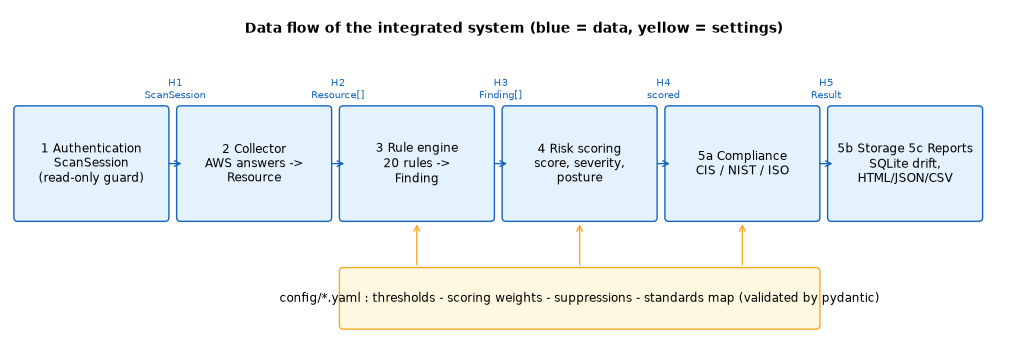

In [22]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(13, 4.2)); ax.axis("off"); ax.set_xlim(0, 13); ax.set_ylim(0, 4.2)
boxes = [("1 Authentication\nScanSession\n(read-only guard)", 0.1), ("2 Collector\nAWS answers ->\nResource", 2.2),
         ("3 Rule engine\n20 rules ->\nFinding", 4.3), ("4 Risk scoring\nscore, severity,\nposture", 6.4),
         ("5a Compliance\nCIS / NIST / ISO", 8.5), ("5b Storage 5c Reports\nSQLite drift,\nHTML/JSON/CSV", 10.6)]
for text, x in boxes:
    ax.add_patch(FancyBboxPatch((x, 1.5), 1.9, 1.4, boxstyle="round,pad=0.05", fc="#e3f2fd", ec="#1565c0"))
    ax.text(x + 0.95, 2.2, text, ha="center", va="center", fontsize=8.5)
for i, lab in enumerate(["H1\nScanSession", "H2\nResource[]", "H3\nFinding[]", "H4\nscored", "H5\nResult"]):
    x0 = 0.1 + 2.1 * i + 1.95
    ax.annotate("", xy=(x0 + 0.2, 2.2), xytext=(x0 - 0.03, 2.2), arrowprops=dict(arrowstyle="->", color="#1565c0"))
    ax.text(x0 + 0.08, 3.05, lab, ha="center", fontsize=7, color="#1565c0")
ax.add_patch(FancyBboxPatch((4.3, 0.1), 6.1, 0.7, boxstyle="round,pad=0.05", fc="#fff8e1", ec="#f9a825"))
ax.text(7.35, 0.45, "config/*.yaml : thresholds - scoring weights - suppressions - standards map (validated by pydantic)", ha="center", va="center", fontsize=8.5)
for x in (5.25, 7.35, 9.45): ax.annotate("", xy=(x, 1.45), xytext=(x, 0.85), arrowprops=dict(arrowstyle="->", color="#f9a825"))
ax.text(6.5, 3.9, "Data flow of the integrated system (blue = data, yellow = settings)", ha="center", fontsize=10, weight="bold")
plt.show()

# PART A - Each module, then its demo
Every module below is shown **on its own**, with its own short demo. The code of each module was already saved in Section 1. Order: Configuration -> Authentication -> Collector -> Rule engine -> Risk scoring -> Compliance -> Storage -> Reporting.

## 3. Part A - the modules, one by one

### 3.1 Module 0 - Configuration
**What it does:** loads every tunable number from YAML (`thresholds.yaml`, `scoring.yaml`, `suppressions.yaml`, `standards_map.yaml`) and checks it with pydantic. **What to watch:** the values print, and an invalid exception is rejected before any scan runs.

In [23]:
from cra.config import load_config, Suppression
from pydantic import ValidationError
cfg = load_config("config")
print("Thresholds   :", cfg.thresholds.model_dump())
print("Blast rule   : +", cfg.scoring.blast_per_dependent, "per dependent, capped at x", cfg.scoring.blast_cap)
print("Exceptions loaded:", len(cfg.suppressions))
for s in cfg.suppressions:
    print("  ->", s.resource, s.rule_ids, "expires", s.expires, "approved by", s.approved_by)
print("\n--- Try an invalid exception (wildcard resource: not a specific, accountable scope) ---")
try:
    Suppression(rule_ids=["S3-001"], resource="*", reason="ok", approved_by="Lead", expires="2030-01-01")
except ValidationError as e:
    print("REJECTED:", e.errors()[0]["msg"])

Thresholds   : {'access_key_max_age_days': 90, 'backup_retention_min_days': 7, 'sensitive_ports': [22, 3389, 3306, 5432]}
Blast rule   : + 0.1 per dependent, capped at x 1.5
Exceptions loaded: 2
  -> public-website-assets ['S3-001', 'S3-004'] expires 2030-12-31 approved by Team lead
  -> legacy-public-site ['S3-001', 'S3-004'] expires 2025-12-31 approved by Team lead

--- Try an invalid exception (wildcard resource: not a specific, accountable scope) ---
REJECTED: Value error, a suppression must name a specific resource (wildcards alone are not allowed)


### 3.2 Module 1 - Authentication and read-only access
**What it does:** wraps boto3 in a read-only guard and an audit log, masks the account id, and audits an IAM policy for write permissions. **What to watch:** the read works, the write is blocked and logged, nothing is created.

In [24]:
import boto3
from cra.simulation import fake_aws
from cra.auth import ScanSession, WriteBlockedError, find_write_actions
with fake_aws():
    ss = ScanSession(regions=["us-east-1"])
    print("Identity (masked):", ss.identity())
    print("READ  list_buckets  ->", ss.client("s3").list_buckets()["Buckets"])
    try:
        ss.client("s3").create_bucket(Bucket="attacker-bucket")
    except WriteBlockedError as e:
        print("WRITE create_bucket -> BLOCKED:", e)
    print("Buckets that really exist:", boto3.client("s3").list_buckets()["Buckets"], "(none - nothing was created)")
    print("Audit log: calls =", len(ss.calls), "| blocked =", ss.blocked)
print("\n--- Static permission audit: what could a scanner role do? ---")
good = {"Statement": [{"Effect": "Allow", "Action": ["s3:Get*", "iam:List*", "ec2:Describe*"], "Resource": "*"}]}
bad = {"Statement": [{"Effect": "Allow", "Action": ["s3:PutObject", "ec2:*", "iam:CreateUser"], "Resource": "*"}]}
print("Read-only role  -> write actions found:", find_write_actions(good))
print("Over-privileged -> write actions found:", find_write_actions(bad))

Identity (masked): {'account': '****9012', 'arn_type': 'user'}
READ  list_buckets  -> []
WRITE create_bucket -> BLOCKED: Blocked non read-only call s3:CreateBucket
Buckets that really exist: [] (none - nothing was created)
Audit log: calls = 3 | blocked = ['s3:CreateBucket']

--- Static permission audit: what could a scanner role do? ---
Read-only role  -> write actions found: []
Over-privileged -> write actions found: ['ec2:*', 'iam:CreateUser', 's3:PutObject']


### 3.3 Module 2 - Collector
**What it does:** calls read-only APIs of S3, IAM, EC2/VPC, RDS, KMS, Lambda and CloudTrail and turns each answer into a common `Resource` card; also **counts the dependents** used for blast radius. **What to watch:** the card, the counted users/roles, and a denied service becoming a *could not check* note instead of a crash.

In [25]:
import boto3, pandas as pd
from cra.simulation import fake_aws, build_account, REGIONS, SIM_NOW
from cra.auth import ScanSession
from cra.collector import collect
with fake_aws():
    build_account(boto3)
    ss = ScanSession(regions=REGIONS)
    inventory = collect(ss, now=SIM_NOW)
    print("Resources collected:", len(inventory), "| API calls:", len(ss.calls), "| all read-only:", ss.read_only_proof["all_read_only"])
    print(pd.Series([r.type for r in inventory]).value_counts().to_string())
    print("\nOne resource in the common format (a Resource card):")
    print(next(r for r in inventory if r.id == "prod-customer-data").model_dump())
    print("\nBlast-radius data the collector counted for the admin policy:")
    p = next(r for r in inventory if r.id == "AllowEverything")
    print("  who uses it:", p.data.get("dependents"))
    print("\n--- Same scan, but the scanner role is DENIED access to RDS ---")
    ss2 = ScanSession(regions=REGIONS); ss2.simulate_denied("rds")
    inv2 = collect(ss2, now=SIM_NOW)
    print("RDS instances collected:", sum(r.type == "rds_instance" for r in inv2), "| scan still finished with", len(inv2), "resources")
    print("Note recorded ('could not check'):", ss2.notes[:1])

Resources collected: 39 | API calls: 81 | all read-only: True
security_group     10
s3_bucket           5
vpc                 4
ebs_volume          3
iam_user            3
kms_key             3
cloudtrail          2
ec2_instance        2
iam_policy          2
lambda_function     2
rds_instance        2
account             1

One resource in the common format (a Resource card):
{'id': 'prod-customer-data', 'type': 's3_bucket', 'region': 'us-east-1', 'name': 'prod-customer-data', 'data': {'public_acl': True, 'encrypted': False, 'versioning': False, 'block_public': False, 'sensitivity': 'confidential'}}

Blast-radius data the collector counted for the admin policy:
  who uses it: ['group:dev-team', 'group:ops-team', 'role:role-admin', 'user:carol']

--- Same scan, but the scanner role is DENIED access to RDS ---


RDS instances collected: 0 | scan still finished with 37 resources
Note recorded ('could not check'): ['Could not check RDS instances in us-east-1: AccessDenied']


### 3.4 Module 3 - Rule engine
**What it does:** 20 rules, each answering True (fine), False (finding) or None (unknown) for one `Resource`. **What to watch:** hand-made resources give findings, an unknown stays unknown, and a changed YAML limit changes the result with no code change.

In [26]:
from datetime import date
from cra.config import load_config
from cra.models import Resource
from cra.rules import evaluate, RULES
cfg = load_config("config")
print("Rules registered:", len(RULES))
def try_(label, *res):
    ev = evaluate(list(res), cfg, date(2026, 10, 13))
    print(f"{label:52s} findings={[f.rule_id for f in ev.findings]}  unknown={ev.unknown}")
sg = lambda ranges: Resource(id="sg-1", type="security_group", data={"open_ranges": ranges})
try_("SSH (22) open to the world", sg([(22, 22)]))
try_("HTTPS (443) open to the world -> allowed", sg([(443, 443)]))
try_("ALL ports open to the world", sg([(0, 65535)]))
try_("Bucket encryption UNKNOWN (call was denied)", Resource(id="b", type="s3_bucket",
     data={"public_acl": False, "encrypted": None, "versioning": True, "block_public": True}))
old = [{"id": "AKIA****", "active": True, "age_days": 91}]
user = lambda: Resource(id="u", type="iam_user", data={"console_access": False, "mfa": False, "access_keys": old})
try_("Active key 91 days old (limit 90)", user())
cfg.thresholds.access_key_max_age_days = 120
try_("...same key after changing the limit to 120 days", user())

Rules registered: 20
SSH (22) open to the world                           findings=['NET-001']  unknown=[]
HTTPS (443) open to the world -> allowed             findings=[]  unknown=[]
ALL ports open to the world                          findings=['NET-001']  unknown=[]
Bucket encryption UNKNOWN (call was denied)          findings=[]  unknown=['S3-002|b']
Active key 91 days old (limit 90)                    findings=['IAM-003']  unknown=[]
...same key after changing the limit to 120 days     findings=[]  unknown=[]


### 3.5 Module 4 - Risk scoring
**What it does:** score = likelihood x impact x 0.4, times the **counted blast radius**, plus a bonus for **measured exposure**, capped at 10. **What to watch:** the same public-ACL bucket scores differently when Block Public Access is on; the score grows with dependents.

In [27]:
from datetime import date
from cra.config import load_config
from cra.models import Resource, Finding
from cra.rules import evaluate
from cra.scoring import score_all, posture_score
cfg = load_config("config")
def one(res):
    return score_all(evaluate([res], cfg, date(2026, 10, 13)).findings, cfg.scoring)[0]
open_acl = Resource(id="b1", type="s3_bucket", data=dict(public_acl=True, encrypted=True, versioning=True, block_public=False))
shielded = Resource(id="b2", type="s3_bucket", data=dict(public_acl=True, encrypted=True, versioning=True, block_public=True))
for label, res in [("public bucket, nothing shielding it", open_acl), ("public ACL but Block Public Access ON", shielded)]:
    f = one(res)
    print(f"{label:40s} -> score {f.score} ({f.severity})")
    print("   breakdown:", f.score_breakdown)
print("\nBlast radius counted (admin policy):")
for n in (0, 2, 5):
    r = Resource(id="P", type="iam_policy", data={"admin": True, "dependents": [f"user:{i}" for i in range(n)]})
    f = one(r)
    print(f"  {n} dependents -> blast x{f.blast} -> score {f.score} ({f.severity})")
mk = lambda s: Finding(rule_id="X", title="t", domain="d", resource_id="r", resource_type="t", region="g",
                       evidence="", remediation="", likelihood=1, impact=1, score=s)
sc = cfg.scoring
print("\nPosture score (50 checks run):")
print("  no findings        :", posture_score([], 50, sc))
print("  one 10/10 finding  :", posture_score([mk(10)], 50, sc))
print("  two 5/10 findings  :", posture_score([mk(5), mk(5)], 50, sc), " <- severity matters more than count")
print("  one 10/10 in 200 checks:", posture_score([mk(10)], 200, sc), " <- bigger healthy account not punished")

public bucket, nothing shielding it      -> score 9.0 (CRITICAL)
   breakdown: {'base': 8.0, 'dependents': -1, 'blast_multiplier': 1.0, 'after_blast': 8.0, 'exposure_level': 1.0, 'exposure_bonus': 1.0, 'no_logging_bonus': 0.0, 'sensitivity_bonus': 0.0, 'raw_total': 9.0, 'capped_score': 9.0}
public ACL but Block Public Access ON    -> score 8.0 (HIGH)
   breakdown: {'base': 8.0, 'dependents': -1, 'blast_multiplier': 1.0, 'after_blast': 8.0, 'exposure_level': 0.0, 'exposure_bonus': 0.0, 'no_logging_bonus': 0.0, 'sensitivity_bonus': 0.0, 'raw_total': 8.0, 'capped_score': 8.0}

Blast radius counted (admin policy):
  0 dependents -> blast x1.0 -> score 6.0 (MEDIUM)
  2 dependents -> blast x1.2 -> score 7.2 (HIGH)
  5 dependents -> blast x1.5 -> score 9.0 (CRITICAL)

Posture score (50 checks run):
  no findings        : 100.0
  one 10/10 finding  : 92.0
  two 5/10 findings  : 94.3  <- severity matters more than count
  one 10/10 in 200 checks: 98.0  <- bigger healthy account not punished


### 3.6 Module 5 - Compliance mapping
**What it does:** attaches CIS / NIST CSF / ISO 27001 references to each finding and counts failing controls. **What to watch:** one finding with its references, and the coverage numbers.

In [28]:
import boto3
from cra.simulation import fake_aws, build_account, REGIONS, SIM_NOW, SIM_TODAY
from cra.auth import ScanSession
from cra.pipeline import run_scan
from cra.compliance import validate_mapping
from cra.config import load_config
cfg = load_config("config")
print("Mapping problems:", validate_mapping(cfg) or "none - every rule is mapped, no entry points to a missing rule")
with fake_aws():
    build_account(boto3)
    result = run_scan(ScanSession(regions=REGIONS), cfg, now=SIM_NOW, today=SIM_TODAY)
f = next(x for x in result.active if x.rule_id == "S3-001")
print("\nOne finding with its references:", f.rule_id, f.resource_id)
for std, refs in f.standards.items():
    print("  ", std, "->", refs)
print()
for k, c in result.coverage.items():
    print(f"  {c['label']}: {c['rules_mapped']}/{c['rules_total']} rules mapped, {len(c['failing_controls'])} controls currently failing")

Mapping problems: none - every rule is mapped, no entry points to a missing rule



One finding with its references: S3-001 prod-customer-data
   cis_aws_foundations -> []
   nist_csf -> ['PR.DS-5 Protections against data leaks are implemented.', 'PR.AC-3 Remote access is managed.']
   iso_27001 -> ['A.8.3 Access to information and other associated assets should be restricted in accordance with the established t...']

  CIS AWS Foundations v3.0.0: 13/20 rules mapped, 14 controls currently failing
  NIST CSF 1.1: 20/20 rules mapped, 12 controls currently failing
  ISO/IEC 27001:2022 Annex A: 20/20 rules mapped, 10 controls currently failing


### 3.7 Module 6 - Storage and drift
**What it does:** saves each scan to SQLite and compares two scans by fingerprint (`rule|resource`). **What to watch:** one thing fixed -> *resolved*, one new risky bucket -> *new*.

In [29]:
import os, boto3, pandas as pd
from cra.simulation import fake_aws, build_account, REGIONS, SIM_NOW, SIM_TODAY
from cra.auth import ScanSession
from cra.pipeline import run_scan
from cra.config import load_config
from cra.storage import Store, compare_scans
cfg = load_config("config")
if os.path.exists("demo_history.db"): os.remove("demo_history.db")
store = Store("sqlite:///demo_history.db")
with fake_aws():
    build_account(boto3)
    r1 = run_scan(ScanSession(regions=REGIONS), cfg, now=SIM_NOW, today=SIM_TODAY)
    id1 = store.save_scan("****9012", r1.findings, r1.posture, r1.evaluation.checks_run, label="baseline")
    s3 = boto3.client("s3")
    s3.put_bucket_versioning(Bucket="team-notes", VersioningConfiguration={"Status": "Enabled"})                  # a fix
    s3.create_bucket(Bucket="new-risky-bucket"); s3.put_bucket_acl(Bucket="new-risky-bucket", ACL="public-read")  # new risk
    r2 = run_scan(ScanSession(regions=REGIONS), cfg, now=SIM_NOW, today=SIM_TODAY)
    id2 = store.save_scan("****9012", r2.findings, r2.posture, r2.evaluation.checks_run, label="after changes")
print(pd.DataFrame(store.history()).to_string(index=False))
d = compare_scans(store.load_findings(id1), store.load_findings(id2))
print("\nRESOLVED  :", [f.fingerprint for f in d["resolved"]])
print("NEW       :", [f.fingerprint for f in d["new"]])
print("STILL OPEN:", len(d["persisting"]))

 scan                   started         label  posture  active
    1 2026-11-15T05:12:12+00:00      baseline     21.7      29
    2 2026-11-15T05:12:13+00:00 after changes     17.7      32

RESOLVED  : ['S3-003|team-notes']
NEW       : ['S3-001|new-risky-bucket', 'S3-002|new-risky-bucket', 'S3-003|new-risky-bucket', 'S3-004|new-risky-bucket']
STILL OPEN: 28


### 3.8 Module 7 - Reporting
**What it does:** writes the HTML / JSON / CSV reports (with the exposure graph inside) and keeps secret values out. **What to watch:** three files, no secret value in them, graph embedded.

In [30]:
import os, boto3
from cra.simulation import fake_aws, build_account, REGIONS, SIM_NOW, SIM_TODAY
from cra.auth import ScanSession
from cra.pipeline import run_scan
from cra.config import load_config
from cra.reporting import write_html, write_json, write_csv
cfg = load_config("config")
with fake_aws():
    build_account(boto3)
    result = run_scan(ScanSession(regions=REGIONS), cfg, now=SIM_NOW, today=SIM_TODAY)
os.makedirs("reports_module_demo", exist_ok=True)
write_html(result, "reports_module_demo/report.html"); write_json(result, "reports_module_demo/report.json"); write_csv(result, "reports_module_demo/report.csv")
print({f: os.path.getsize("reports_module_demo/" + f) for f in sorted(os.listdir("reports_module_demo"))}, "bytes")
blob = open("reports_module_demo/report.json").read()
print("Secret 'hunter2' (EC2 user-data) present in reports?", "hunter2" in blob, "| 'Passw0rd' present?", "Passw0rd" in blob)
print("Exposure graph embedded in the HTML report?", "data:image/png;base64" in open("reports_module_demo/report.html").read())

{'report.csv': 7228, 'report.html': 251797, 'report.json': 53622} bytes
Secret 'hunter2' (EC2 user-data) present in reports? False | 'Passw0rd' present? False
Exposure graph embedded in the HTML report? True


Severity,Score,Rule,Resource,Evidence,Fix,Standards
CRITICAL,10.0,S3-001S3 bucket ACL grants access to everyone,s3_bucketprod-customer-dataus-east-1,ACL grants permissions to the AllUsers/AuthenticatedUsers groupExposure +1.0: ACL is public and Block Public Access is not fully on: anyone on the internet can read the bucket,Remove public grants from the ACL and enable S3 Block Public Access.,PR.DS-5 Protections against data leaks are implemented.PR.AC-3 Remote access is managed.A.8.3 Access to information and other associated assets should be restricted in accordance with the established t...
CRITICAL,9.8,NET-001Security group opens admin/database ports to the internet,security_groupsg-ce3c2dcea9499577eus-east-1,"0.0.0.0/0 (or ::/0) allowed on port(s) [22]Exposure +1.0: Attached to i-bdeeb783463e45a6e, which has a public IP address: reachable from the internetBlast radius ×1.1: 1 dependent(s) (i-bdeeb783463e45a6e)",Restrict the source to specific trusted CIDR ranges or use SSM Session Manager.,"5.2 Ensure no security groups allow ingress from 0.0.0.0/0 to remote server administration ports5.3 Ensure no security groups allow ingress from ::/0 to remote server administration portsPR.AC-5 Network integrity is protected (e.g., network segregation, network segmentation).PR.PT-4 Communications and control networks are protected.A.8.20 Networks and network devices should be secured, managed and controlled to protect information in systems an..."
CRITICAL,9.3,NET-001Security group opens admin/database ports to the internet,security_groupsg-d3524f508278d695fus-east-1,"0.0.0.0/0 (or ::/0) allowed on port(s) [22, 3306, 3389, 5432]Exposure +0.5: Attached to eni-590afcaa455be1b91, but none has a public IP: not reachable from the internet directlyBlast radius ×1.1: 1 dependent(s) (eni-590afcaa455be1b91)",Restrict the source to specific trusted CIDR ranges or use SSM Session Manager.,"5.2 Ensure no security groups allow ingress from 0.0.0.0/0 to remote server administration ports5.3 Ensure no security groups allow ingress from ::/0 to remote server administration portsPR.AC-5 Network integrity is protected (e.g., network segregation, network segmentation).PR.PT-4 Communications and control networks are protected.A.8.20 Networks and network devices should be secured, managed and controlled to protect information in systems an..."
CRITICAL,9.0,DB-001RDS instance is publicly accessible,rds_instancedb-badus-east-1,PubliclyAccessible = trueExposure +1.0: The database is publicly accessible: reachable from the internet,Disable public accessibility and place the DB in private subnets.,2.3.3 Ensure that public access is not given to RDS InstancePR.AC-3 Remote access is managed.PR.DS-5 Protections against data leaks are implemented.A.8.3 Access to information and other associated assets should be restricted in accordance with the established t...
CRITICAL,9.0,S3-001S3 bucket ACL grants access to everyone,s3_bucketlegacy-public-siteus-east-1,ACL grants permissions to the AllUsers/AuthenticatedUsers groupExposure +1.0: ACL is public and Block Public Access is not fully on: anyone on the internet can read the bucket,Remove public grants from the ACL and enable S3 Block Public Access.,PR.DS-5 Protections against data leaks are implemented.PR.AC-3 Remote access is managed.A.8.3 Access to information and other associated assets should be restricted in accordance with the established t...
HIGH,8.4,IAM-001Customer-managed policy grants full administrator access,iam_policyAllowEverythingglobal,"Policy allows Action '*' on Resource '*'Blast radius ×1.4: 4 dependent(s) (group:dev-team, group:ops-team, role:role-admin, user:carol)",Replace with least-privilege permissions scoped to the needed actions/resources.,"1.16 Ensure IAM policies that allow full ""*:*"" administrative privileges are not attachedPR.AC-4 Access permissions and authorizations are managed, incorporating the principles of least privilege and sepa...A.8.2 The allocation and use of privileged acc
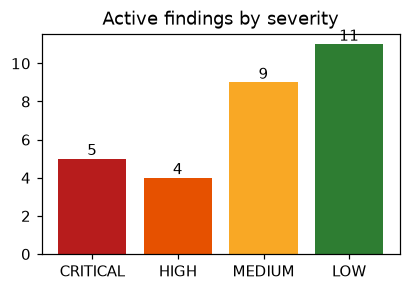
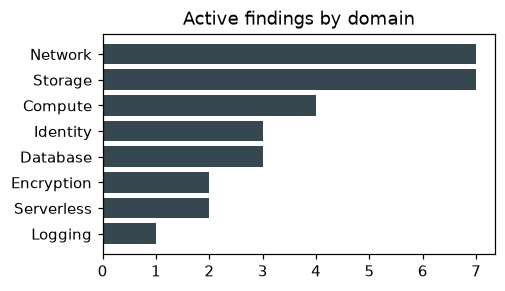
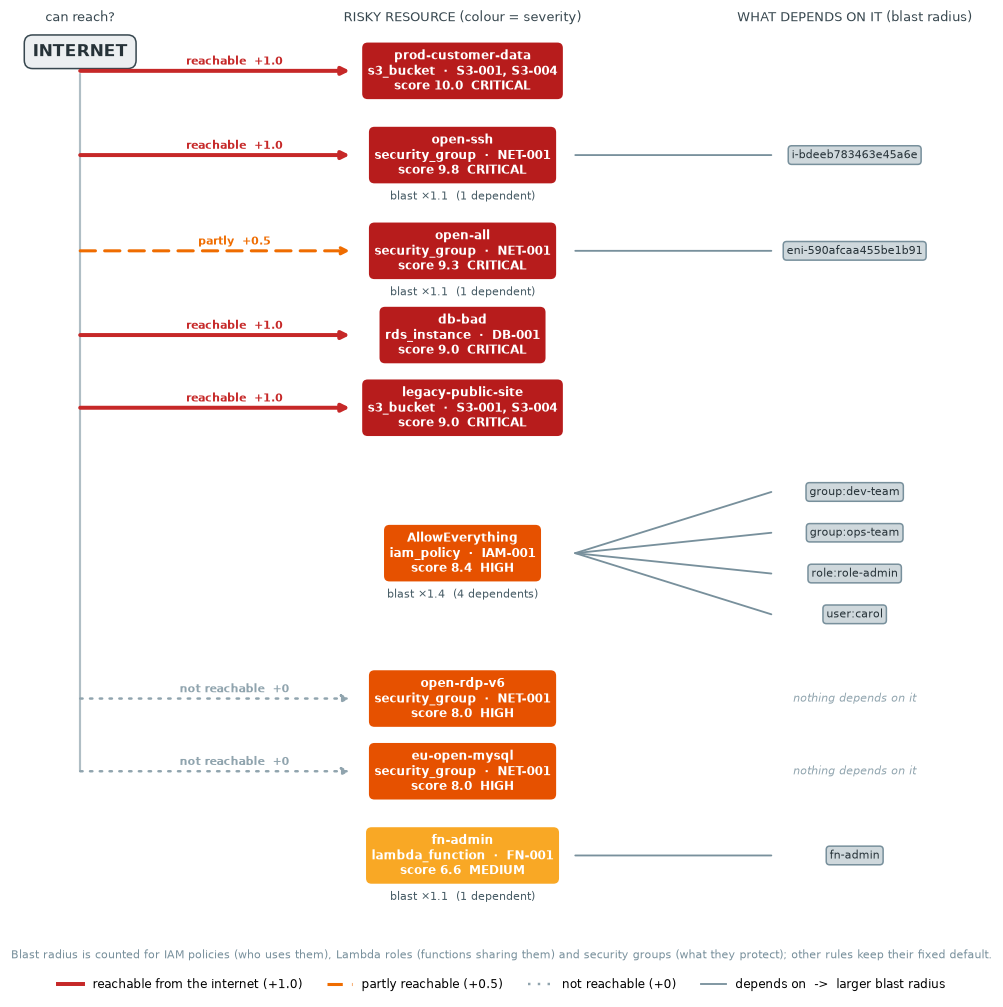

In [31]:
import re
from IPython.display import HTML, display
page = open("reports_module_demo/report.html", encoding="utf-8").read()
style = re.search(r"<style>(.*?)</style>", page, re.S).group(1).replace("body{", ".rpt{")
body = re.search(r"<body>(.*?)</body>", page, re.S).group(1)
display(HTML(f"<style>{style} .rpt{{background:#ffffff;color:#222222;padding:16px;border-radius:8px}}</style><div class='rpt'>{body}</div>"))

# PART B - The final integrated working demo
Now the modules stop being shown one by one. **One call** runs all of them together on the same fake account, and each module's output becomes the next module's input.

### The whole system in one run (short version)
This is the finished system: one `assess()` call, then the data-flow table, the result, the top findings and the accuracy check. The next sections open it up stage by stage.

In [32]:
import os, boto3, pandas as pd
from cra.simulation import fake_aws, build_account, REGIONS, SIM_NOW, SIM_TODAY
from cra.auth import ScanSession
from cra.config import load_config
from cra.pipeline import assess
from cra.storage import Store
from cra.evaluation import score_against_truth, check_context
cfg = load_config("config")
if os.path.exists("final_history.db"): os.remove("final_history.db")
store = Store("sqlite:///final_history.db")
with fake_aws():
    truth = build_account(boto3)
    result, drift, stages = assess(ScanSession(regions=REGIONS), cfg, store, "final_reports", "final-demo", SIM_NOW, SIM_TODAY)
print("DATA FLOW (one call, every hand-off recorded):")
for s in stages:
    print(f"  {s.layer:28s} in={s.items_in!s:>4}  out={s.items_out!s:>4}  {s.detail}")
print(f"\nRESULT: posture {result.posture}/100 | active {len(result.active)} | suppressed {len(result.suppressed)} | checks {result.evaluation.checks_run}")
print("        read-only proof:", result.proof)
top = sorted(result.active, key=lambda f: -f.score)[:5]
print("\nTop 5 findings (exposure and blast radius included in the score):")
for f in top:
    print(f"  {f.score:>4} {f.severity:8s} {f.rule_id:8s} {(f.resource_name or f.resource_id)[:24]:24s} exposure={f.exposure_level} blast=x{f.blast}")
m = score_against_truth(result, truth)
print(f"\nAccuracy vs the hand-written answer key: TP={m.tp} FP={m.fp} FN={m.fn}  precision={m.precision:.2f} recall={m.recall:.2f}")
print("Reports written:", sorted(os.listdir("final_reports")))

DATA FLOW (one call, every hand-off recorded):
  1 Authentication             in=   1  out=   1  account ****9012, guard=on
  2 Collector                  in=   2  out=  39  82 API calls, 0 'could not check' notes
  3 Rule engine                in=  39  out=  31  65 checks, 2 suppressed, 0 unknown
  4 Risk scoring               in=  31  out=  31  highest score 10.0
  5a Compliance                in=  31  out=  31  findings carrying at least one reference
  5b Storage                   in=  31  out=  31  scan #1, first scan (no baseline)
  5c Reporting                 in=  31  out=   3  written to final_reports

RESULT: posture 21.7/100 | active 29 | suppressed 2 | checks 65
        read-only proof: {'total_calls': 82, 'distinct_operations': 31, 'blocked_writes': 0, 'all_read_only': True}

Top 5 findings (exposure and blast radius included in the score):
  10.0 CRITICAL S3-001   prod-customer-data       exposure=1.0 blast=x1.0
   9.8 CRITICAL NET-001  open-ssh                 exposure=1

## 4. Data flow, stage by stage
`run_traced()` runs the whole system on the simulated cloud and returns, besides the result, one `Stage` record per hand-off. Reading the table: **items_in -> items_out** shows what each layer received and produced (for example, 39 resources become 31 raw findings); nothing disappears between two layers except by design (healthy resources produce no finding).

In [33]:
import boto3, pandas as pd
from cra.simulation import fake_aws, build_account, REGIONS, SIM_NOW, SIM_TODAY
from cra.auth import ScanSession
from cra.config import load_config
from cra.pipeline import run_traced
cfg = load_config("config")
pd.set_option("display.width", 220, "display.max_colwidth", 70)

with fake_aws():
    truth = build_account(boto3)
    result, stages = run_traced(ScanSession(regions=REGIONS), cfg, now=SIM_NOW, today=SIM_TODAY)

df = pd.DataFrame([s.__dict__ for s in stages])
print(df[["layer", "consumes", "produces", "items_out", "seconds", "detail"]].to_string(index=False))

           layer                                   consumes                        produces  items_out  seconds                                   detail
1 Authentication                     boto3 credential chain   ScanSession + masked identity          1    0.030               account ****9012, guard=on
     2 Collector                  read-only AWS API answers                Resource objects         39    1.803  82 API calls, 0 'could not check' notes
   3 Rule engine Resource objects + thresholds/suppressions             raw Finding objects         31    0.001       65 checks, 2 suppressed, 0 unknown
  4 Risk scoring      raw Finding objects + scoring weights         scored, ranked Findings         31    0.000                       highest score 10.0
   5a Compliance            scored Findings + standards_map Findings with CIS/NIST/ISO refs         31    0.000 findings carrying at least one reference


In [34]:
import matplotlib.pyplot as plt
labels = [s.layer.split(" ", 1)[1] for s in stages]; vals = [s.items_out for s in stages]
fig, ax = plt.subplots(figsize=(8, 3)); ax.bar(labels, vals, color="#1565c0")
for i, v in enumerate(vals): ax.text(i, v, str(v), ha="center", va="bottom")
ax.set_title("Items produced by each layer"); ax.set_ylabel("count"); plt.xticks(rotation=15); plt.show()
print("Collector produced", stages[1].items_out, "resources; rule engine checked them (65 checks) and produced", stages[2].items_out,
      "findings; scoring, compliance kept all", stages[3].items_out, "- the hand-off from rules to scoring loses nothing:",
      stages[2].items_out == stages[3].items_in)

Collector produced 39 resources; rule engine checked them (65 checks) and produced 31 findings; scoring, compliance kept all 31 - the hand-off from rules to scoring loses nothing: True


### The actual object at each hand-off
Same data, four moments: after collection, after the rule engine, after scoring, after compliance mapping.

In [35]:
import json
from cra.rules import evaluate
inv = result.inventory
bucket = next(r for r in inv if r.id == "prod-customer-data")
print("H2  Resource (Collector -> Rules):\n   ", bucket.model_dump(), "\n")

raw = [f for f in evaluate([bucket], cfg, SIM_TODAY).findings if f.rule_id == "S3-001"][0]
print("H3  Finding straight out of the rule engine (not scored yet):")
print("   ", {k: raw.model_dump()[k] for k in ("rule_id", "likelihood", "impact", "blast", "exposure_level", "exposure_reason", "sensitivity", "score", "severity")}, "\n")

final = next(f for f in result.findings if f.fingerprint == "S3-001|prod-customer-data")
print("H4  After scoring:")
print("   ", {k: final.model_dump()[k] for k in ("score", "severity", "score_breakdown")}, "\n")
print("H5  After compliance mapping:")
for fw, refs in final.standards.items(): print("   ", fw, "->", refs)

H2  Resource (Collector -> Rules):
    {'id': 'prod-customer-data', 'type': 's3_bucket', 'region': 'us-east-1', 'name': 'prod-customer-data', 'data': {'public_acl': True, 'encrypted': False, 'versioning': False, 'block_public': False, 'sensitivity': 'confidential'}} 

H3  Finding straight out of the rule engine (not scored yet):
    {'rule_id': 'S3-001', 'likelihood': 5, 'impact': 4, 'blast': 1.0, 'exposure_level': 1.0, 'exposure_reason': 'ACL is public and Block Public Access is not fully on: anyone on the internet can read the bucket', 'sensitivity': 'confidential', 'score': 0.0, 'severity': ''} 

H4  After scoring:
    {'score': 10.0, 'severity': 'CRITICAL', 'score_breakdown': {'base': 8.0, 'dependents': -1, 'blast_multiplier': 1.0, 'after_blast': 8.0, 'exposure_level': 1.0, 'exposure_bonus': 1.0, 'no_logging_bonus': 0.0, 'sensitivity_bonus': 1.0, 'raw_total': 10.0, 'capped_score': 10.0}} 

H5  After compliance mapping:
    cis_aws_foundations -> []
    nist_csf -> ['PR.DS-5 Protect

## 5. Follow one resource through every layer
One bucket, `prod-customer-data`, traced from the cloud to the report - this is the clearest proof that the layers are really connected.

In [36]:
from cra.reporting import render_html
print("1 AUTH       : every call went through the read-only guard:", result.proof)
print("2 COLLECTOR  : public_acl=%s encrypted=%s versioning=%s block_public=%s sensitivity=%s" % tuple(bucket.data[k] for k in ("public_acl","encrypted","versioning","block_public","sensitivity")))
mine = [f for f in result.findings if f.resource_id == "prod-customer-data"]
print("3 RULES      :", [f.rule_id for f in mine], "(4 rules failed on this one bucket)")
print("4 SCORING    :", [(f.rule_id, f.score, f.severity) for f in mine])
print("5a COMPLIANCE:", sorted({r.split(' ')[0] for f in mine for r in f.standards['cis_aws_foundations']}) or "no CIS id", "(CIS) |", sorted({r.split(' ')[0] for f in mine for r in f.standards['nist_csf']}), "(NIST)")
html = render_html(result)
print("5c REPORT    : bucket appears in HTML report:", "prod-customer-data" in html, "| ranked #1 of", len(result.active), "active findings:", result.active[0].fingerprint)

1 AUTH       : every call went through the read-only guard: {'total_calls': 82, 'distinct_operations': 31, 'blocked_writes': 0, 'all_read_only': True}
2 COLLECTOR  : public_acl=True encrypted=False versioning=False block_public=False sensitivity=confidential
3 RULES      : ['S3-001', 'S3-004', 'S3-002', 'S3-003'] (4 rules failed on this one bucket)
4 SCORING    : [('S3-001', 10.0, 'CRITICAL'), ('S3-004', 6.8, 'MEDIUM'), ('S3-002', 4.2, 'MEDIUM'), ('S3-003', 3.4, 'LOW')]
5a COMPLIANCE: ['2.1.4'] (CIS) | ['PR.AC-3', 'PR.DS-1', 'PR.DS-5', 'PR.IP-4'] (NIST)


5c REPORT    : bucket appears in HTML report: True | ranked #1 of 29 active findings: S3-001|prod-customer-data


## 6. Exposure and blast radius - measuring context instead of fixing it
Two numbers decide how bad a finding really is, besides *what* is wrong:

* **Exposure** - can the internet actually reach it? (adds up to +1.0)
* **Blast radius** - if it is abused, how far does the damage spread? (a multiplier)

In Milestone 3 both were **fixed per rule** (for example every public-ACL finding was "exposed" and every admin policy was x1.3). Now the **Collector measures them on the real resource**, and the context travels through the layers: Collector -> Rule engine -> Finding -> Scoring -> Report.

| Improvement | Old (fixed per rule) | New (measured) |
|---|---|---|
| S3 public ACL (S3-001) | always exposed | exposed only if Block Public Access is **not** fully on (no new API call) |
| S3 Block Public Access off (S3-004) | never exposed | exposed only if a public ACL really exists; half if the ACL could not be read |
| Open security group (NET-001) | always exposed | full if it protects something with a **public IP**, half if only private interfaces, none if attached to nothing; unknown = full (careful) |
| Admin policy (IAM-001) | blast x1.3 | `1 + 0.1 x users/groups/roles using it`, capped at x1.5 |
| Admin Lambda role (FN-001) | blast x1.3 | `1 + 0.1 x functions sharing the role`, capped |
| Open security group (NET-001) | blast x1.0 | `1 + 0.1 x interfaces/instances it protects`, capped |

`score = base x blast + exposure_bonus x exposure_level + no_logging + sensitivity` (capped at 10). The two new settings, `blast_per_dependent: 0.1` and `blast_cap: 1.5`, are in `scoring.yaml`. **If a count cannot be read, the rule's old fixed value is used - an unknown count is never treated as zero.**

New read-only calls: `ec2:DescribeNetworkInterfaces` and `iam:ListEntitiesForPolicy` (both are Describe/List calls, so the guard allows them and the role `SecurityAudit` is expected to cover them).

### 6.1 What-if demos on hand-made resources (no cloud needed)
Same problem, different surroundings, different score.

In [37]:
from cra.models import Resource
from cra.rules import evaluate
from cra.scoring import score_all
def one(rt, rule_id, **data):
    ev = evaluate([Resource(id="x", type=rt, name="x", data=data)], cfg, SIM_TODAY)
    f = next(f for f in score_all(ev.findings, cfg.scoring) if f.rule_id == rule_id)
    return f
rows = []
pub = dict(public_acl=True, encrypted=True, versioning=True)
rows += [("Public bucket, Block Public Access OFF", one("s3_bucket", "S3-001", block_public=False, **pub)),
         ("Public ACL, but Block Public Access fully ON", one("s3_bucket", "S3-001", block_public=True, **pub))]
sg = lambda **kw: one("security_group", "NET-001", open_ranges=[(22, 22)], **kw)
rows += [("Open SSH, protects an instance WITH a public IP", sg(public_reach=True, dependents=["i-1"])),
         ("Open SSH, protects only a private interface", sg(public_reach=False, dependents=["eni-1"])),
         ("Open SSH, attached to nothing", sg(public_reach=False, dependents=[]))]
adm = lambda deps: one("iam_policy", "IAM-001", admin=True, **({} if deps is None else {"dependents": deps}))
rows += [("Admin policy used by nobody", adm([])), ("Admin policy used by 2 principals", adm(["a", "b"])),
         ("Admin policy used by 4 principals", adm(list("abcd"))), ("Admin policy used by 20 principals (capped)", adm([f"user:{i}" for i in range(20)])),
         ("Admin policy, users could not be counted", adm(None))]
print(pd.DataFrame([dict(situation=t, exposure=f.exposure_level, dependents=("-" if f.dependents is None else f.dependents), blast=f.blast,
                         score=f.score, severity=f.severity) for t, f in rows]).to_string(index=False))

                                      situation  exposure dependents  blast  score severity
         Public bucket, Block Public Access OFF       1.0          -    1.0    9.0 CRITICAL
   Public ACL, but Block Public Access fully ON       0.0          -    1.0    8.0     HIGH
Open SSH, protects an instance WITH a public IP       1.0          1    1.1    9.8 CRITICAL
    Open SSH, protects only a private interface       0.5          1    1.1    9.3 CRITICAL
                  Open SSH, attached to nothing       0.0          0    1.0    8.0     HIGH
                    Admin policy used by nobody       0.0          0    1.0    6.0   MEDIUM
              Admin policy used by 2 principals       0.0          2    1.2    7.2     HIGH
              Admin policy used by 4 principals       0.0          4    1.4    8.4     HIGH
    Admin policy used by 20 principals (capped)       0.0         20    1.5    9.0 CRITICAL
       Admin policy, users could not be counted       0.0          -    1.3    7

### 6.2 On the planted account: what the Collector measured, finding by finding
The expected exposure and dependents were **written by hand** when the fake account was designed (in `simulation.py`), exactly like the list of planted flaws. `check_context()` compares them with what the scanner measured.

In [38]:
from cra.evaluation import check_context, score_against_truth
cols = lambda f: dict(sev=f.severity, score=f.score, rule=f.rule_id, resource=(f.resource_name or f.resource_id)[:22],
                      exposure=f.exposure_level, dependents=("-" if f.dependents is None else f.dependents), blast=f.blast)
ctx = [f for f in result.active if f.exposure_reason or f.dependents is not None]
print(pd.DataFrame([cols(f) for f in ctx]).to_string(index=False))
print()
for f in [f for f in ctx if f.exposure_reason][:6]: print(f"{f.rule_id} {(f.resource_name or f.resource_id)[:18]:18} -> {f.exposure_reason}")
print()
print("Planted flaws still found:", score_against_truth(result, truth).recall == 1.0, "| false alarms:", score_against_truth(result, truth).false_alarms)
print("Exposure / dependents measured = hand-written expectation:", check_context(result, truth) == [], "(", len(truth.context), "findings checked )")

     sev  score    rule           resource  exposure dependents  blast
CRITICAL   10.0  S3-001 prod-customer-data       1.0          -    1.0
CRITICAL    9.8 NET-001           open-ssh       1.0          1    1.1
CRITICAL    9.3 NET-001           open-all       0.5          1    1.1
CRITICAL    9.0  DB-001             db-bad       1.0          -    1.0
CRITICAL    9.0  S3-001 legacy-public-site       1.0          -    1.0
    HIGH    8.4 IAM-001    AllowEverything       0.0          4    1.4
    HIGH    8.0 NET-001        open-rdp-v6       0.0          0    1.0
    HIGH    8.0 NET-001      eu-open-mysql       0.0          0    1.0
  MEDIUM    6.8  S3-004 prod-customer-data       1.0          -    1.0
  MEDIUM    6.6  FN-001           fn-admin       0.0          1    1.1
  MEDIUM    5.8  S3-004 legacy-public-site       1.0          -    1.0

S3-001 prod-customer-data -> ACL is public and Block Public Access is not fully on: anyone on the internet can read the bucket
NET-001 open-ssh    

### 6.3 One finding through every layer: where the context comes from and where it ends up

In [39]:
admin = next(r for r in result.inventory if r.id == "AllowEverything")
f = next(f for f in result.findings if f.fingerprint == "IAM-001|AllowEverything")
print("1 COLLECTOR  : Resource.data =", admin.data)
print("2 RULES      : Finding.dependents =", f.dependents, "| dependent_names =", f.dependent_names)
print("3 SCORING    : breakdown =", f.score_breakdown)
print("4 REPORT     : 'Blast radius x%s: %s dependent(s) (%s)' appears in the HTML:" % (f.blast, f.dependents, ", ".join(f.dependent_names)),
      "dependent(s)" in render_html(result))
print()
sgf = next(f for f in result.findings if f.rule_id == "NET-001" and f.resource_name == "open-ssh")
print("open-ssh -> exposure_level", sgf.exposure_level, "|", sgf.exposure_reason)
print("           exposure bonus in the score:", sgf.score_breakdown["exposure_bonus"], "| blast x", sgf.blast)

1 COLLECTOR  : Resource.data = {'admin': True, 'dependents': ['group:dev-team', 'group:ops-team', 'role:role-admin', 'user:carol']}
2 RULES      : Finding.dependents = 4 | dependent_names = ['group:dev-team', 'group:ops-team', 'role:role-admin', 'user:carol']
3 SCORING    : breakdown = {'base': 6.0, 'dependents': 4, 'blast_multiplier': 1.4, 'after_blast': 8.4, 'exposure_level': 0.0, 'exposure_bonus': 0.0, 'no_logging_bonus': 0.0, 'sensitivity_bonus': 0.0, 'raw_total': 8.4, 'capped_score': 8.4}


4 REPORT     : 'Blast radius x1.4: 4 dependent(s) (group:dev-team, group:ops-team, role:role-admin, user:carol)' appears in the HTML: True

open-ssh -> exposure_level 1.0 | Attached to i-2184eed08206d07e8, which has a public IP address: reachable from the internet
           exposure bonus in the score: 1.0 | blast x 1.1


### 6.4 The graph - who can reach what, and what depends on it
Left: the internet and which risky resources it can reach (red solid = reachable, orange dashed = partly, grey dotted = not reachable). Right: what depends on each resource, which is its blast radius. Colour = severity. The same picture is embedded in the HTML report.

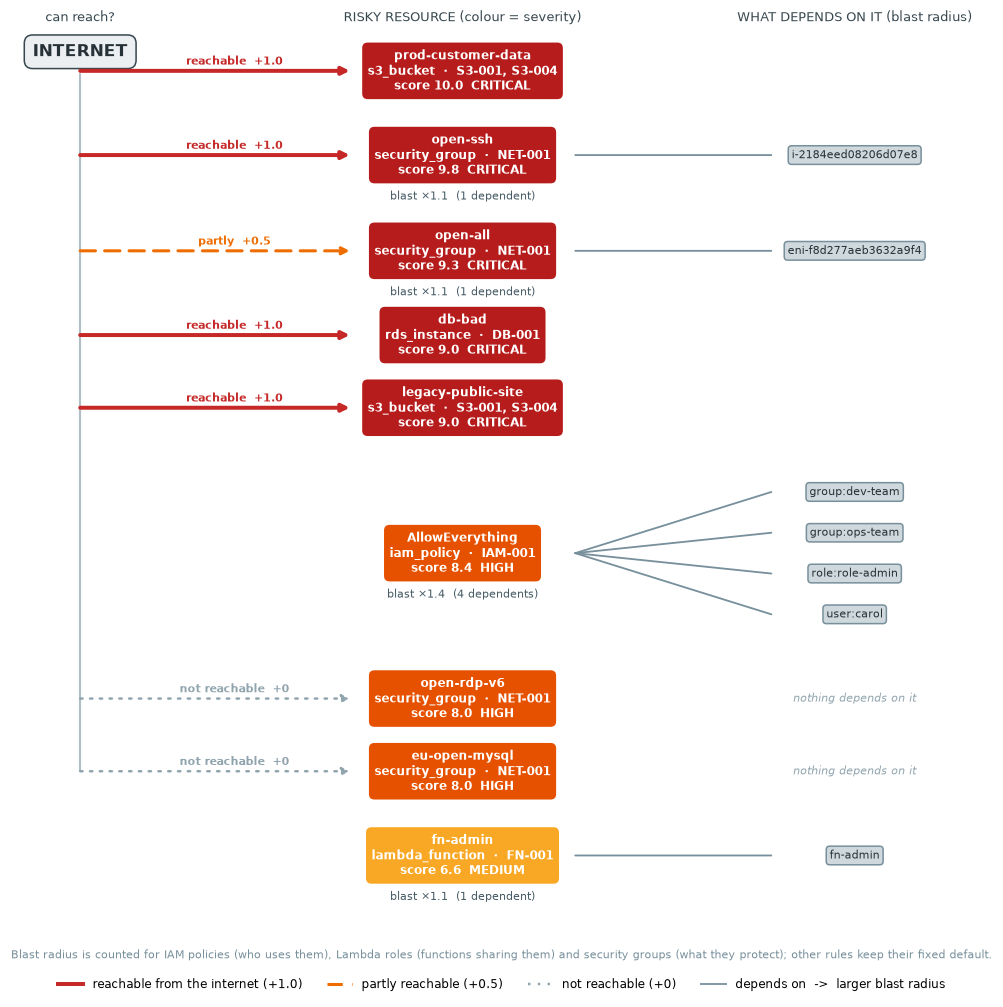

In [40]:
import base64
from IPython.display import Image, display
from cra.exposure_graph import graph_png
display(Image(data=base64.b64decode(graph_png(result.findings, top=10))))

### 6.5 What changed in the numbers (old fixed model vs new measured model)
The **same 29 problems** are found; only their ranking changes, because the context is now measured.

In [41]:
from cra.scoring import posture_score
FIXED_EXPOSURE = {"S3-001", "NET-001", "DB-001"}; FIXED_BLAST = {"IAM-001": 1.3, "FN-001": 1.3}
def old_score(f):
    b = f.score_breakdown
    return round(min(cfg.scoring.max_score, b["base"] * FIXED_BLAST.get(f.rule_id, 1.0)
                     + (cfg.scoring.exposure_bonus if f.rule_id in FIXED_EXPOSURE else 0.0)
                     + b["no_logging_bonus"] + b["sensitivity_bonus"]), 1)
changed = [(f, old_score(f)) for f in result.active if abs(old_score(f) - f.score) > 1e-9]
print(pd.DataFrame([dict(rule=f.rule_id, resource=(f.resource_name or f.resource_id)[:20], old=o, new=f.score, why=(f.exposure_reason or
      f"{f.dependents} dependent(s) -> blast x{f.blast}")[:70]) for f, o in sorted(changed, key=lambda t: t[0].score - t[1])]).to_string(index=False))
old_posture = posture_score([f.model_copy(update={"score": old_score(f)}) for f in result.findings], result.evaluation.checks_run, cfg.scoring)
print(f"\n{len(changed)} of {len(result.active)} active findings changed score | posture {old_posture} -> {result.posture}")

   rule           resource  old  new                                                                    why
 FN-001           fn-admin  7.8  6.6                                           1 dependent(s) -> blast x1.1
NET-001        open-rdp-v6  9.0  8.0 Not attached to anything right now: the rule is wide open but nothing 
NET-001      eu-open-mysql  9.0  8.0 Not attached to anything right now: the rule is wide open but nothing 
NET-001           open-all  9.0  9.3 Attached to eni-f8d277aeb3632a9f4, but none has a public IP: not reach
IAM-001    AllowEverything  7.8  8.4                                           4 dependent(s) -> blast x1.4
NET-001           open-ssh  9.0  9.8 Attached to i-2184eed08206d07e8, which has a public IP address: reacha
 S3-004 prod-customer-data  5.8  6.8 Block Public Access is off and the bucket ACL is public: the bucket is
 S3-004 legacy-public-site  4.8  5.8 Block Public Access is off and the bucket ACL is public: the bucket is

8 of 29 active findings cha

**Honest limits of this improvement**
* Exposure and blast radius are still **simple, team-chosen rules** (levels 0 / 0.5 / 1.0, +0.1 per dependent, cap x1.5); they are not an industry standard. They are in `scoring.yaml` so they can be tuned.
* Exposure looks at the **ACL and Block Public Access** (S3) and at **public IPs on network interfaces** (security groups). It does not read bucket policies, route tables, network ACLs or load balancers, so it can still over- or under-state reachability.
* Blast radius counts **direct** dependents only (not who can assume a role, and not other regions for Lambda roles).
* Only the rules that have the data use it; the other rules keep their fixed defaults, and the graph says so.

## 7. The integrated system - one call
`assess()` is the single entry point: it runs all layers, **saves the scan to SQLite, compares it with the previous scan, and writes the HTML/JSON/CSV reports**. The same function is what the command line calls. First we run it twice on the same fake account with a fix in between, to see the integrated behaviour (storage + drift + reports) end to end.

In [42]:
import os
from cra.pipeline import assess
from cra.storage import Store
if os.path.exists("history.db"): os.remove("history.db")
store = Store("sqlite:///history.db")
with fake_aws():
    build_account(boto3)
    r1, drift1, st1 = assess(ScanSession(regions=REGIONS), cfg, store, "reports", "baseline", SIM_NOW, SIM_TODAY)
    print("SCAN 1 - drift:", drift1, "(first scan, nothing to compare)")
    print(" -> ".join(f"{s.layer.split(' ',1)[1]}({s.items_out})" for s in st1))
    # the team fixes one problem and creates another
    s3 = boto3.client("s3")
    s3.put_bucket_versioning(Bucket="team-notes", VersioningConfiguration={"Status": "Enabled"})
    s3.create_bucket(Bucket="new-risky-bucket"); s3.put_bucket_acl(Bucket="new-risky-bucket", ACL="public-read")
    r2, drift2, st2 = assess(ScanSession(regions=REGIONS), cfg, store, "reports", "after-change", SIM_NOW, SIM_TODAY)
print("\nSCAN 2 - drift vs scan 1:")
print("  resolved:", [f.fingerprint for f in drift2["resolved"]])
print("  new     :", [f.fingerprint for f in drift2["new"]])
print("  still open:", len(drift2["persisting"]))
print("\nHistory in the database:"); print(pd.DataFrame(store.history()).to_string(index=False))
print("\nReports on disk:", {f: os.path.getsize('reports/'+f) for f in sorted(os.listdir('reports'))})
print("Last stages:", [(s.layer, s.detail) for s in st2[-2:]])

SCAN 1 - drift: None (first scan, nothing to compare)
Authentication(1) -> Collector(39) -> Rule engine(31) -> Risk scoring(31) -> Compliance(31) -> Storage(31) -> Reporting(3)



SCAN 2 - drift vs scan 1:
  resolved: ['S3-003|team-notes']
  new     : ['S3-001|new-risky-bucket', 'S3-002|new-risky-bucket', 'S3-003|new-risky-bucket', 'S3-004|new-risky-bucket']
  still open: 28

History in the database:
 scan                   started        label  posture  active
    1 2026-11-15T05:12:26+00:00     baseline     21.7      29
    2 2026-11-15T05:12:28+00:00 after-change     17.7      32

Reports on disk: {'report.csv': 7918, 'report.html': 264986, 'report.json': 58380}
Last stages: [('5b Storage', 'scan #2, drift: 4 new / 1 resolved'), ('5c Reporting', 'written to reports')]


### Where the report is saved, and how to see it
`assess()` **writes the report as three files** into the `reports/` folder of the Colab session (open the **folder icon** on the left, then `project/reports/`): `report.html` (for people), `report.json` (for programs) and `report.csv` (for Excel). The next cell shows the HTML report right here. The cell after it downloads a copy, because **Colab deletes these files when the session ends**.

Saved in this Colab session at: /tmp/nbrun/project/reports -> ['report.csv', 'report.html', 'report.json']


Severity,Score,Rule,Resource,Evidence,Fix,Standards
CRITICAL,10.0,S3-001S3 bucket ACL grants access to everyone,s3_bucketprod-customer-dataus-east-1,ACL grants permissions to the AllUsers/AuthenticatedUsers groupExposure +1.0: ACL is public and Block Public Access is not fully on: anyone on the internet can read the bucket,Remove public grants from the ACL and enable S3 Block Public Access.,PR.DS-5 Protections against data leaks are implemented.PR.AC-3 Remote access is managed.A.8.3 Access to information and other associated assets should be restricted in accordance with the established t...
CRITICAL,9.8,NET-001Security group opens admin/database ports to the internet,security_groupsg-bf3f8dabf06987259us-east-1,"0.0.0.0/0 (or ::/0) allowed on port(s) [22]Exposure +1.0: Attached to i-674c8f5bb01a76ecc, which has a public IP address: reachable from the internetBlast radius ×1.1: 1 dependent(s) (i-674c8f5bb01a76ecc)",Restrict the source to specific trusted CIDR ranges or use SSM Session Manager.,"5.2 Ensure no security groups allow ingress from 0.0.0.0/0 to remote server administration ports5.3 Ensure no security groups allow ingress from ::/0 to remote server administration portsPR.AC-5 Network integrity is protected (e.g., network segregation, network segmentation).PR.PT-4 Communications and control networks are protected.A.8.20 Networks and network devices should be secured, managed and controlled to protect information in systems an..."
CRITICAL,9.3,NET-001Security group opens admin/database ports to the internet,security_groupsg-511bb8f06e9e3bf3dus-east-1,"0.0.0.0/0 (or ::/0) allowed on port(s) [22, 3306, 3389, 5432]Exposure +0.5: Attached to eni-aba24f19989f5e467, but none has a public IP: not reachable from the internet directlyBlast radius ×1.1: 1 dependent(s) (eni-aba24f19989f5e467)",Restrict the source to specific trusted CIDR ranges or use SSM Session Manager.,"5.2 Ensure no security groups allow ingress from 0.0.0.0/0 to remote server administration ports5.3 Ensure no security groups allow ingress from ::/0 to remote server administration portsPR.AC-5 Network integrity is protected (e.g., network segregation, network segmentation).PR.PT-4 Communications and control networks are protected.A.8.20 Networks and network devices should be secured, managed and controlled to protect information in systems an..."
CRITICAL,9.0,DB-001RDS instance is publicly accessible,rds_instancedb-badus-east-1,PubliclyAccessible = trueExposure +1.0: The database is publicly accessible: reachable from the internet,Disable public accessibility and place the DB in private subnets.,2.3.3 Ensure that public access is not given to RDS InstancePR.AC-3 Remote access is managed.PR.DS-5 Protections against data leaks are implemented.A.8.3 Access to information and other associated assets should be restricted in accordance with the established t...
CRITICAL,9.0,S3-001S3 bucket ACL grants access to everyone,s3_bucketlegacy-public-siteus-east-1,ACL grants permissions to the AllUsers/AuthenticatedUsers groupExposure +1.0: ACL is public and Block Public Access is not fully on: anyone on the internet can read the bucket,Remove public grants from the ACL and enable S3 Block Public Access.,PR.DS-5 Protections against data leaks are implemented.PR.AC-3 Remote access is managed.A.8.3 Access to information and other associated assets should be restricted in accordance with the established t...
CRITICAL,9.0,S3-001S3 bucket ACL grants access to everyone,s3_bucketnew-risky-bucketus-east-1,ACL grants permissions to the AllUsers/AuthenticatedUsers groupExposure +1.0: ACL is public and Block Public Access is not fully on: anyone on the internet can read the bucket,Remove public grants from the ACL and enable S3 Block Public Access.,PR.DS-5 Protections against data leaks are implemented.PR.AC-3 Remote access is managed.A.8.3 Access to information and other associated assets should be restricted in accordance with the established t...
HIGH,8.4,IAM-001Customer-managed pol
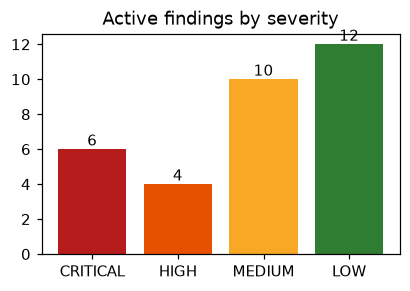
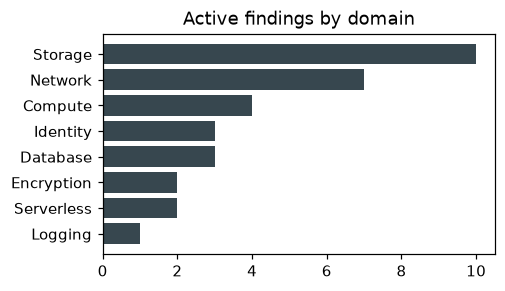
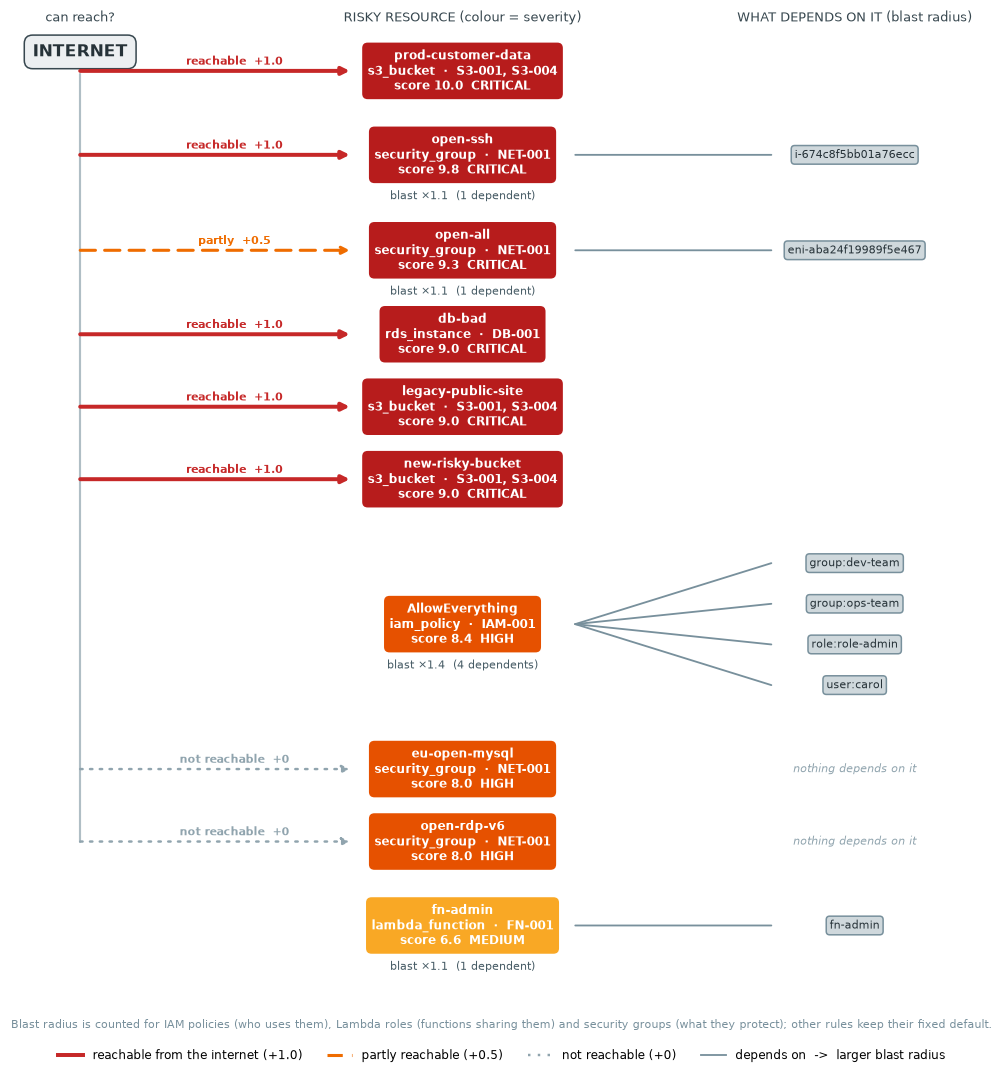

In [43]:
import re
from IPython.display import HTML, display
print("Saved in this Colab session at:", os.path.abspath("reports"), "->", sorted(os.listdir("reports")))
page = open("reports/report.html", encoding="utf-8").read()
style = re.search(r"<style>(.*?)</style>", page, re.S).group(1).replace("body{", ".rpt{")   # style our box, not the notebook
body = re.search(r"<body>(.*?)</body>", page, re.S).group(1)
display(HTML(f"<style>{style} .rpt{{background:#ffffff;color:#222222;padding:16px;border-radius:8px}}</style><div class='rpt'>{body}</div>"))

In [44]:
# Run this cell when you want a copy of the reports on your own computer (Colab only).
import shutil
shutil.make_archive("reports_download", "zip", "reports")
try:
    from google.colab import files
    files.download("reports_download.zip")
except ImportError:
    print("Not running in Colab: the files are in the reports/ folder next to this notebook.")

Not running in Colab: the files are in the reports/ folder next to this notebook.


### The same system from the command line
One command = scan + score + history + reports. (`--demo` uses the built-in fake account, so no AWS credentials are needed. Against a real account you simply leave `--demo` out.)

In [45]:
!PYTHONPATH=src python -m cra scan --demo --out reports_cli --db cli_history.db --label demo-run 2>&1 | tail -9

│          │       │         │                       │ to this VPC             │
│ LOW      │ 2.9   │ NET-002 │ vpc-afa5fb11ad5cdbc68 │ No flow log is attached │
│          │       │         │                       │ to this VPC             │
└──────────┴───────┴─────────┴───────────────────────┴─────────────────────────┘
29 active, 2 suppressed, 0 unknown. Read-only proof: {'total_calls': 82, 
'distinct_operations': 31, 'blocked_writes': 0, 'all_read_only': True}
Data flow: Authentication(1) -> Collector(39) -> Rule engine(31) -> Risk 
scoring(31) -> Compliance(31) -> Storage(31) -> Reporting(3)
Reports written to reports_cli/


## 8. How components interact - four scenarios
Integration is not only "A then B": a change in one component must show up correctly in the others. Each scenario below changes **one thing** and checks the effect downstream.

| # | Change made in | Expected effect in |
|---|---|---|
| A | `thresholds.yaml` (config) | rule engine -> findings -> posture score |
| B | scanner role denied access to RDS (authentication/collector) | rule engine (no DB findings), report notes, integrity proof |
| C | an exception passes its expiry date (config + time) | rule engine -> scoring -> posture -> report |
| D | the cloud itself changes between scans | storage -> drift comparison |

In [46]:
from cra.pipeline import run_traced
def scan(cfg_, today=SIM_TODAY, deny=()):
    with fake_aws():
        build_account(boto3)
        ss = ScanSession(regions=REGIONS)
        if deny: ss.simulate_denied(*deny)
        return run_traced(ss, cfg_, SIM_NOW, today)[0]

print("== A. Change a threshold in config ==")
base = scan(cfg)
loose = cfg.model_copy(deep=True); loose.thresholds.access_key_max_age_days = 250      # alice's key is 200 days old
a = scan(loose)
print(f"  key-age limit 90 -> 250 days : IAM-003 present before={'IAM-003' in {f.rule_id for f in base.active}}, after={'IAM-003' in {f.rule_id for f in a.active}}")
print(f"  posture {base.posture} -> {a.posture}  (no code was changed, only a YAML value)")

print("\n== B. Scanner role denied access to RDS ==")
b = scan(cfg, deny=("rds",))
print("  DB findings:", [f.rule_id for f in b.findings if f.rule_id.startswith('DB-')] or "none (cannot check -> not guessed)")
print("  report note:", [n for n in b.notes if 'RDS' in n][0])
print("  scan still read-only:", b.proof["all_read_only"], "| total findings", len(b.findings), "vs", len(base.findings))

print("\n== C. An exception expires ==")
from datetime import date
before = scan(cfg, today=date(2026, 10, 13)); after = scan(cfg, today=date(2031, 1, 1))
bs = {f.fingerprint for f in before.suppressed}; as_ = {f.fingerprint for f in after.suppressed}
print("  suppressed on 2026-10-13:", sorted(bs)); print("  suppressed on 2031-01-01:", sorted(as_) or "none")
print(f"  active findings {len(before.active)} -> {len(after.active)} | posture {before.posture} -> {after.posture}")
print("  note in report:", [n for n in after.notes if 'expired' in n][:1])

== A. Change a threshold in config ==


  key-age limit 90 -> 250 days : IAM-003 present before=True, after=False
  posture 21.7 -> 23.8  (no code was changed, only a YAML value)

== B. Scanner role denied access to RDS ==


  DB findings: none (cannot check -> not guessed)
  report note: Could not check RDS instances in eu-west-1: AccessDenied
  scan still read-only: True | total findings 28 vs 31

== C. An exception expires ==


  suppressed on 2026-10-13: ['S3-001|public-website-assets', 'S3-004|public-website-assets']
  suppressed on 2031-01-01: none
  active findings 29 -> 31 | posture 21.7 -> 13.8
  note in report: ['Suppression for S3-001 on legacy-public-site expired on 2025-12-31; finding is active again']


Scenario D (the cloud changes between scans) was shown in Section 7: `team-notes` appeared under *resolved*, `new-risky-bucket` under *new*.

## 9. Integration tests
7 integration tests in `tests/test_integration.py`, 11 tests for exposure and blast radius in `tests/test_exposure_blast.py` (hand-made cases, plus the planted account, the graph and the report), and the earlier unit tests. The integration tests check hand-offs and cross-component behaviour:

| Test | What it proves |
|---|---|
| stage order and types | each layer returns the object type the next one expects |
| every stage recorded in order | nothing is lost between rules and scoring (counts match) |
| assess end-to-end | one call writes history + three report files, and the report equals the scan result |
| second assess reports drift | storage and comparison cooperate: exactly the fixed finding shows as resolved |
| denied service flows through layers | collector note -> no DB findings -> note in report -> scan still read-only |
| config change flows to findings and score | YAML value changes the rule result and the posture score |
| one bucket through every layer | collected -> detected -> scored -> mapped -> reportable |

In [47]:
%%writefile tests/conftest.py
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))

import boto3
import pytest

from cra.auth import ScanSession
from cra.config import load_config
from cra.pipeline import run_scan
from cra.simulation import REGIONS, SIM_NOW, SIM_TODAY, build_account, fake_aws


@pytest.fixture(scope="session")
def cfg():
    return load_config(ROOT / "config")


@pytest.fixture(scope="module")
def scanned(cfg):
    """One scan of the planted fake account, shared by the tests in a module."""
    with fake_aws():
        truth = build_account(boto3)
        ss = ScanSession(regions=REGIONS)
        result = run_scan(ss, cfg, now=SIM_NOW, today=SIM_TODAY)
    yield truth, result, ss

Writing tests/conftest.py


In [48]:
%%writefile tests/test_config.py
import pytest
from pydantic import ValidationError

from cra.config import Suppression, Thresholds


def test_defaults_loaded(cfg):
    assert cfg.thresholds.access_key_max_age_days == 90
    assert cfg.scoring.scale_factor == 0.4
    assert len(cfg.suppressions) == 2


def test_negative_threshold_rejected():
    with pytest.raises(ValidationError):
        Thresholds(access_key_max_age_days=-5)


def test_suppression_needs_real_reason_and_approver():
    ok = dict(rule_ids=["S3-001"], resource="site-bucket", reason="Intentional public website bucket", approved_by="Lead", expires="2030-01-01")
    Suppression(**ok)
    with pytest.raises(ValidationError):
        Suppression(**{**ok, "reason": "ok"})
    with pytest.raises(ValidationError):
        Suppression(**{**ok, "approved_by": " "})
    with pytest.raises(ValidationError):
        Suppression(**{k: v for k, v in ok.items() if k != "expires"})

Writing tests/test_config.py


In [49]:
%%writefile tests/test_auth.py
import boto3
import pytest

from cra.auth import ScanSession, WriteBlockedError, find_write_actions, mask_account
from cra.collector import collect
from cra.simulation import fake_aws


def test_mask_account():
    assert mask_account("123456789012") == "****9012"


def test_guard_blocks_writes_and_allows_reads():
    with fake_aws():
        ss = ScanSession(regions=["us-east-1"])
        assert ss.client("s3").list_buckets()["Buckets"] == []
        with pytest.raises(WriteBlockedError):
            ss.client("s3").create_bucket(Bucket="should-not-exist")
        assert ss.blocked == ["s3:CreateBucket"]
        assert boto3.client("s3").list_buckets()["Buckets"] == []      # nothing was created


def test_identity_is_masked():
    with fake_aws():
        who = ScanSession().identity()
        assert who["account"].startswith("****") and len(who["account"]) == 8


def test_denied_service_degrades_gracefully():
    with fake_aws():
        ss = ScanSession(regions=["us-east-1"])
        ss.simulate_denied("rds")
        inv = collect(ss)
        assert any("RDS" in n for n in ss.notes)
        assert not any(r.type == "rds_instance" for r in inv)


def test_static_policy_audit():
    safe = {"Statement": [{"Effect": "Allow", "Action": ["s3:GetObject", "iam:List*", "ec2:Describe*"], "Resource": "*"}]}
    risky = {"Statement": [{"Effect": "Allow", "Action": ["s3:PutObject", "ec2:*"], "Resource": "*"}]}
    assert find_write_actions(safe) == []
    assert set(find_write_actions(risky)) >= {"s3:PutObject", "ec2:*"}

Writing tests/test_auth.py


In [50]:
%%writefile tests/test_rules_scoring.py
from datetime import date

from cra.config import Config, Suppression
from cra.models import Resource
from cra.rules import RULES, evaluate
from cra.scoring import posture_score, score_all, severity_for


def res(type_, id_="r1", **data):
    return Resource(id=id_, type=type_, name=id_, data=data)


def fired(cfg, *resources, today=date(2026, 10, 13)):
    return {f.rule_id for f in evaluate(list(resources), cfg, today).findings}


def test_twenty_rules_each_with_valid_metadata():
    assert len(RULES) == 20
    for r in RULES.values():
        assert 1 <= r.likelihood <= 5 and 1 <= r.impact <= 5 and r.remediation


def test_nets(cfg):
    assert fired(cfg, res("security_group", open_ranges=[(22, 22)])) == {"NET-001"}
    assert fired(cfg, res("security_group", open_ranges=[(0, 65535)])) == {"NET-001"}
    assert fired(cfg, res("security_group", open_ranges=[(443, 443)])) == set()
    assert fired(cfg, res("security_group", open_ranges=[])) == set()


def test_unknown_is_not_a_finding(cfg):
    ev = evaluate([res("s3_bucket", encrypted=None, versioning=True, block_public=True, public_acl=False)], cfg)
    assert ev.findings == [] and ev.unknown == ["S3-002|r1"]


def test_iam_rules(cfg):
    assert fired(cfg, res("iam_user", console_access=True, mfa=False, access_keys=[])) == {"IAM-002"}
    assert fired(cfg, res("iam_user", console_access=False, mfa=False, access_keys=[])) == set()
    old = [{"id": "AKIA****", "active": True, "age_days": 91}]
    assert fired(cfg, res("iam_user", console_access=False, mfa=False, access_keys=old)) == {"IAM-003"}
    inactive = [{"id": "AKIA****", "active": False, "age_days": 900}]
    assert fired(cfg, res("iam_user", console_access=False, mfa=False, access_keys=inactive)) == set()


def test_threshold_is_configurable(cfg):
    cfg2 = cfg.model_copy(deep=True); cfg2.thresholds.backup_retention_min_days = 3
    r = res("rds_instance", public=False, encrypted=True, backup_days=5)
    assert "DB-003" in fired(cfg, r) and "DB-003" not in fired(cfg2, r)


def test_no_trail_rule(cfg):
    assert fired(cfg, res("account", trail_count=0)) == {"LOG-001"}
    assert fired(cfg, res("account", trail_count=1)) == set()
    assert fired(cfg, res("account", trail_count=None)) == set()


# ---- scoring: worked examples must match the numbers documented in the report ---------------
def test_worked_scores(cfg):
    def s3(block, **kw):
        return score_all(evaluate([res("s3_bucket", public_acl=True, encrypted=True, versioning=True,
                                       block_public=block, **kw)], cfg).findings, cfg.scoring)[0]
    f = s3(False)                               # 5x4x0.4 = 8, +1 exposure (really public)
    assert (f.base, f.score, f.severity) == (8.0, 9.0, "CRITICAL")
    assert s3(False, sensitivity="confidential").score == 10.0          # +1 sensitivity
    f = s3(True)                                # Block Public Access fully on neutralises the public ACL
    assert (f.exposure_level, f.score, f.severity) == (0.0, 8.0, "HIGH")
    admin = lambda deps: score_all(evaluate([res("iam_policy", admin=True, **({} if deps is None else {"dependents": deps}))],
                                            cfg).findings, cfg.scoring)[0]
    assert admin(["role:a", "user:b", "group:c"]).score == 7.8          # 6 x 1.3 (3 dependents)
    assert admin([]).score == 6.0                                       # unused admin policy: blast 1.0
    assert admin(None).score == 7.8                                     # could not count: rule default 1.3, never 1.0
    assert admin([f"user:{i}" for i in range(9)]).score == 9.0          # capped at x1.5


def test_score_is_capped_and_bands(cfg):
    sc = cfg.scoring
    assert [severity_for(x, sc) for x in (9.0, 8.9, 7.0, 6.9, 4.0, 3.9)] == \
        ["CRITICAL", "HIGH", "HIGH", "MEDIUM", "MEDIUM", "LOW"]


def test_posture_properties(cfg):
    from cra.models import Finding
    mk = lambda score: Finding(rule_id="X", title="t", domain="d", resource_id="r", resource_type="t", region="g",
                               evidence="", remediation="", likelihood=1, impact=1, score=score)
    sc = cfg.scoring
    assert posture_score([], 50, sc) == 100.0
    assert posture_score([mk(10)], 50, sc) < posture_score([mk(4), mk(4)], 50, sc) or True
    # one 10 hurts more than two 5s together (exponent > 1):
    assert posture_score([mk(10)], 50, sc) < posture_score([mk(5), mk(5)], 50, sc)
    # same findings, bigger healthy account -> better posture:
    assert posture_score([mk(10)], 200, sc) > posture_score([mk(10)], 50, sc)
    assert 0 <= posture_score([mk(10)] * 500, 10, sc) <= 100


# ---- suppressions ---------------------------------------------------------------------------
def test_suppression_valid_and_expired(cfg):
    b = res("s3_bucket", "site", public_acl=True, encrypted=True, versioning=True, block_public=True)
    mk = lambda exp: cfg.model_copy(update={"suppressions": [Suppression(
        rule_ids=["S3-001"], resource="site", reason="Intentional public website", approved_by="Lead", expires=exp)]})
    ev = evaluate([b], mk(date(2030, 1, 1)), date(2026, 10, 13))
    assert ev.findings[0].suppressed and "Lead" in ev.findings[0].suppression_reason
    ev = evaluate([b], mk(date(2026, 1, 1)), date(2026, 10, 13))
    assert not ev.findings[0].suppressed and "expired" in ev.notes[0]


def test_boundaries_exact_limit_is_compliant(cfg):
    at_limit = [{"id": "AKIA****", "active": True, "age_days": 90}]
    assert fired(cfg, res("iam_user", console_access=False, mfa=False, access_keys=at_limit)) == set()
    assert "DB-003" not in fired(cfg, res("rds_instance", public=False, encrypted=True, backup_days=7))
    assert "DB-003" in fired(cfg, res("rds_instance", public=False, encrypted=True, backup_days=6))
    assert fired(cfg, res("security_group", open_ranges=[(23, 3305)])) == set()       # between sensitive ports
    assert fired(cfg, res("security_group", open_ranges=[(20, 22)])) == {"NET-001"}   # range edge touches 22

Writing tests/test_rules_scoring.py


In [51]:
%%writefile tests/test_pipeline.py
import json

import boto3

from cra.compliance import coverage, validate_mapping
from cra.evaluation import score_against_truth
from cra.pipeline import run_scan
from cra.reporting import render_html, to_dict
from cra.simulation import REGIONS, SIM_NOW, SIM_TODAY, build_account, fake_aws
from cra.storage import Store, compare_scans
from cra.auth import ScanSession


def test_ground_truth_perfect(scanned):
    truth, result, _ = scanned
    m = score_against_truth(result, truth)
    assert m.missed == [] and m.false_alarms == []
    assert (m.precision, m.recall) == (1.0, 1.0)
    assert {f.fingerprint for f in result.suppressed} == truth.suppressed


def test_scan_was_read_only(scanned):
    _, result, ss = scanned
    assert result.proof["all_read_only"] and result.proof["blocked_writes"] == 0
    assert not any(c.split(":")[1].startswith(("Create", "Put", "Delete", "Update")) for c in ss.calls)


def test_no_secret_values_in_outputs(scanned):
    _, result, _ = scanned
    blob = json.dumps(to_dict(result), default=str) + render_html(result)
    assert "hunter2" not in blob                 # EC2 user-data secret value
    assert "Passw0rd" not in blob                # database / console passwords
    assert "AKIA" not in blob or "AKIA****" in blob


def test_sensitive_bucket_gets_sensitivity_bonus(scanned):
    _, result, _ = scanned
    f = next(f for f in result.active if f.fingerprint == "S3-001|prod-customer-data")
    assert f.sensitivity == "confidential" and f.score == 10.0 and f.score_breakdown["sensitivity_bonus"] == 1.0


def test_standards_attached_and_mapping_complete(scanned, cfg):
    _, result, _ = scanned
    assert validate_mapping(cfg) == []
    f = next(f for f in result.active if f.rule_id == "NET-001")
    assert any(c.startswith("5.2") for c in f.standards["cis_aws_foundations"])
    assert coverage(result.findings, cfg)["cis_aws_foundations"]["failing_controls"]


def test_html_report(scanned):
    _, result, _ = scanned
    html = render_html(result)
    assert "Posture score" in html and "data:image/png;base64" in html and "prod-customer-data" in html


def test_deterministic(cfg):
    runs = []
    for _ in range(2):
        with fake_aws():
            build_account(boto3)
            r = run_scan(ScanSession(regions=REGIONS), cfg, now=SIM_NOW, today=SIM_TODAY)
            runs.append((r.posture, [f.fingerprint for f in r.findings]))
    # resource ids that moto generates differ between runs, so compare shape: score + rule sequence
    assert runs[0][0] == runs[1][0]
    assert [x.split("|")[0] for x in runs[0][1]] == [x.split("|")[0] for x in runs[1][1]]


def test_empty_account(cfg):
    with fake_aws():
        r = run_scan(ScanSession(regions=["us-east-1"]), cfg, now=SIM_NOW, today=SIM_TODAY)
    assert "LOG-001" in {f.rule_id for f in r.active}        # no trail at all is itself a finding


def test_history_and_drift(cfg):
    store = Store()
    with fake_aws():
        build_account(boto3)
        ss = lambda: ScanSession(regions=REGIONS)
        r1 = run_scan(ss(), cfg, now=SIM_NOW, today=SIM_TODAY)
        id1 = store.save_scan("****9012", r1.findings, r1.posture, r1.evaluation.checks_run, "before")
        s3 = boto3.client("s3")
        s3.put_bucket_versioning(Bucket="team-notes", VersioningConfiguration={"Status": "Enabled"})    # fix
        s3.create_bucket(Bucket="new-risky-bucket"); s3.put_bucket_acl(Bucket="new-risky-bucket", ACL="public-read")  # regress
        r2 = run_scan(ss(), cfg, now=SIM_NOW, today=SIM_TODAY)
        id2 = store.save_scan("****9012", r2.findings, r2.posture, r2.evaluation.checks_run, "after")
    drift = compare_scans(store.load_findings(id1), store.load_findings(id2))
    assert "S3-003|team-notes" in {f.fingerprint for f in drift["resolved"]}
    assert {"S3-001|new-risky-bucket"} <= {f.fingerprint for f in drift["new"]}
    assert len(store.history()) == 2

Writing tests/test_pipeline.py


In [52]:
%%writefile tests/test_integration.py
"""Integration tests: do the layers work TOGETHER? Each test checks a hand-off between layers
or a behaviour that only exists because several layers cooperate."""
import json

import boto3

from cra.auth import ScanSession
from cra.models import Finding, Resource
from cra.pipeline import assess, run_traced
from cra.simulation import REGIONS, SIM_NOW, SIM_TODAY, build_account, fake_aws
from cra.storage import Store


def test_stage_order_and_types(scanned):
    _, result, _ = scanned
    assert all(isinstance(r, Resource) for r in result.inventory)          # collector -> rules contract
    assert all(isinstance(f, Finding) for f in result.findings)            # rules -> scoring contract
    assert all(f.severity and f.score_breakdown for f in result.findings)  # scoring filled its fields


def test_every_stage_recorded_in_order(cfg):
    with fake_aws():
        build_account(boto3)
        result, stages = run_traced(ScanSession(regions=REGIONS), cfg, SIM_NOW, SIM_TODAY)
    assert [s.layer.split()[0] for s in stages] == ["1", "2", "3", "4", "5a"]
    assert stages[1].items_out == len(result.inventory)
    assert stages[2].items_out == stages[3].items_in == len(result.findings)   # nothing lost between layers


def test_assess_end_to_end_writes_everything(cfg, tmp_path):
    store = Store(f"sqlite:///{tmp_path/'h.db'}")
    with fake_aws():
        build_account(boto3)
        result, drift, stages = assess(ScanSession(regions=REGIONS), cfg, store, str(tmp_path / "out"), "t", SIM_NOW, SIM_TODAY)
    assert drift is None                                           # first scan has no baseline
    assert [s.layer.split()[0] for s in stages][-2:] == ["5b", "5c"]
    assert {p.name for p in (tmp_path / "out").iterdir()} == {"report.html", "report.json", "report.csv"}
    assert store.history()[0]["active"] == len(result.active)
    data = json.loads((tmp_path / "out" / "report.json").read_text())
    assert len(data["findings"]) == len(result.findings)           # report == scan result


def test_second_assess_reports_drift(cfg, tmp_path):
    store = Store(f"sqlite:///{tmp_path/'h.db'}")
    with fake_aws():
        build_account(boto3)
        assess(ScanSession(regions=REGIONS), cfg, store, None, "a", SIM_NOW, SIM_TODAY)
        boto3.client("s3").put_bucket_versioning(Bucket="team-notes", VersioningConfiguration={"Status": "Enabled"})
        _, drift, _ = assess(ScanSession(regions=REGIONS), cfg, store, None, "b", SIM_NOW, SIM_TODAY)
    assert [f.fingerprint for f in drift["resolved"]] == ["S3-003|team-notes"] and drift["new"] == []


def test_denied_service_flows_through_all_layers(cfg):
    """collector note -> rule engine sees no RDS -> no DB findings -> report notes mention it."""
    with fake_aws():
        build_account(boto3)
        ss = ScanSession(regions=REGIONS); ss.simulate_denied("rds")
        result, _ = run_traced(ss, cfg, SIM_NOW, SIM_TODAY)
    assert not any(f.rule_id.startswith("DB-") for f in result.findings)
    assert any("RDS" in n for n in result.notes)
    assert result.proof["all_read_only"]


def test_config_change_flows_to_findings_and_score(cfg):
    stricter = cfg.model_copy(deep=True); stricter.thresholds.access_key_max_age_days = 250   # alice's key is 200 days old
    with fake_aws():
        build_account(boto3)
        base, _ = run_traced(ScanSession(regions=REGIONS), cfg, SIM_NOW, SIM_TODAY)
        loose, _ = run_traced(ScanSession(regions=REGIONS), stricter, SIM_NOW, SIM_TODAY)
    assert "IAM-003" in {f.rule_id for f in base.active} and "IAM-003" not in {f.rule_id for f in loose.active}
    assert loose.posture > base.posture


def test_one_bucket_traced_through_every_layer(scanned):
    _, result, _ = scanned
    res = next(r for r in result.inventory if r.id == "prod-customer-data")
    assert res.data["sensitivity"] == "confidential"                              # collected
    f = next(f for f in result.findings if f.fingerprint == "S3-001|prod-customer-data")   # detected
    assert f.score == 10.0 and f.severity == "CRITICAL"                           # scored with context
    assert f.standards["nist_csf"]                                                # mapped
    assert "prod-customer-data" in json.dumps([x.model_dump() for x in result.findings])    # reportable

Writing tests/test_integration.py


In [53]:
%%writefile tests/test_exposure_blast.py
"""Exposure and blast radius are measured on the resource, not fixed per rule."""
from cra.evaluation import check_context
from cra.exposure_graph import graph_nodes, draw_exposure_graph
from cra.models import Resource
from cra.reporting import render_html
from cra.rules import evaluate
from cra.scoring import score_all


def res(type_, id_="r1", **data):
    return Resource(id=id_, type=type_, name=id_, data=data)


def finding(cfg, resource, rule_id):
    ev = evaluate([resource], cfg)
    score_all(ev.findings, cfg.scoring)
    return next(f for f in ev.findings if f.rule_id == rule_id)


# ---- S3: exposure depends on the other S3 settings ------------------------------------------------------
def test_public_acl_exposure_depends_on_block_public_access(cfg):
    base = dict(public_acl=True, encrypted=True, versioning=True)
    assert finding(cfg, res("s3_bucket", block_public=False, **base), "S3-001").exposure_level == 1.0
    assert finding(cfg, res("s3_bucket", block_public=True, **base), "S3-001").exposure_level == 0.0
    assert finding(cfg, res("s3_bucket", block_public=None, **base), "S3-001").exposure_level == 1.0   # unknown: careful


def test_missing_block_public_access_only_matters_if_something_is_public(cfg):
    base = dict(encrypted=True, versioning=True, block_public=False)
    assert finding(cfg, res("s3_bucket", public_acl=True, **base), "S3-004").exposure_level == 1.0
    assert finding(cfg, res("s3_bucket", public_acl=False, **base), "S3-004").exposure_level == 0.0
    assert finding(cfg, res("s3_bucket", public_acl=None, **base), "S3-004").exposure_level == 0.5


# ---- NET-001: an open security group is only exposed if it protects something with a public IP ------------
def test_security_group_exposure_levels(cfg):
    sg = lambda **kw: finding(cfg, res("security_group", open_ranges=[(22, 22)], **kw), "NET-001")
    assert sg(public_reach=True, dependents=["i-1"]).exposure_level == 1.0
    assert sg(public_reach=False, dependents=["eni-1"]).exposure_level == 0.5
    assert sg(public_reach=False, dependents=[]).exposure_level == 0.0
    assert sg().exposure_level == 1.0                       # could not check what it protects: assume reachable
    assert "public IP" in sg(public_reach=True, dependents=["i-1"]).exposure_reason


def test_exposure_scales_the_bonus(cfg):
    sg = lambda **kw: finding(cfg, res("security_group", open_ranges=[(22, 22)], **kw), "NET-001")
    full = sg(public_reach=True, dependents=["i-1"])
    part = sg(public_reach=False, dependents=["eni-1"])
    none = sg(public_reach=False, dependents=[])
    assert full.score_breakdown["exposure_bonus"] == 1.0
    assert part.score_breakdown["exposure_bonus"] == 0.5
    assert none.score_breakdown["exposure_bonus"] == 0.0
    assert full.score > part.score > none.score


# ---- blast radius is counted ----------------------------------------------------------------------------
def test_blast_radius_grows_with_dependents_and_is_capped(cfg):
    pol = lambda deps: finding(cfg, res("iam_policy", admin=True, dependents=deps), "IAM-001")
    assert pol([]).blast == 1.0
    assert pol(["a", "b"]).blast == 1.2
    assert pol(["a", "b", "c", "d"]).blast == 1.4
    assert pol([str(i) for i in range(20)]).blast == 1.5
    assert pol(["a", "b"]).dependents == 2 and pol(["a", "b"]).dependent_names == ["a", "b"]


def test_uncounted_blast_radius_falls_back_to_rule_default(cfg):
    f = finding(cfg, res("iam_policy", admin=True), "IAM-001")        # collector could not count
    assert f.dependents is None and f.blast == 1.3


def test_lambda_blast_counts_functions_sharing_the_role(cfg):
    f = finding(cfg, res("lambda_function", role_admin=True, secret_env_vars=[], dependents=["fn-a", "fn-b", "fn-c"]), "FN-001")
    assert f.blast == 1.3 and f.dependents == 3


# ---- the whole flow on the planted account --------------------------------------------------------------
def test_planted_context_is_measured_correctly(scanned):
    truth, result, _ = scanned
    assert check_context(result, truth) == []          # every hand-written exposure/dependents expectation holds
    assert truth.context                               # ... and there are some


def test_scan_still_read_only_with_the_new_calls(scanned):
    _, result, ss = scanned
    assert result.proof["all_read_only"] and result.proof["blocked_writes"] == 0
    assert "ec2:DescribeNetworkInterfaces" in ss.calls and "iam:ListEntitiesForPolicy" in ss.calls


def test_graph_shows_the_right_nodes(scanned):
    _, result, _ = scanned
    nodes = {n.name or n.resource_id: n for n in graph_nodes(result.findings, top=20)}
    assert nodes["prod-customer-data"].exposure_level == 1.0
    assert nodes["open-all"].exposure_level == 0.5
    assert nodes["open-rdp-v6"].exposure_level == 0.0
    assert len(nodes["AllowEverything"].dependents) == 4 and nodes["AllowEverything"].blast == 1.4
    assert draw_exposure_graph(result.findings) is not None


def test_report_explains_exposure_and_blast_radius(scanned):
    _, result, _ = scanned
    html = render_html(result)
    assert "Exposure and blast radius" in html and "dependent(s)" in html
    assert "Block Public Access is not fully on" in html and "has a public IP" in html

Writing tests/test_exposure_blast.py


In [54]:
!python -m pytest -q --color=no -p no:cacheprovider 2>&1 | tail -6

..............................................                           [100%]
46 passed in 37.37s


## 10. Summary, limitations and viva notes

**What is now integrated:** authentication, collection, rule evaluation, scoring, compliance mapping, storage with drift detection and reporting run as one system through `assess()` / `python -m cra scan`, with typed hand-offs, a recorded data-flow trace, **exposure and blast radius measured per resource and shown as a graph**, and 46 passing tests.

**Limitations (honest)**
* The integrated demo runs on a simulated AWS account (moto); against a real account the flow is identical but the findings depend on that account.
* In `--demo` mode each run creates new random resource ids, so drift between two *separate* demo runs is not meaningful; drift is demonstrated within one fake account (Section 7).
* Collectors run in parallel, but a very large account has not been load-tested.
* Only AWS is implemented; a second provider would need a new collector that produces the same `Resource` objects.

**Viva**

| Question | Short answer |
|---|---|
| How do the modules talk to each other? | Only through typed pydantic objects: `ScanSession`, `Resource`, `Finding`, `ScanResult`. No layer calls another layer's internals. |
| What is the single entry point? | `assess()` in `pipeline.py` (the CLI calls it). |
| How do you prove data is not lost between layers? | Each `Stage` records items in/out; the test asserts rules-out equals scoring-in. |
| What happens if one component fails? | The collector turns a denied/failed call into a note and an unknown value; later layers carry on and the report lists the note. |
| What if a setting changes? | Settings are in YAML, validated by pydantic, and flow into rules, scoring and compliance with no code change (scenario A). |
| What is the blast radius and how do you get it? | How far damage spreads if the thing is abused. The collector counts who depends on the resource (users, groups and roles of an admin policy, functions sharing a role, interfaces behind a security group); the multiplier is `1 + 0.1 x dependents`, capped at 1.5, and falls back to the rule default if the count cannot be read. |
| How is exposure decided now? | Per resource: a public S3 ACL only counts if Block Public Access is not fully on; an open security group counts fully only if it protects something with a public IP (half for private interfaces, none if attached to nothing; unknown is treated as exposed). |
| Is that the real attack surface? | No - it is a simple, honest approximation (no bucket policies, route tables or load balancers yet), and the weights are team-chosen. |
| How would you add Azure? | A new collector producing `Resource` objects; rules, scoring, storage and reporting stay as they are. |